# SC4000 — Ranking compiler configurations under limited resources
## From a boosted-tree baseline to a collection-specific graph–tabular ensemble

**Research question:** how can we improve configuration rankings while staying within a
standard Colab CPU session's approximately 12–13 GB RAM?

Our investigation starts with a basic boosted-tree baseline, explores compact features
and graph learning, tests representation/data/objective changes, and combines models
where their predictions complement one another. The final selected submission achieved
**0.567 on the public leaderboard (user-reported)**. That score describes the historical
submission, not an unsubmitted rerun.

**This notebook is executable from raw competition data without a model ZIP.** It contains
all source code, fixed recipes, graph splits, configuration sampling IDs and seeds.
Compatible models are loaded; missing models are trained. Predictions are generated from
those models, not copied from the historical CSV. A model archive is an optional shortcut.

Default execution reproduces **60 selected fits + 30 basic-baseline fits**, across two
folds and three seeds. It does not search for a different final model. The optional ablation
switch reruns recorded experiments without changing the selected recipe. A fresh CPU run
can require multiple sessions: inspect the job count, retain backups and resume completed fits.

**Reading guide:** each investigation follows *question → experiment → observation → decision*.
Historical figures are explicitly labelled. Current-run evaluation appears separately at
section 7. Saved presentation outputs do not claim that a new full training run has completed.


## 0. Execution settings and reproducibility

Use `RUN_MODE = "reproduce"` for the normal load-or-train workflow. `"review"` only
regenerates the historical narrative and figures; it deliberately produces no new submission.

Set `DATA_ROOT` to extracted competition data, or enable the existing Kaggle download helper
with your own credentials and competition access. Dataset access is required for training
and fresh inference even when models are available. No private paths or uploaded model ZIP
are required. Model training uses the recorded bounded subsets, not silently all supplied data.

A complete **historical v5** archive can be supplied as `MODEL_ARCHIVE`. New final-run backups
instead go in `RESTORE_RUN_ZIP`; restore once into an empty output directory, then clear it
when resuming in the same runtime. Existing incompatible runs require a different `RUN_NAME`.


In [1]:
from pathlib import Path
import os, sys, json, base64, hashlib, io, zipfile, shutil, subprocess, importlib.metadata
RUN_MODE = "reproduce"  # "review" renders historical evidence only
RUN_ABLATIONS = False
ABLATION_SEEDS = [42]  # [42, 137, 2026] reruns all recorded confirmations too
DATA_ROOT = ""
SAMPLE_SUBMISSION = ""
DOWNLOAD_IF_MISSING = False
MODEL_ARCHIVE = ""  # optional complete historical v5 ZIP or extracted folder
RESTORE_RUN_ZIP = ""  # optional new final-reproduction backup, restored ONCE
RUN_NAME = "sc4000_final_reproduction"
AUTO_DOWNLOAD_CHECKPOINTS = True
SESSION_HOURS = 8.0
CHECKPOINT_MINUTES = 30
WORKER_RAM_GIB = 5.0
SYSTEM_RESERVE_GIB = 2.0
CPU_THREADS = 2
BASE_DIR = Path("/content") if Path("/content").exists() else Path.cwd()
OUTPUT_DIR = BASE_DIR / RUN_NAME
SCRATCH_DIR = BASE_DIR / ("." + RUN_NAME + "_scratch")
RUNTIME_DIR = BASE_DIR / ("." + RUN_NAME + "_runtime")
STORY_DIR = BASE_DIR / (RUN_NAME + "_historical_report")
RUNTIME_DIR.mkdir(parents=True, exist_ok=True)
os.environ["MPLCONFIGDIR"] = str(RUNTIME_DIR / "matplotlib")
for key in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"]:
    os.environ[key] = str(CPU_THREADS)
if RUN_MODE not in {"reproduce", "review"}: raise ValueError("Choose reproduce or review")


In [2]:
# Embedded source and small experiment specification. Neither archive contains weights or raw data.
SOURCES = {'study_engine.py': '"""Independent, bounded-memory SC4000 experiments. Embedded in the Colab notebook.\n\nOnly original NPZ files and compact sampled feature matrices are read. No full\nconfiguration array is decompressed into memory or an expanded disk cache.\n"""\nimport argparse\nimport gc\nimport hashlib\nimport json\nimport math\nimport os\nfrom pathlib import Path\nimport shutil\nimport sys\nimport tempfile\nimport time\nimport traceback\nimport zipfile\n\nimport joblib\nimport numpy as np\nimport pandas as pd\nimport psutil\nfrom scipy.stats import kendalltau, rankdata\nfrom sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor\nfrom sklearn.linear_model import Ridge, SGDClassifier\nfrom sklearn.neural_network import MLPRegressor\nfrom sklearn.preprocessing import StandardScaler\nfrom threadpoolctl import threadpool_limits\n\nVERSION = \'3.0.0\'\nGIB = 1024 ** 3\nCOLLECTIONS = [\'layout:xla:default\', \'layout:xla:random\',\n               \'layout:nlp:default\', \'layout:nlp:random\', \'tile:xla\']\nBLOCKS = [\'basic\', \'masked\', \'position\', \'opcode\', \'depth\', \'edge\', \'topology\', \'wl\']\n\n\ndef stable_seed(value):\n    return int(hashlib.sha256(str(value).encode()).hexdigest()[:8], 16)\n\n\ndef write_json(path, value):\n    path = Path(path)\n    path.parent.mkdir(parents=True, exist_ok=True)\n    temp = path.with_suffix(path.suffix + \'.tmp\')\n    temp.write_text(json.dumps(value, indent=2, allow_nan=False, default=str))\n    temp.replace(path)\n\n\ndef digest(value):\n    return hashlib.sha256(json.dumps(value, sort_keys=True).encode()).hexdigest()\n\n\ndef release_memory():\n    gc.collect()\n    if sys.platform == \'linux\':\n        try:\n            import ctypes\n            ctypes.CDLL(\'libc.so.6\').malloc_trim(0)\n        except (OSError, AttributeError):\n            pass\n\n\ndef guard(required=0, reserve=1.5 * GIB):\n    if psutil.virtual_memory().available < required + reserve:\n        raise MemoryError(f\'Insufficient available RAM for {required / GIB:.2f} GiB allocation\')\n\n\ndef header(stream):\n    version = np.lib.format.read_magic(stream)\n    if version == (1, 0):\n        shape, order, dtype = np.lib.format.read_array_header_1_0(stream)\n    elif version in ((2, 0), (3, 0)):\n        shape, order, dtype = np.lib.format.read_array_header_2_0(stream)\n    else:\n        raise ValueError(f\'Unsupported NPY version: {version}\')\n    if np.dtype(dtype).hasobject:\n        raise ValueError(\'Object arrays are not allowed\')\n    return tuple(shape), order, np.dtype(dtype)\n\n\ndef metadata(path, key):\n    with zipfile.ZipFile(path) as z, z.open(key + \'.npy\') as f:\n        return header(f)\n\n\ndef exact_read(f, size):\n    data = bytearray(size)\n    view = memoryview(data)\n    position = 0\n    while position < size:\n        count = f.readinto(view[position:])\n        if not count:\n            raise EOFError(\'Truncated NPZ member\')\n        position += count\n    return data\n\n\ndef selected_rows(path, key, indices, chunk_bytes=16 * 1024 ** 2):\n    """Yield one selected row at a time; discard skipped bytes in bounded chunks.\n\n    Fortran arrays fail explicitly: silently loading their full payload is unsafe.\n    """\n    indices = np.asarray(indices, dtype=np.int64)\n    if len(indices) and (np.any(np.diff(indices) <= 0) or indices[0] < 0):\n        raise ValueError(\'Indices must be sorted, unique and nonnegative\')\n    with zipfile.ZipFile(path) as z, z.open(key + \'.npy\') as f:\n        shape, order, dtype = header(f)\n        if order:\n            raise ValueError(\'Fortran-order configuration array: safe streaming requires C order\')\n        if len(indices) and indices[-1] >= shape[0]:\n            raise IndexError(\'Configuration index out of range\')\n        size = math.prod(shape[1:]) * dtype.itemsize\n        guard(size * 12)\n        position = 0\n        for index in indices:\n            skip = (int(index) - position) * size\n            while skip:\n                chunk = f.read(min(skip, chunk_bytes))\n                if not chunk:\n                    raise EOFError(\'Truncated NPZ while skipping rows\')\n                skip -= len(chunk)\n            raw = exact_read(f, size)\n            row = np.frombuffer(raw, dtype=dtype).reshape(shape[1:])\n            yield int(index), row\n            del row, raw\n            position = int(index) + 1\n\n\ndef read_small(path, key, limit=256 * 1024 ** 2):\n    shape, _, dtype = metadata(path, key)\n    size = math.prod(shape) * dtype.itemsize\n    if size > limit:\n        raise MemoryError(f\'Static member {key} exceeds {limit / 1024**2:.0f} MiB guard\')\n    guard(size * 3)\n    with np.load(path, allow_pickle=False) as data:\n        return data[key]\n\n\ndef family(stem):\n    for name in [\'resnet\', \'bert\', \'albert\', \'inception\', \'efficientnet\', \'transformer\',\n                 \'retinanet\', \'mask_rcnn\', \'mnasnet\', \'alexnet\', \'magenta\', \'brax\',\n                 \'ncf\', \'xception\', \'electra\', \'trax\', \'unet\', \'mlperf\']:\n        if name in stem.lower():\n            return name\n    if len(stem) >= 24 and all(c in \'0123456789abcdef\' for c in stem[:24]):\n        return \'hashed_graph\'\n    return stem.split(\'_\')[0].split(\'.\')[0].split(\'-\')[0]\n\n\ndef balanced_order(paths, seed):\n    rng = np.random.default_rng(seed)\n    groups = {}\n    for path in sorted(paths):\n        groups.setdefault(family(path.stem), []).append(path)\n    for values in groups.values():\n        rng.shuffle(values)\n    names = sorted(groups)\n    rng.shuffle(names)\n    result = []\n    while any(groups.values()):\n        for name in names:\n            if groups[name]:\n                result.append(groups[name].pop())\n    return result\n\n\ndef make_manifest(root, collection, cfg):\n    folder = Path(root).joinpath(*collection.split(\':\'))\n    train = sorted((folder / \'train\').glob(\'*.npz\'))\n    valid = sorted((folder / \'valid\').glob(\'*.npz\'))\n    if len(train) < 5 or not valid:\n        raise ValueError(f\'{collection}: need >=5 training graphs and >=1 official validation graph\')\n    if {p.stem for p in train} & {p.stem for p in valid}:\n        raise ValueError(\'Graph names overlap between train and official validation\')\n    tile = collection.startswith(\'tile\')\n    order = balanced_order(train, cfg[\'split_seed\'])\n    ndev = min(cfg[\'dev_graphs\'], max(2, len(order) // 5))\n    dev = order[:ndev]\n    fit = order[ndev:ndev + (cfg[\'tile_train_graphs\'] if tile else cfg[\'layout_train_graphs\'])]\n    holdout = balanced_order(valid, cfg[\'split_seed\'] + 1)[:cfg[\'holdout_graphs\']]\n    records = []\n    for split, paths in [(\'train\', fit), (\'dev\', dev), (\'holdout\', holdout)]:\n        for path in sorted(paths):\n            # ZIP CRCs bind resume to the source payload, independent of mount path/mtime.\n            with zipfile.ZipFile(path) as z:\n                source = [(i.filename, i.CRC, i.file_size) for i in z.infolist()]\n            key = \'config_feat\' if tile else \'node_config_feat\'\n            shape, order, dtype = metadata(path, key)\n            n = shape[0]\n            cap = cfg[\'train_pool_configs\'] if split == \'train\' else cfg[\'eval_configs\']\n            ids = np.sort(np.random.default_rng(stable_seed(f\'{cfg["split_seed"]}/{collection}/{path.stem}\'))\n                          .choice(n, min(n, cap), replace=False))\n            records.append(dict(split=split, graph=path.stem, family=family(path.stem),\n                                relative_path=str(path.relative_to(root)), count=n,\n                                indices=ids.tolist(), source=digest(source),\n                                fortran=bool(order), row_bytes=math.prod(shape[1:]) * dtype.itemsize))\n    return dict(collection=collection, records=records,\n                split_note=\'dev graphs from official train; holdout from official valid; no test labels\')\n\n\ndef stats(values):\n    a = np.asarray(values, dtype=np.float64)\n    if not a.size:\n        return np.zeros(4, dtype=np.float32)\n    return np.array([a.mean(), a.std(), a.min(), a.max()], dtype=np.float32)\n\n\ndef hash_counts(values, bins):\n    return np.bincount(np.asarray(values, dtype=np.uint64).ravel().astype(np.int64) % bins,\n                       minlength=bins).astype(np.float32)\n\n\ndef graph_context(path, cfg):\n    op = read_small(path, \'node_opcode\').astype(np.int64)\n    feat = read_small(path, \'node_feat\').astype(np.float32)\n    edge = read_small(path, \'edge_index\').astype(np.int64)\n    n = len(op)\n    if not n or edge.ndim != 2 or edge.shape[1] != 2 or feat.shape[0] != n:\n        raise ValueError(\'Invalid graph arrays\')\n    if edge.size and (edge.min() < 0 or edge.max() >= n):\n        raise ValueError(\'Edge node index out of range\')\n    # Official NPZ convention: [consumer, producer], opposite to common edge lists.\n    consumer, producer = edge[:, 0], edge[:, 1]\n    indegree = np.bincount(consumer, minlength=n)\n    outdegree = np.bincount(producer, minlength=n)\n    # Kahn traversal using sorted CSR adjacency, avoiding Python lists per edge.\n    order = np.argsort(producer, kind=\'stable\')\n    targets = consumer[order]\n    offsets = np.concatenate([[0], np.cumsum(outdegree)])\n    left = indegree.copy()\n    queue = np.empty(n, dtype=np.int64)\n    roots = np.flatnonzero(left == 0)\n    queue[:len(roots)] = roots\n    tail, head = len(roots), 0\n    depth = np.zeros(n, dtype=np.int64)\n    while head < tail:\n        u = queue[head]\n        head += 1\n        for v in targets[offsets[u]:offsets[u + 1]]:\n            depth[v] = max(depth[v], depth[u] + 1)\n            left[v] -= 1\n            if left[v] == 0:\n                queue[tail] = v\n                tail += 1\n    feat = np.nan_to_num(feat, nan=0, posinf=0, neginf=0)\n    signed = np.sign(feat) * np.log1p(np.abs(feat))\n    # Fixed width preserves compatibility across graphs; upstream schema is checked per collection.\n    basic = np.concatenate([np.log1p([n, len(edge)]), signed.mean(0), signed.std(0),\n                            signed.min(0), signed.max(0), hash_counts(op, 32) / n]).astype(np.float32)\n    topology = np.concatenate([stats(np.log1p(indegree)), stats(np.log1p(outdegree)),\n                               stats(np.log1p(depth)), [np.mean(left > 0)]]).astype(np.float32)\n    labels = op.copy() % 64\n    wl_parts = []\n    for _ in range(2):\n        incoming = np.bincount(consumer, weights=(labels[producer] + 1) * 37,\n                               minlength=n).astype(np.int64)\n        outgoing = np.bincount(producer, weights=(labels[consumer] + 1) * 53,\n                               minlength=n).astype(np.int64)\n        labels = (labels * 1009 + incoming * 9176 + outgoing * 6361) % 64\n        wl_parts.append(hash_counts(labels, 64) / n)\n    # This bounded hashed neighborhood signature is our implementation, not exact WL isomorphism testing.\n    return dict(op=op, numeric=signed, edge=edge, depth=depth, basic=basic, topology=topology,\n                wl=np.concatenate(wl_parts), nodes=n, cycle_fraction=float(np.mean(left > 0)))\n\n\ndef layout_context(path, context, cfg):\n    ids = read_small(path, \'node_config_ids\').astype(np.int64)\n    n = context[\'nodes\']\n    if not len(ids) or ids.min() < 0 or ids.max() >= n or len(np.unique(ids)) != len(ids):\n        raise ValueError(\'Invalid configurable node IDs\')\n    lookup = np.full(n, -1, dtype=np.int64)\n    lookup[ids] = np.arange(len(ids))\n    pairs = lookup[context[\'edge\']]\n    pairs = pairs[np.all(pairs >= 0, axis=1)]\n    # Use a deterministic, configuration-independent edge cap.\n    if len(pairs) > cfg[\'edge_cap\']:\n        chosen = np.sort(np.random.default_rng(913).choice(len(pairs), cfg[\'edge_cap\'], replace=False))\n        pairs = pairs[chosen]\n    d = context[\'depth\'][ids]\n    bins = np.minimum(3, (d * 4 // max(1, int(context[\'depth\'].max()) + 1)))\n    return dict(ids=ids, opcode=context[\'op\'][ids], depth=bins, pairs=pairs)\n\n\ndef layout_features(row, context, local, cfg):\n    a = np.asarray(row)\n    if a.shape != (len(local[\'ids\']), 18):\n        raise ValueError(f\'Expected layout shape (configurable_nodes,18), got {a.shape}\')\n    if not np.isfinite(a).all() or np.any(a != np.floor(a)) or a.min() < -1 or a.max() > 5:\n        raise ValueError(\'Layout values must be categorical indices -1..5\')\n    mask = a != -1\n    zero = np.where(mask, a, 0).astype(np.float32)\n    basic_config = np.concatenate([zero.mean(0), zero.std(0), zero.min(0), zero.max(0),\n                                   [1 - mask.mean(), np.log1p(len(a))]])\n    count = mask.sum(0)\n    means = zero.sum(0) / np.maximum(1, count)\n    variance = (zero ** 2).sum(0) / np.maximum(1, count) - means ** 2\n    minimum = np.where(mask, a, 6).min(0)\n    maximum = np.where(mask, a, -1).max(0)\n    minimum[count == 0], maximum[count == 0] = 0, 0\n    masked = np.concatenate([means, np.sqrt(np.maximum(0, variance)), minimum, maximum,\n                             count / len(a)]).astype(np.float32)\n    position = np.zeros((18, 7), dtype=np.float32)\n    opcode_hist = np.zeros(cfg[\'opcode_bins\'], dtype=np.float32)\n    depth_hist = np.zeros(cfg[\'depth_bins\'], dtype=np.float32)\n    # Include padding as its own category; never treat axis ID as a physical magnitude here.\n    categories = a.astype(np.int64) + 1\n    for p in range(18):\n        token = categories[:, p]\n        position[p] = np.bincount(token, minlength=7) / len(a)\n        opcode_hist += hash_counts(local[\'opcode\'] * 1009 + p * 37 + token * 9176, cfg[\'opcode_bins\'])\n        depth_hist += hash_counts(local[\'depth\'] * 1009 + p * 37 + token * 9176, cfg[\'depth_bins\'])\n    denom = max(1, len(a) * 18)\n    pairs = local[\'pairs\']\n    edge_hist = np.zeros(cfg[\'edge_bins\'], dtype=np.float32)\n    if len(pairs):\n        # Categorical co-occurrence, not an assertion of physical layout compatibility.\n        for p in [0, 6, 12]:\n            codes = categories[pairs[:, 0], p] * 7 + categories[pairs[:, 1], p]\n            edge_hist += hash_counts(codes + p * 1009, cfg[\'edge_bins\'])\n        edge_hist /= len(pairs) * 3\n    return dict(basic=np.concatenate([context[\'basic\'], basic_config]).astype(np.float32),\n                masked=masked, position=position.ravel(), opcode=opcode_hist / denom,\n                depth=depth_hist / denom, edge=edge_hist,\n                topology=context[\'topology\'], wl=context[\'wl\'])\n\n\ndef tile_features(row, context, cfg):\n    a = np.asarray(row, dtype=np.float32).ravel()\n    if len(a) != 24:\n        raise ValueError(f\'Expected 24 tile features, got {len(a)}\')\n    a = np.nan_to_num(a, nan=0, posinf=0, neginf=0)\n    signed = np.sign(a) * np.log1p(np.abs(a))\n    # Tile-specific transformed values and interactions; layout categories do not apply.\n    interactions = np.outer(signed[:8], signed[:8])[np.triu_indices(8, 1)]\n    return dict(basic=np.concatenate([context[\'basic\'], a, stats(a)]).astype(np.float32),\n                masked=signed, position=interactions.astype(np.float32),\n                opcode=np.zeros(1, np.float32), depth=np.zeros(1, np.float32),\n                edge=np.zeros(1, np.float32), topology=context[\'topology\'], wl=context[\'wl\'])\n\n\ndef extract_graph(root, record, collection, cfg, target):\n    path = Path(root) / record[\'relative_path\']\n    context = graph_context(path, cfg)\n    tile = collection.startswith(\'tile\')\n    local = None if tile else layout_context(path, context, cfg)\n    gnn_graph = None\n    if collection in cfg.get(\'gnn_collections\', []):\n        from study_gnn import compact_graph\n        gnn_graph = compact_graph(context, local, cfg)\n    key = \'config_feat\' if tile else \'node_config_feat\'\n    runtime = read_small(path, \'config_runtime\').astype(np.float64)\n    if tile:\n        normalizer = read_small(path, \'config_runtime_normalizers\').astype(np.float64)\n        if np.any(normalizer <= 0) or len(normalizer) != len(runtime):\n            raise ValueError(\'Invalid tile runtime normalizers\')\n        runtime /= normalizer\n    ids = np.asarray(record[\'indices\'], dtype=np.int64)\n    if len(runtime) != record[\'count\'] or not np.isfinite(runtime[ids]).all() or np.any(runtime[ids] <= 0):\n        raise ValueError(\'Invalid runtime labels\')\n    arrays, fingerprints = None, []\n    layouts = None\n    if gnn_graph is not None:\n        size = len(ids)*len(gnn_graph[\'gnn_positions\'])*18\n        guard(size*3)\n        layouts = np.empty((len(ids),len(gnn_graph[\'gnn_positions\']),18),np.int8)\n    for j, (index, row) in enumerate(selected_rows(path, key, ids)):\n        features = tile_features(row, context, cfg) if tile else layout_features(row, context, local, cfg)\n        if arrays is None:\n            required = len(ids) * sum(v.size for v in features.values()) * 4\n            if required > cfg[\'max_graph_features_mib\'] * 1024**2:\n                raise MemoryError(\'Compact graph feature matrix exceeds configured limit\')\n            guard(required * 3)\n            arrays = {k: np.empty((len(ids), len(v)), np.float32) for k, v in features.items()}\n        for name, values in features.items():\n            if not np.isfinite(values).all():\n                raise ValueError(\'Non-finite features\')\n            arrays[name][j] = values\n        fingerprints.append(hashlib.blake2b(np.ascontiguousarray(row).tobytes(), digest_size=16).hexdigest())\n        if layouts is not None:\n            layouts[j] = row[gnn_graph[\'gnn_positions\']].astype(np.int8)\n    if arrays is None:\n        raise ValueError(\'No configurations selected\')\n    if gnn_graph is not None:\n        arrays.update(gnn_graph)\n        arrays[\'gnn_layout\'] = layouts\n    np.savez_compressed(target, **arrays, y=runtime[ids], ids=ids,\n                        fingerprints=np.array(fingerprints, dtype=\'U32\'))\n    return dict(sampled_configs=len(ids), unique_configs=len(set(fingerprints)),\n                cycle_fraction=context[\'cycle_fraction\'],\n                gnn_coverage=None if gnn_graph is None else gnn_graph[\'gnn_coverage\'].tolist(),\n                gnn_isolated_fraction=None if gnn_graph is None else float(gnn_graph[\'gnn_isolated_fraction\'][0]))\n\n\ndef prepare(root, manifest, cfg, scratch, output):\n    """Compact artifacts only, with checkpoints per graph and no raw-array cache."""\n    scratch, output = Path(scratch), Path(output)\n    scratch.mkdir(parents=True, exist_ok=True)\n    failures, prepared = [], []\n    for k, record in enumerate(manifest[\'records\']):\n        target = scratch / f\'g{k:05d}.npz\'\n        status = scratch / f\'g{k:05d}.json\'\n        signature = digest(dict(record=record, version=VERSION, features={\n            key: cfg.get(key) for key in [\'opcode_bins\',\'depth_bins\',\'edge_bins\',\'edge_cap\',\'gnn_collections\',\'gnn_nodes\',\'gnn_config_nodes\',\'gnn_edges\',\'gnn_sampler\']}))\n        try:\n            if target.exists() and status.exists() and json.loads(status.read_text()).get(\'signature\') == signature:\n                details = json.loads(status.read_text())[\'details\']\n            else:\n                print(f\'Extract {k+1}/{len(manifest["records"])} {record["split"]} {record["graph"]}\', flush=True)\n                details = extract_graph(root, record, manifest[\'collection\'], cfg, target)\n                write_json(status, dict(signature=signature, details=details))\n            prepared.append(dict(record, artifact=target.name, **details))\n        except Exception as exc:\n            target.unlink(missing_ok=True)\n            failures.append(dict(graph=record[\'graph\'], split=record[\'split\'], error=str(exc)))\n            print(f\'Graph excluded for every experiment: {record["graph"]}: {exc}\', flush=True)\n        release_memory()\n        if sum(p.stat().st_size for p in scratch.glob(\'*.npz\')) > cfg[\'scratch_limit_gib\'] * GIB:\n            raise MemoryError(\'Compact scratch feature disk limit reached\')\n    write_json(output / \'extraction_failures.json\', failures)\n    write_json(output / \'coverage.json\', prepared)\n    write_json(scratch / \'prepared.json\', prepared)\n    counts = {s: sum(r[\'split\'] == s for r in prepared) for s in [\'train\', \'dev\', \'holdout\']}\n    if counts[\'train\'] < 3 or counts[\'dev\'] < 2 or counts[\'holdout\'] < 1:\n        raise ValueError(f\'Insufficient shared coverage after extraction: {counts}\')\n    if len(failures) / max(1, len(manifest[\'records\'])) > cfg[\'max_excluded_fraction\']:\n        raise ValueError(\'Too many excluded graphs; inspect extraction_failures.json\')\n    write_json(scratch / \'ready.json\', dict(counts=counts, complete=True))\n\n\ndef experiments(tile=False):\n    def trial(name, blocks, **kwargs):\n        return dict(name=name, blocks=blocks, model=\'hgb\', target=\'centered_log\',\n                    weighting=\'graph\', dedup=False, row_fraction=1., graph_fraction=1.,\n                    **kwargs) if not kwargs else dict(dict(name=name, blocks=blocks, model=\'hgb\',\n                    target=\'centered_log\', weighting=\'graph\', dedup=False,\n                    row_fraction=1., graph_fraction=1.), **kwargs)\n    base = [\'basic\']\n    full = [\'basic\', \'masked\', \'position\', \'topology\', \'wl\'] if tile else [\n        \'basic\', \'masked\', \'position\', \'opcode\', \'depth\', \'edge\']\n    result = [trial(\'B0_basic_hgb\', base), trial(\'B1_masked_hgb\', [\'basic\', \'masked\']),\n              trial(\'P0_position\', [\'basic\', \'masked\', \'position\']), trial(\'P_full\', full)]\n    if not tile:\n        result += [trial(\'P_opcode\', [\'basic\', \'masked\', \'position\', \'opcode\']),\n                   trial(\'P_depth\', [\'basic\', \'masked\', \'position\', \'depth\']),\n                   trial(\'P_opcode_depth\', [\'basic\', \'masked\', \'position\', \'opcode\', \'depth\']),\n                   trial(\'P_edge\', [\'basic\', \'masked\', \'position\', \'edge\'])]\n    result += [trial(\'S_topology\', base + [\'topology\']), trial(\'S_wl\', base + [\'wl\']),\n               trial(\'P_full_static\', full + [b for b in [\'topology\', \'wl\'] if b not in full])]\n    if tile:\n        # Avoid a duplicate trial: P_full already contains all tile feature blocks.\n        result = [r for r in result if r[\'name\'] != \'P_full_static\']\n    for block in full:\n        if block != \'basic\':\n            result.append(trial(\'A_without_\' + block, [b for b in full if b != block]))\n    result += [trial(\'C_unweighted\', full, weighting=\'none\'),\n               trial(\'C_family_weight\', full, weighting=\'family\'),\n               trial(\'C_log_target\', full, target=\'log\'),\n               trial(\'C_percentile_target\', full, target=\'percentile\'),\n               trial(\'C_deduplicate\', full, dedup=True),\n               trial(\'C_half_configs\', full, row_fraction=.5),\n               trial(\'C_half_graphs\', full, graph_fraction=.5),\n               trial(\'M_extra_trees\', full, model=\'extra_trees\'),\n               trial(\'M_mlp\', full, model=\'mlp\'),\n               trial(\'M_linear_regression\', full, model=\'ridge\'),\n               trial(\'M_linear_pairwise\', full, model=\'pairwise\')]\n    return result\n\n\ndef feature_matrix(data, blocks):\n    return np.concatenate([data[b] for b in blocks], axis=1).astype(np.float32, copy=False)\n\n\ndef training_records(records, exp, seed, cfg):\n    records = [r for r in records if r[\'split\'] == \'train\']\n    if exp.get(\'matched\'):\n        records = sorted(records,key=lambda r: stable_seed(f\'gnn-train/{r["graph"]}\'))[:cfg[\'gnn_train_graphs\']]\n    cap=exp.get(\'train_graphs\',0)\n    if cap:\n        records=sorted(records,key=lambda r:stable_seed(f\'gnn-train/{r["graph"]}\'))[:cap]\n    if exp[\'graph_fraction\'] < 1:\n        order = sorted(records, key=lambda r: stable_seed(f\'{seed}/{r["graph"]}\'))\n        records = order[:max(2, math.ceil(len(order) * exp[\'graph_fraction\']))]\n    return records\n\n\ndef training_indices(n, graph, seed, cfg, matched=False, fraction=1.):\n    cap = cfg[\'gnn_configs\'] if matched else cfg[\'fit_configs\']\n    take = min(n,max(1,int(cap*fraction)))\n    return np.sort(np.random.default_rng(stable_seed(f\'{seed}/{graph}\')).permutation(n)[:take])\n\n\ndef training_data(scratch, records, exp, seed, cfg):\n    records = training_records(records,exp,seed,cfg)\n    xs, ys, weights, groups = [], [], [], []\n    family_counts = {}\n    for r in records:\n        family_counts[r[\'family\']] = family_counts.get(r[\'family\'], 0) + 1\n    total_bytes = 0\n    for group, record in enumerate(records):\n        with np.load(Path(scratch) / record[\'artifact\'], allow_pickle=False) as data:\n            n = len(data[\'y\'])\n            selected = training_indices(n,record[\'graph\'],seed,cfg,exp.get(\'matched\',False),exp[\'row_fraction\'])\n            x = feature_matrix(data, exp[\'blocks\'])[selected]\n            y = data[\'y\'][selected].astype(np.float64)\n            if exp[\'dedup\']:\n                _, inverse = np.unique(data[\'fingerprints\'][selected], return_inverse=True)\n                unique_ids = np.unique(inverse)\n                x = np.stack([x[np.flatnonzero(inverse == j)[0]] for j in unique_ids])\n                y = np.array([np.median(y[inverse == j]) for j in unique_ids])\n            if exp[\'target\'] == \'percentile\':\n                y = (rankdata(y) - 1) / max(1, len(y) - 1)\n            else:\n                y = np.log1p(y)\n                if exp[\'target\'] == \'centered_log\':\n                    y -= np.median(y)\n            w = np.ones(len(y), np.float64)\n            if exp[\'weighting\'] in [\'graph\', \'family\']:\n                w /= len(y)\n            if exp[\'weighting\'] == \'family\':\n                w /= family_counts[record[\'family\']]\n            total_bytes += x.nbytes\n            if total_bytes > cfg[\'max_matrix_mib\'] * 1024**2:\n                raise MemoryError(\'Training matrix exceeds configured bound\')\n            guard(total_bytes * 5)\n            xs.append(x); ys.append(y); weights.append(w)\n            groups.append(np.full(len(y), group, np.int32))\n    x, y, w, g = np.concatenate(xs), np.concatenate(ys), np.concatenate(weights), np.concatenate(groups)\n    return x, y, w / w.mean(), g\n\n\ndef fit_model(x, y, weights, groups, exp, seed, cfg):\n    kind = exp[\'model\']\n    scaler = None\n    if kind in [\'ridge\', \'pairwise\', \'mlp\']:\n        scaler = StandardScaler()\n        x = scaler.fit_transform(x).astype(np.float32)\n    if kind == \'hgb\':\n        model = HistGradientBoostingRegressor(max_iter=exp.get(\'iterations\',cfg[\'hgb_iterations\']), learning_rate=exp.get(\'learning_rate\',.06),\n                    max_leaf_nodes=exp.get(\'leaves\',31), min_samples_leaf=exp.get(\'min_leaf\',20), l2_regularization=.1,\n                    early_stopping=False, random_state=seed)\n        model.fit(x, y, sample_weight=weights)\n    elif kind == \'extra_trees\':\n        model = ExtraTreesRegressor(n_estimators=cfg[\'extra_trees\'], max_depth=14,\n                                     min_samples_leaf=8, n_jobs=cfg[\'cpu_threads\'], random_state=seed)\n        model.fit(x, y, sample_weight=weights)\n    elif kind == \'ridge\':\n        model = Ridge(alpha=10.)\n        model.fit(x, y, sample_weight=weights)\n    elif kind == \'mlp\':\n        model = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=cfg[\'mlp_epochs\'],\n                             batch_size=256, early_stopping=False, random_state=seed)\n        # sklearn versions differ in weight support. Weighted resampling is explicit and stable.\n        rng = np.random.default_rng(seed)\n        rows = rng.choice(len(y), len(y), replace=True, p=weights / weights.sum())\n        model.fit(x[rows], y[rows])\n    elif kind == \'pairwise\':\n        # A separate linear comparator, not the existing GNN or a novelty claim.\n        rng = np.random.default_rng(seed)\n        left, right, pair_weights = [], [], []\n        for group in np.unique(groups):\n            ids = np.flatnonzero(groups == group)\n            i = rng.choice(ids, cfg[\'pairs_per_graph\'])\n            j = rng.choice(ids, cfg[\'pairs_per_graph\'])\n            use = y[i] != y[j]\n            i, j = i[use], j[use]\n            left.extend(i); right.extend(j)\n            pair_weights.extend(np.repeat(weights[ids].mean(), len(i)))\n        left, right = np.asarray(left, dtype=int), np.asarray(right, dtype=int)\n        if not len(left):\n            raise ValueError(\'No unequal-runtime training pairs\')\n        difference = x[left] - x[right]\n        labels = y[left] > y[right]\n        # Mirrored pairs guarantee both classes and force antisymmetric supervision.\n        difference = np.concatenate([difference, -difference])\n        labels = np.concatenate([labels, ~labels])\n        pw = np.tile(pair_weights, 2).astype(float)\n        model = SGDClassifier(loss=\'log_loss\', alpha=.001, max_iter=300, tol=1e-4,\n                               fit_intercept=False, random_state=seed)\n        model.fit(difference, labels, sample_weight=pw / pw.mean())\n    else:\n        raise ValueError(kind)\n    return dict(model=model, scaler=scaler, experiment=exp)\n\n\ndef predict(bundle, x):\n    if bundle[\'scaler\'] is not None:\n        x = bundle[\'scaler\'].transform(x)\n    if bundle[\'experiment\'][\'model\'] == \'pairwise\':\n        return bundle[\'model\'].decision_function(x)\n    return bundle[\'model\'].predict(x)\n\n\ndef scores(y, pred, tile=False):\n    """Exact tau-b on the sampled set; never call these Kaggle/public LB scores."""\n    if not np.isfinite(pred).all():\n        raise ValueError(\'Non-finite predictions\')\n    tau = kendalltau(y, pred, variant=\'b\').statistic\n    tau = 0. if not np.isfinite(tau) else float(tau)\n    order = np.argsort(pred, kind=\'stable\')\n    regret = float(y[order[:5]].min() / y.min() - 1)\n    return dict(score=1 - regret if tile else tau, kendall_tau_b=tau,\n                top5_regret=regret, distinct_predictions=int(len(np.unique(pred))))\n\n\ndef evaluate(bundle, scratch, records, split, collection, output, seed, exp_name):\n    rows, prediction_rows = [], []\n    for record in records:\n        if record[\'split\'] != split:\n            continue\n        with np.load(Path(scratch) / record[\'artifact\'], allow_pickle=False) as data:\n            x = feature_matrix(data, bundle[\'experiment\'][\'blocks\'])\n            y, ids = data[\'y\'], data[\'ids\']\n            pred = predict(bundle, x)\n            metric = scores(y, pred, collection.startswith(\'tile\'))\n            rows.append(dict(collection=collection, split=split, graph=record[\'graph\'],\n                             family=record[\'family\'], experiment=exp_name, seed=seed,\n                             configurations=len(y), total_configurations=record[\'count\'], **metric))\n            prediction_rows.append(pd.DataFrame(dict(graph=record[\'graph\'], config_id=ids,\n                                                      runtime=y, prediction=pred)))\n    if not rows:\n        raise ValueError(f\'No {split} graphs\')\n    pd.DataFrame(rows).to_csv(Path(output) / f\'{split}_graphs.csv\', index=False)\n    pd.concat(prediction_rows, ignore_index=True).to_csv(Path(output) / f\'{split}_predictions.csv.gz\',\n                                                      index=False, compression=\'gzip\')\n    return float(np.mean([r[\'score\'] for r in rows]))\n\n\ndef run_trial(job):\n    if job[\'experiment\'][\'model\'] == \'gnn\':\n        from study_gnn import train\n        return train(job)\n    output = Path(job[\'output\']); output.mkdir(parents=True, exist_ok=True)\n    cfg, exp, seed = job[\'cfg\'], job[\'experiment\'], job[\'seed\']\n    records = json.loads((Path(job[\'scratch\']) / \'prepared.json\').read_text())\n    start = time.monotonic()\n    with threadpool_limits(limits=cfg[\'cpu_threads\']):\n        selected_records=training_records(records,exp,seed,cfg)\n        train_ids=[dict(graph=r[\'graph\'],config_ids=np.asarray(r[\'indices\'])[\n            training_indices(len(r[\'indices\']),r[\'graph\'],seed,cfg,exp.get(\'matched\',False),exp[\'row_fraction\'])].tolist()) for r in selected_records]\n        write_json(output/\'training_manifest.json\',train_ids)\n        x, y, w, groups = training_data(job[\'scratch\'], records, exp, seed, cfg)\n        fit_start = time.monotonic()\n        bundle = fit_model(x, y, w, groups, exp, seed, cfg)\n        fit_seconds = time.monotonic() - fit_start\n        train_rows, feature_count = x.shape\n        del x, y, w, groups\n        release_memory()\n        dev = evaluate(bundle, job[\'scratch\'], records, \'dev\', job[\'collection\'], output, seed, exp[\'name\'])\n        joblib.dump(bundle, output / \'model.joblib\', compress=3)\n    write_json(output / \'result.json\', dict(status=\'ok\', experiment=exp[\'name\'], seed=seed,\n               collection=job[\'collection\'], dev_score=dev, train_rows=train_rows,\n               feature_count=feature_count, fit_seconds=fit_seconds,\n               total_seconds=time.monotonic()-start, version=VERSION))\n\n\ndef evaluate_holdout(job):\n    if job[\'experiment\'][\'model\'] == \'gnn\':\n        from study_gnn import holdout\n        return holdout(job)\n    bundle = joblib.load(Path(job[\'output\']) / \'model.joblib\')\n    records = json.loads((Path(job[\'scratch\']) / \'prepared.json\').read_text())\n    with threadpool_limits(limits=job[\'cfg\'][\'cpu_threads\']):\n        score = evaluate(bundle, job[\'scratch\'], records, \'holdout\', job[\'collection\'],\n                         job[\'output\'], job[\'seed\'], job[\'experiment\'][\'name\'])\n    write_json(Path(job[\'output\']) / \'holdout_result.json\', dict(status=\'ok\', score=score))\n\n\ndef worker(job_path):\n    job = json.loads(Path(job_path).read_text())\n    try:\n        if job[\'action\'] == \'prepare\':\n            prepare(job[\'root\'], job[\'manifest\'], job[\'cfg\'], job[\'scratch\'], job[\'output\'])\n        elif job[\'action\'] == \'trial\':\n            run_trial(job)\n        elif job[\'action\'] == \'holdout\':\n            evaluate_holdout(job)\n        elif job[\'action\'] == \'probe\':\n            from study_gnn import probe\n            probe(job)\n        elif job[\'action\'] == \'inference\':\n            from study_submission import infer_graph\n            infer_graph(job)\n        else:\n            raise ValueError(job[\'action\'])\n    except Exception:\n        traceback.print_exc()\n        return 1\n    return 0\n\n\nif __name__ == \'__main__\':\n    parser = argparse.ArgumentParser()\n    parser.add_argument(\'--job\', required=True)\n    args = parser.parse_args()\n    sys.exit(worker(args.job))\n', 'study_gnn.py': '"""CPU GraphSAGE reference, controlled additions, and bounded graph preparation.\n\nRetains the existing project\'s two-layer, width-32 GraphSAGE approach. Strict\nsampling, corrected producer-to-consumer edges, masks and shared manifests mean\nthis is a controlled reimplementation, not an exact historical reproduction.\n"""\nimport copy\nimport json\nfrom pathlib import Path\nimport time\n\nimport numpy as np\nimport pandas as pd\nimport torch\nfrom torch import nn\nfrom torch.nn import functional as F\n\nfrom study_engine import (read_small, stable_seed, scores, write_json, release_memory,\n                          training_records, training_indices)\n\nGNN_COLLECTIONS = [\'layout:xla:default\', \'layout:xla:random\']\n\n\ndef catalog():\n    reference = dict(model=\'gnn\', blocks=[], layers=2, width=32, masks=False,\n                     context=False, message=True, opcode=True, numeric=True,\n                     loss=\'pairwise\', matched=True)\n    def exp(name, **changes):\n        return dict(reference, name=name, **changes)\n    return [exp(\'G0_reference\'), exp(\'G_add_masks\', masks=True),\n            exp(\'G_add_context\', context=True), exp(\'G_full\', masks=True, context=True),\n            exp(\'G_no_messages\', masks=True, context=True, message=False),\n            exp(\'G_no_opcode_embedding\', masks=True, context=True, opcode=False),\n            exp(\'G_no_numeric\', masks=True, context=True, numeric=False),\n            exp(\'G_regression\', masks=True, context=True, loss=\'regression\'),\n            exp(\'G_one_layer\', masks=True, context=True, layers=1)]\n\n\ndef compact_graph(context, local, cfg):\n    """Strict node AND edge bounds, before PyTorch allocation; no adjacency lists."""\n    ids = local[\'ids\']\n    rng = np.random.default_rng(193)\n    count = min(len(ids), cfg[\'gnn_config_nodes\'], cfg[\'gnn_nodes\'])\n    # Fixed permutations give nested configurable seeds when only the budget increases.\n    positions = np.sort(np.random.default_rng(193).permutation(len(ids))[:count])\n    if cfg.get(\'gnn_sampler\',\'uniform\') == \'connected\':\n        # Separate ablation: choose seeds by graph distance to a fixed anchor.\n        edges=context[\'edge\'];n=context[\'nodes\']\n        distance=np.full(n,n+1,np.int64);distance[ids[positions[0]]]=0\n        for hop in range(min(n,cfg[\'gnn_nodes\'])):\n            frontier=distance==hop\n            touched=edges[np.any(frontier[edges],axis=1)].ravel()\n            if not len(touched):break\n            new=np.unique(touched[distance[touched]>hop+1]);distance[new]=hop+1\n            if np.sum(distance[ids]<=hop+1)>=count:break\n        tie=np.random.default_rng(193).permutation(len(ids))\n        positions=np.sort(tie[np.argsort(distance[ids[tie]],kind=\'stable\')[:count]])\n    seeds = ids[positions]\n    keep = np.sort(seeds)\n    edges = context[\'edge\']  # [consumer, producer]\n    for _ in range(2):\n        if len(keep) >= cfg[\'gnn_nodes\']:\n            break\n        mask = np.zeros(context[\'nodes\'], dtype=bool)\n        mask[keep] = True\n        candidates = np.unique(edges[np.any(mask[edges], axis=1)].ravel())\n        candidates = candidates[~mask[candidates]]\n        budget = min(len(candidates), cfg[\'gnn_nodes\']-len(keep))\n        chosen = rng.choice(candidates, budget, replace=False)\n        keep = np.sort(np.concatenate([keep,chosen]))\n    lookup = np.full(context[\'nodes\'], -1, np.int64)\n    lookup[keep] = np.arange(len(keep))\n    mapped = lookup[edges]\n    mapped = mapped[np.all(mapped >= 0,axis=1)]\n    before = len(mapped)\n    if before > cfg[\'gnn_edges\']:\n        chosen = np.sort(rng.choice(before,cfg[\'gnn_edges\'],replace=False))\n        mapped = mapped[chosen]\n    numeric = context[\'numeric\'][keep].copy()\n    numeric = (numeric-numeric.mean(0))/(numeric.std(0)+1e-6)\n    config_nodes = lookup[seeds]\n    degree=np.bincount(mapped.ravel(),minlength=len(keep)) if len(mapped) else np.zeros(len(keep),int)\n    isolated=float(np.mean(degree==0))\n    assert len(keep) <= cfg[\'gnn_nodes\'] and len(mapped) <= cfg[\'gnn_edges\']\n    return dict(gnn_isolated_fraction=np.array([isolated],np.float32),gnn_numeric=numeric.astype(np.float32), gnn_opcode=context[\'op\'][keep].clip(0,255),\n                gnn_src=mapped[:,1], gnn_dst=mapped[:,0],\n                gnn_config_nodes=config_nodes, gnn_positions=positions,\n                gnn_coverage=np.array([context[\'nodes\'],len(keep),len(ids),len(positions),\n                                       len(edges),before,len(mapped)],dtype=np.int64))\n\n\nclass Ranker(nn.Module):\n    def __init__(self, numeric_dim, summary_dim, exp):\n        super().__init__()\n        self.exp = exp\n        h = exp[\'width\']\n        self.embedding = nn.Embedding(256,16)\n        # Same capacity for reference/mask/context additions: unused inputs are zeros.\n        self.project = nn.Linear(numeric_dim+16+18+18,h)\n        self.layers = nn.ModuleList([nn.Linear(2*h,h) for _ in range(exp[\'layers\'])])\n        self.head = nn.Sequential(nn.Linear(h*4+summary_dim,h),nn.ReLU(),nn.Dropout(.05),nn.Linear(h,1))\n\n    def forward(self, graph, layout, summary):\n        numeric, opcode, src, dst, config_nodes = graph\n        batch, n = len(layout),len(numeric)\n        features = numeric if self.exp[\'numeric\'] else torch.zeros_like(numeric)\n        op = self.embedding(opcode)\n        if not self.exp[\'opcode\']:\n            op = torch.zeros_like(op)\n        values = torch.zeros((batch,n,18),dtype=torch.float32)\n        masks = torch.zeros_like(values)\n        valid = layout != -1\n        values[:,config_nodes] = torch.where(valid,layout,0).float()/5.\n        if self.exp[\'masks\']:\n            masks[:,config_nodes] = valid.float()\n        h = F.relu(self.project(torch.cat([features.unsqueeze(0).expand(batch,-1,-1),\n                    op.unsqueeze(0).expand(batch,-1,-1),values,masks],dim=-1)))\n        degree = torch.bincount(dst,minlength=n).clamp_min(1).float()\n        for layer in self.layers:\n            neighbors = torch.zeros_like(h)\n            if self.exp[\'message\'] and len(src):\n                neighbors.index_add_(1,dst,h[:,src])\n                neighbors /= degree[None,:,None]\n            h = h + F.relu(layer(torch.cat([h,neighbors],dim=-1)))\n        selected = h[:,config_nodes]\n        pooled = torch.cat([h.mean(1),h.max(1).values,selected.mean(1),selected.max(1).values],dim=-1)\n        if not self.exp[\'context\']:\n            summary = torch.zeros_like(summary)\n        return self.head(torch.cat([pooled,summary],dim=-1)).flatten()\n\n\ndef arrays(data):\n    graph = tuple(torch.from_numpy(np.asarray(data[k]).copy()) for k in\n                  [\'gnn_numeric\',\'gnn_opcode\',\'gnn_src\',\'gnn_dst\',\'gnn_config_nodes\'])\n    # Histograms remain small, finite and label independent.\n    summary = np.concatenate([data[k] for k in [\'position\',\'opcode\',\'depth\',\'edge\']],axis=1).astype(np.float32)\n    return graph, data[\'gnn_layout\'].copy(),summary\n\n\ndef loss_function(pred,y,mode):\n    if mode == \'regression\':\n        return F.smooth_l1_loss(pred,y)\n    left,right = torch.triu_indices(len(pred),len(pred),offset=1)\n    difference = y[left]-y[right]\n    eligible = difference.abs() > .02\n    if not eligible.any():\n        return F.smooth_l1_loss(pred,y)\n    return F.relu(.1 - difference[eligible].sign() * (pred[left[eligible]]-pred[right[eligible]])).mean()\n\n\ndef atomic_torch(path,obj):\n    path = Path(path)\n    temp = path.with_suffix(\'.tmp\')\n    torch.save(obj,temp)\n    temp.replace(path)\n\n\ndef load_model(path):\n    saved = torch.load(path,map_location=\'cpu\',weights_only=True)\n    model = Ranker(saved[\'numeric_dim\'],saved[\'summary_dim\'],saved[\'experiment\'])\n    model.load_state_dict(saved[\'state\'])\n    model.eval()\n    return model\n\n\ndef predict_arrays(model,graph,layout,summary,batch):\n    model.eval()\n    predictions = []\n    with torch.no_grad():\n        for start in range(0,len(layout),batch):\n            predictions.append(model(graph,torch.from_numpy(layout[start:start+batch]),\n                                      torch.from_numpy(summary[start:start+batch])).numpy())\n    return np.concatenate(predictions)\n\n\ndef evaluate(model,job,records,split,save=True,early=False):\n    rows,frames = [],[]\n    for record in records:\n        if record[\'split\'] != split:\n            continue\n        with np.load(Path(job[\'scratch\'])/record[\'artifact\'],allow_pickle=False) as data:\n            graph,layout,summary = arrays(data)\n            y,ids = data[\'y\'],data[\'ids\']\n            if early:\n                chosen = np.sort(np.random.default_rng(331).choice(len(y),min(len(y),job[\'cfg\'][\'gnn_early_configs\']),replace=False))\n                layout,summary,y,ids = layout[chosen],summary[chosen],y[chosen],ids[chosen]\n            pred = predict_arrays(model,graph,layout,summary,job[\'cfg\'][\'gnn_predict_batch\'])\n            rows.append(dict(collection=job[\'collection\'],split=split,graph=record[\'graph\'],family=record[\'family\'],\n                experiment=job[\'experiment\'][\'name\'],seed=job[\'seed\'],configurations=len(y),\n                total_configurations=record[\'count\'],**scores(y,pred)))\n            if save:\n                frames.append(pd.DataFrame(dict(graph=record[\'graph\'],config_id=ids,runtime=y,prediction=pred)))\n    if not rows:\n        raise ValueError(\'No evaluation graphs\')\n    if save:\n        pd.DataFrame(rows).to_csv(Path(job[\'output\'])/f\'{split}_graphs.csv\',index=False)\n        pd.concat(frames).to_csv(Path(job[\'output\'])/f\'{split}_predictions.csv.gz\',index=False,compression=\'gzip\')\n    return float(np.mean([r[\'score\'] for r in rows]))\n\n\ndef train(job):\n    cfg,exp,seed = job[\'cfg\'],job[\'experiment\'],job[\'seed\']\n    torch.set_num_threads(cfg[\'cpu_threads\'])\n    torch.manual_seed(seed)\n    torch.use_deterministic_algorithms(True)\n    output = Path(job[\'output\']);output.mkdir(parents=True,exist_ok=True)\n    records = json.loads((Path(job[\'scratch\'])/\'prepared.json\').read_text())\n    training = training_records(records,dict(matched=True,graph_fraction=1.),seed,cfg)\n    with np.load(Path(job[\'scratch\'])/training[0][\'artifact\']) as data:\n        graph,layout,summary = arrays(data)\n        numeric_dim,summary_dim = graph[0].shape[1],summary.shape[1]\n    del graph,layout,summary\n    model = Ranker(numeric_dim,summary_dim,exp)\n    optimizer = torch.optim.AdamW(model.parameters(),lr=.001,weight_decay=1e-4)\n    start = time.monotonic()\n    best,stale,first_epoch,best_epoch = -float(\'inf\'),0,1,0\n    history = []\n    best_state = None\n    previous_seconds = 0.\n    checkpoint = output/\'latest.pt\'\n    if checkpoint.exists():\n        state = torch.load(checkpoint,map_location=\'cpu\',weights_only=True)\n        model.load_state_dict(state[\'model\']);optimizer.load_state_dict(state[\'optimizer\'])\n        best,stale,first_epoch,best_epoch = state[\'best\'],state[\'stale\'],state[\'epoch\']+1,state[\'best_epoch\']\n        torch.set_rng_state(state[\'rng\'])\n        history = state[\'history\']\n        previous_seconds = state.get(\'elapsed_seconds\',0.)\n        best_state=state[\'best_state\']\n        atomic_torch(output/\'model.pt\',dict(state=best_state,experiment=exp,\n                     numeric_dim=numeric_dim,summary_dim=summary_dim))\n    train_ids = []\n    for record in training:\n        ids = training_indices(len(record[\'indices\']),record[\'graph\'],seed,cfg,matched=True)\n        train_ids.append(dict(graph=record[\'graph\'],config_ids=np.asarray(record[\'indices\'])[ids].tolist()))\n    write_json(output/\'training_manifest.json\',train_ids)\n    for epoch in range(first_epoch,cfg[\'gnn_epochs\']+1):\n        if stale >= cfg[\'gnn_patience\']:\n            break\n        rng = np.random.default_rng(seed+epoch*1009)\n        losses=[]\n        for index in rng.permutation(len(training)):\n            record = training[index]\n            with np.load(Path(job[\'scratch\'])/record[\'artifact\'],allow_pickle=False) as data:\n                graph,layout,summary = arrays(data)\n                ids = training_indices(len(data[\'y\']),record[\'graph\'],seed,cfg,matched=True)\n                target = np.log1p(data[\'y\'][ids])\n                target = (target-np.median(target)).astype(np.float32)\n                order = rng.permutation(len(ids))\n                model.train()\n                for pos in range(0,len(order),cfg[\'gnn_batch\']):\n                    batch = order[pos:pos+cfg[\'gnn_batch\']]\n                    chosen=ids[batch]\n                    pred=model(graph,torch.from_numpy(layout[chosen]),torch.from_numpy(summary[chosen]))\n                    loss=loss_function(pred,torch.from_numpy(target[batch]),exp[\'loss\'])\n                    if not torch.isfinite(loss):\n                        raise ValueError(\'Non-finite GNN loss\')\n                    optimizer.zero_grad(set_to_none=True);loss.backward()\n                    nn.utils.clip_grad_norm_(model.parameters(),5.)\n                    optimizer.step();losses.append(float(loss.detach()))\n        dev=evaluate(model,job,records,\'dev\',save=False,early=True)\n        if dev > best + 1e-4:\n            best,stale,best_epoch=dev,0,epoch\n            best_state=copy.deepcopy(model.state_dict())\n            atomic_torch(output/\'model.pt\',dict(state=best_state,experiment=exp,\n                         numeric_dim=numeric_dim,summary_dim=summary_dim))\n        else:\n            stale+=1\n        history.append(dict(epoch=epoch,loss=float(np.mean(losses)),early_dev_score=dev,best_epoch=best_epoch))\n        pd.DataFrame(history).to_csv(output/\'history.csv\',index=False)\n        atomic_torch(checkpoint,dict(model=model.state_dict(),optimizer=optimizer.state_dict(),\n                     best=best,stale=stale,epoch=epoch,best_epoch=best_epoch,\n                     history=history,rng=torch.get_rng_state(),best_state=best_state,\n                     elapsed_seconds=previous_seconds+time.monotonic()-start))\n        print(f\'{exp["name"]} seed {seed} epoch {epoch}: dev={dev:.4f}, best={best:.4f}\',flush=True)\n    fit_seconds=previous_seconds+time.monotonic()-start\n    model=load_model(output/\'model.pt\')\n    dev=evaluate(model,job,records,\'dev\')\n    write_json(output/\'result.json\',dict(status=\'ok\',experiment=exp[\'name\'],seed=seed,\n               collection=job[\'collection\'],dev_score=dev,train_rows=sum(len(r[\'config_ids\']) for r in train_ids),\n               feature_count=numeric_dim+36,parameters=sum(p.numel() for p in model.parameters()),\n               best_epoch=best_epoch,epochs=len(history),fit_seconds=fit_seconds,\n               total_seconds=previous_seconds+time.monotonic()-start,version=\'3.0.0\'))\n\n\ndef holdout(job):\n    torch.set_num_threads(job[\'cfg\'][\'cpu_threads\'])\n    records=json.loads((Path(job[\'scratch\'])/\'prepared.json\').read_text())\n    score=evaluate(load_model(Path(job[\'output\'])/\'model.pt\'),job,records,\'holdout\')\n    write_json(Path(job[\'output\'])/\'holdout_result.json\',dict(status=\'ok\',score=score))\n\n\ndef probe(job):\n    """Label-free capacity pilot: one full-size batch, real retained graph, dummy targets."""\n    from study_engine import graph_context,layout_context,layout_features,selected_rows,metadata\n    cfg=job[\'cfg\'];torch.set_num_threads(cfg[\'cpu_threads\']);torch.manual_seed(42)\n    rows=[]\n    for filename in job[\'paths\']:\n        path=Path(filename);context=graph_context(path,cfg);local=layout_context(path,context,cfg)\n        compact=compact_graph(context,local,cfg)\n        graph=tuple(torch.from_numpy(compact[k].copy()) for k in\n                    [\'gnn_numeric\',\'gnn_opcode\',\'gnn_src\',\'gnn_dst\',\'gnn_config_nodes\'])\n        n=metadata(path,\'node_config_feat\')[0][0]\n        layouts=[];summaries=[]\n        for _,row in selected_rows(path,\'node_config_feat\',list(range(min(n,cfg[\'gnn_batch\'])))):\n            features=layout_features(row,context,local,cfg)\n            layouts.append(row[compact[\'gnn_positions\']].astype(np.int8))\n            summaries.append(np.concatenate([features[k] for k in [\'position\',\'opcode\',\'depth\',\'edge\']]))\n        while len(layouts)<cfg[\'gnn_batch\']:\n            layouts.append(layouts[0]);summaries.append(summaries[0])\n        layout=torch.from_numpy(np.stack(layouts));summary=torch.from_numpy(np.stack(summaries))\n        exp=catalog()[3];model=Ranker(graph[0].shape[1],summary.shape[1],exp)\n        optimizer=torch.optim.AdamW(model.parameters(),lr=.001)\n        start=time.monotonic()\n        for _ in range(3):\n            optimizer.zero_grad(set_to_none=True)\n            loss=loss_function(model(graph,layout,summary),torch.linspace(-1,1,len(layout)),\'pairwise\')\n            loss.backward();optimizer.step()\n        rows.append(dict(graph=path.stem,seconds_per_batch=(time.monotonic()-start)/3,\n                         coverage=compact[\'gnn_coverage\'].tolist(),isolated_fraction=float(compact[\'gnn_isolated_fraction\'][0])))\n        del model,optimizer,graph,layout,summary,context,local,compact\n        release_memory()\n    write_json(Path(job[\'output\'])/\'probe.json\',rows)\n', 'study_common.py': 'import importlib.metadata\n\nimport json\n\nimport os\n\nfrom pathlib import Path\n\nimport shutil\n\nimport subprocess\n\nimport sys\n\nimport time\n\nimport zipfile\n\nimport numpy as np\n\nimport pandas as pd\n\nimport psutil\n\nfrom study_engine import (BLOCKS, COLLECTIONS, GIB, VERSION, digest, experiments,\n                          make_manifest, release_memory, scores, stable_seed, write_json)\n\ndef default_config():\n    return dict(\n        collections=COLLECTIONS.copy(), seeds=[42, 137, 2026], split_seed=729,\n        layout_train_graphs=40, tile_train_graphs=160, dev_graphs=12, holdout_graphs=24,\n        train_pool_configs=384, fit_configs=256, eval_configs=1024,\n        opcode_bins=128, depth_bins=64, edge_bins=64, edge_cap=100000,\n        hgb_iterations=180, extra_trees=80, mlp_epochs=60, pairs_per_graph=256,\n        cpu_threads=2, max_graph_features_mib=96, max_matrix_mib=256,\n        worker_ram_gib=5.0, system_reserve_gib=2.0, scratch_limit_gib=2.0,\n        output_limit_gib=4.0, disk_reserve_gib=3.0,\n        job_minutes=25, extraction_minutes=150, session_hours=9.0,\n        bootstrap_repeats=1000, max_excluded_fraction=.1,\n        clean_scratch=True, retry_failed=False,\n        gnn_collections=[\'layout:xla:default\', \'layout:xla:random\'],\n        gnn_nodes=512, gnn_config_nodes=384, gnn_edges=4096,\n        gnn_train_graphs=24, gnn_configs=64, gnn_batch=16, gnn_predict_batch=32,\n        gnn_epochs=20, gnn_patience=5, gnn_early_configs=128, gnn_job_minutes=120,\n        inference_batch=128, inference_minutes=90, generate_submissions=True,\n        sample_submission=\'\', optional_screening=True,\n    )\n\ndef scientific_config(cfg):\n    resource = {\'worker_ram_gib\', \'system_reserve_gib\', \'scratch_limit_gib\', \'output_limit_gib\',\n                \'disk_reserve_gib\', \'job_minutes\', \'extraction_minutes\', \'session_hours\',\n                \'clean_scratch\', \'retry_failed\', \'gnn_job_minutes\', \'inference_minutes\', \'sample_submission\'}\n    return {k: v for k, v in cfg.items() if k not in resource}\n\ndef validate_config(cfg):\n    if not cfg[\'seeds\'] or len(set(cfg[\'seeds\'])) != len(cfg[\'seeds\']):\n        raise ValueError(\'Use distinct training seeds\')\n    if cfg[\'fit_configs\'] > cfg[\'train_pool_configs\']:\n        raise ValueError(\'fit_configs cannot exceed train_pool_configs\')\n    for name in [\'fit_configs\', \'eval_configs\', \'train_pool_configs\', \'layout_train_graphs\',\n                 \'tile_train_graphs\', \'dev_graphs\', \'holdout_graphs\', \'hgb_iterations\', \'cpu_threads\',\n                 \'gnn_nodes\',\'gnn_config_nodes\',\'gnn_edges\',\'gnn_train_graphs\',\'gnn_configs\',\n                 \'gnn_batch\',\'gnn_predict_batch\',\'gnn_epochs\',\'gnn_patience\',\'gnn_early_configs\',\'inference_batch\']:\n        if cfg[name] < 1:\n            raise ValueError(f\'{name} must be positive\')\n    if cfg[\'gnn_configs\'] > cfg[\'train_pool_configs\']:\n        raise ValueError(\'GNN configurations exceed training pool\')\n    if set(cfg[\'gnn_collections\']) - {\'layout:xla:default\',\'layout:xla:random\'}:\n        raise ValueError(\'This GNN protocol targets the two XLA layout collections\')\n    if set(cfg[\'collections\']) - set(COLLECTIONS):\n        raise ValueError(\'Unknown collection\')\n    if cfg[\'worker_ram_gib\'] + cfg[\'system_reserve_gib\'] > psutil.virtual_memory().total / GIB:\n        raise ValueError(\'Worker cap plus system reserve exceeds machine RAM\')\n\ndef folder_bytes(path):\n    return sum(p.stat().st_size for p in Path(path).rglob(\'*\') if p.is_file())\n\ndef terminate(process):\n    try:\n        parent = psutil.Process(process.pid)\n        children = parent.children(recursive=True)\n        for p in children:\n            p.terminate()\n        parent.terminate()\n        _, alive = psutil.wait_procs(children + [parent], timeout=3)\n        for p in alive:\n            p.kill()\n    except psutil.NoSuchProcess:\n        pass\n    except (psutil.AccessDenied, PermissionError):\n        # Still reap our own worker if host process enumeration is restricted.\n        process.terminate()\n    process.wait(timeout=10)\n\ndef execute(job, engine_path, cfg, deadline, status_path, heartbeat=None):\n    status_path = Path(status_path)\n    if status_path.exists():\n        previous = json.loads(status_path.read_text())\n        if previous[\'status\'] == \'ok\':\n            return True\n        resumable_timeout = (previous[\'status\']==\'timeout\' and job.get(\'experiment\',{}).get(\'model\')==\'gnn\'\n                             and (status_path.parent/\'latest.pt\').exists())\n        if not cfg[\'retry_failed\'] and previous[\'status\'] not in [\'session_budget\', \'interrupted\', \'running\'] and not resumable_timeout:\n            return False\n    if time.monotonic() >= deadline:\n        return None\n    if shutil.disk_usage(status_path.parent).free < cfg[\'disk_reserve_gib\'] * GIB:\n        write_json(status_path, dict(status=\'disk_guard\', detail=\'Disk reserve reached\'))\n        return False\n    job_path = status_path.with_suffix(\'.job.json\')\n    log_path = status_path.with_suffix(\'.log\')\n    write_json(job_path, job)\n    environment = os.environ.copy()\n    for name in [\'OMP_NUM_THREADS\', \'OPENBLAS_NUM_THREADS\', \'MKL_NUM_THREADS\', \'NUMEXPR_NUM_THREADS\']:\n        environment[name] = str(cfg[\'cpu_threads\'])\n    start, peak, reason = time.monotonic(), 0, None\n    maximum = cfg[\'extraction_minutes\'] if job[\'action\'] == \'prepare\' else cfg[\'job_minutes\']\n    if job.get(\'experiment\', {}).get(\'model\') == \'gnn\':\n        maximum = cfg[\'gnn_job_minutes\']\n    if job[\'action\']==\'probe\':maximum=cfg.get(\'probe_minutes\',5)\n    if job[\'action\'] == \'inference\':\n        maximum = cfg[\'inference_minutes\']\n    write_json(status_path,dict(status=\'running\'))\n    with log_path.open(\'w\') as log:\n        process = subprocess.Popen([sys.executable, str(engine_path), \'--job\', str(job_path)],\n                                   stdout=log, stderr=subprocess.STDOUT, env=environment)\n        try:\n            last_message = start\n            while process.poll() is None:\n                try:\n                    parent = psutil.Process(process.pid)\n                    rss = sum(p.memory_info().rss for p in [parent] + parent.children(recursive=True)\n                              if p.is_running())\n                    peak = max(peak, rss)\n                except psutil.NoSuchProcess:\n                    continue\n                elapsed = time.monotonic() - start\n                if rss > cfg[\'worker_ram_gib\'] * GIB:\n                    reason = \'memory_guard\'\n                elif psutil.virtual_memory().available < cfg[\'system_reserve_gib\'] * GIB:\n                    reason = \'system_memory_guard\'\n                elif elapsed > maximum * 60:\n                    reason = \'timeout\'\n                elif time.monotonic() >= deadline:\n                    reason = \'session_budget\'\n                elif shutil.disk_usage(status_path.parent).free < cfg[\'disk_reserve_gib\'] * GIB:\n                    reason = \'disk_guard\'\n                if reason:\n                    terminate(process)\n                    break\n                if time.monotonic() - last_message >= 45:\n                    print(f\'  still running: {elapsed/60:.1f} min, worker {rss/GIB:.2f} GiB\', flush=True)\n                    last_message = time.monotonic()\n                if heartbeat:heartbeat()\n                time.sleep(.5)\n        except BaseException:\n            terminate(process)\n            write_json(status_path, dict(status=\'interrupted\', peak_rss_gib=peak/GIB))\n            raise\n    status = reason or (\'ok\' if process.returncode == 0 else \'failed\')\n    write_json(status_path, dict(status=status, peak_rss_gib=peak/GIB,\n                                wall_seconds=time.monotonic()-start, exit_code=process.returncode))\n    release_memory()\n    if status != \'ok\':\n        print(f\'  {status}: {log_path}\', flush=True)\n    return None if status == \'session_budget\' else status == \'ok\'\n\ndef aligned_predictions(output, names, seeds, split):\n    """One graph/config ID alignment for all ranks; reject mismatches instead of intersecting."""\n    result = {}\n    for name in names:\n        frames = []\n        for seed in seeds:\n            path = Path(output) / \'trials\' / name / str(seed) / f\'{split}_predictions.csv.gz\'\n            frame = pd.read_csv(path).sort_values([\'graph\', \'config_id\']).reset_index(drop=True)\n            if frames and not frame[[\'graph\', \'config_id\', \'runtime\']].equals(frames[0][[\'graph\', \'config_id\', \'runtime\']]):\n                raise ValueError(\'Prediction IDs or labels differ across seeds\')\n            frame[\'rank\'] = frame.groupby(\'graph\').prediction.rank(method=\'average\', pct=True)\n            frames.append(frame)\n        mean = frames[0][[\'graph\', \'config_id\', \'runtime\']].copy()\n        mean[\'prediction\'] = np.mean([f[\'rank\'].to_numpy() for f in frames], axis=0)\n        if result:\n            first = next(iter(result.values()))\n            if not mean[[\'graph\', \'config_id\', \'runtime\']].equals(first[[\'graph\', \'config_id\', \'runtime\']]):\n                raise ValueError(\'Prediction IDs differ between methods\')\n        result[name] = mean\n    return result\n\ndef frame_score(frame, tile):\n    return float(np.mean([scores(g.runtime.to_numpy(), g.prediction.to_numpy(), tile)[\'score\']\n                          for _, g in frame.groupby(\'graph\')]))\n\ndef paired_summary(graphs, seeds, repeats, reference=\'B0_basic_hgb\'):\n    if graphs.empty:\n        return pd.DataFrame()\n    baseline = graphs[graphs.experiment == reference][[\'graph\', \'seed\', \'score\']].rename(columns={\'score\':\'baseline\'})\n    results = []\n    for name, frame in graphs.groupby(\'experiment\'):\n        paired = frame.merge(baseline, on=[\'graph\',\'seed\'], validate=\'one_to_one\')\n        paired[\'delta\'] = paired.score - paired.baseline\n        # Average repeats within graph; bootstrap independent graphs, not configs/seeds.\n        by_graph = paired.groupby(\'graph\').agg(delta=(\'delta\',\'mean\'), seeds=(\'seed\',\'nunique\'))\n        by_graph = by_graph[by_graph.seeds == len(seeds)]\n        if by_graph.empty:\n            continue\n        d = by_graph.delta.to_numpy()\n        rng = np.random.default_rng(551)\n        boot = np.array([rng.choice(d, len(d), replace=True).mean() for _ in range(repeats)])\n        low, high = np.percentile(boot, [2.5,97.5])\n        base_mean = float(paired.baseline.mean())\n        candidate_mean = float(paired.score.mean())\n        results.append(dict(experiment=name, reference=reference, baseline_score=base_mean,\n                            candidate_score=candidate_mean, mean_paired_gain=float(d.mean()),\n                            score_points=100*float(d.mean()),\n                            relative_gain_pct=(100*float(d.mean())/base_mean if base_mean > .01 else None),\n                            graphs=len(d),\n                            graph_win_fraction=float(np.mean(d > 0)),\n                            bootstrap_low=float(low), bootstrap_high=float(high),\n                            uncertainty_note=\'exploratory graph bootstrap; no multiplicity correction\'))\n    return pd.DataFrame(results)\n', 'study_plan.py': '"""Predeclared v3 experiments and graph-disjoint development folds."""\nimport json\nfrom pathlib import Path\nimport zipfile\nimport numpy as np\nfrom study_engine import (COLLECTIONS,balanced_order,metadata,stable_seed,digest,family,\n                          experiments)\nfrom study_common import default_config as previous_defaults\n\n\ndef default_config():\n    cfg=previous_defaults()\n    cfg.update(version=\'3.0.0\',folds=[0,1],dev_graphs=12,split_seed=729,\n        graph_budgets=[512,1024,2048,4096],data_graph_counts=[24,40,0],data_config_counts=[64,128,256],\n        gnn_epochs=20,gnn_patience=5,gnn_batch=16,gnn_predict_batch=16,\n        gnn_sampler=\'uniform\',max_matrix_mib=512,scratch_limit_gib=4.,output_limit_gib=12.,\n        disk_reserve_gib=4.,probe_minutes=8,probe_ram_gib=3.5,probe_graphs=3,\n        layout_more_graphs=128,tile_more_graphs=320,large_fit_configs=384,\n        confirmation_top_k=2,checkpoint_minutes=30,session_hours=9.,\n        fold_regression_tolerance=.02,sample_submission=\'\',generate_submissions=True)\n    return cfg\n\n\ndef profile(nodes,sampler=\'uniform\'):\n    return dict(nodes=int(nodes),config_nodes=int(nodes*3//4),edges=int(nodes*8),sampler=sampler)\n\n\ndef effective_config(cfg,exp,collection):\n    result=dict(cfg)\n    p=exp.get(\'profile\')\n    if p:\n        result.update(gnn_nodes=p[\'nodes\'],gnn_config_nodes=p[\'config_nodes\'],\n                      gnn_edges=p[\'edges\'],gnn_sampler=p[\'sampler\'])\n    if exp[\'model\']==\'gnn\' or exp.get(\'matched\'):\n        result.update(gnn_train_graphs=exp.get(\'train_graphs\',24) or 1000000,\n                      gnn_configs=exp.get(\'configs\',64))\n    else:\n        result[\'fit_configs\']=exp.get(\'configs\',256)\n    if exp[\'model\']!=\'gnn\':result[\'gnn_collections\']=[]\n    return result\n\n\ndef manifest(root,collection,cfg,fold):\n    root=Path(root);folder=root.joinpath(*collection.split(\':\'))\n    order=balanced_order(list((folder/\'train\').glob(\'*.npz\')),cfg[\'split_seed\'])\n    ndev=min(cfg[\'dev_graphs\'],max(2,len(order)//5))\n    if len(order)<ndev*len(cfg[\'folds\'])+3:\n        raise ValueError(\'Insufficient training graphs for disjoint development folds\')\n    # Each fold has a disjoint development block. Training may include another fold\'s dev graphs;\n    # those models are NEVER used to predict that other fold during selection.\n    slot=cfg[\'folds\'].index(fold)\n    dev=order[slot*ndev:(slot+1)*ndev]\n    available=[p for p in order if p not in dev]\n    if collection in cfg[\'gnn_collections\']:\n        train=available\n    else:\n        cap=cfg[\'tile_more_graphs\'] if collection.startswith(\'tile\') else cfg[\'layout_more_graphs\']\n        train=available[:max(cap,cfg[\'tile_train_graphs\'] if collection.startswith(\'tile\') else cfg[\'layout_train_graphs\'])]\n    holdout=balanced_order(list((folder/\'valid\').glob(\'*.npz\')),cfg[\'split_seed\']+1)[:cfg[\'holdout_graphs\']]\n    if {p.stem for p in order}&{p.stem for p in holdout}:raise ValueError(\'Train/valid graph name overlap\')\n    records=[]\n    for split,paths in [(\'train\',train),(\'dev\',dev),(\'holdout\',holdout)]:\n        for path in sorted(paths):\n            key=\'config_feat\' if collection.startswith(\'tile\') else \'node_config_feat\'\n            shape,fortran,dtype=metadata(path,key);n=shape[0]\n            cap=cfg[\'train_pool_configs\'] if split==\'train\' else cfg[\'eval_configs\']\n            # Fold-independent ordering gives the same candidates whenever a graph has the same role.\n            ids=np.sort(np.random.default_rng(stable_seed(f\'{cfg["split_seed"]}/{collection}/{path.stem}\'))\n                        .choice(n,min(n,cap),replace=False))\n            with zipfile.ZipFile(path) as z:source=[(i.filename,i.CRC,i.file_size) for i in z.infolist()]\n            records.append(dict(split=split,graph=path.stem,family=family(path.stem),\n                relative_path=str(path.relative_to(root)),count=n,indices=ids.tolist(),\n                source=digest(source),fortran=bool(fortran),row_bytes=int(np.prod(shape[1:]))*dtype.itemsize))\n    return dict(collection=collection,fold=fold,records=records,\n                split_note=\'graph-disjoint development within fold; official valid is an already-inspected audit\')\n\n\ndef gnn_exp(name,recipe,nodes=512,sampler=\'uniform\',graphs=24,configs=64,stage=\'coverage\',**changes):\n    from study_gnn import catalog\n    exp=dict(next(e for e in catalog() if e[\'name\']==recipe))\n    exp.update(name=name,profile=profile(nodes,sampler),train_graphs=graphs,configs=configs,stage=stage,**changes)\n    return exp\n\n\ndef coverage_plan(cfg):\n    result=[]\n    for nodes in cfg[\'graph_budgets\']:\n        result.extend([gnn_exp(f\'G_reference_n{nodes}\',\'G0_reference\',nodes),\n                       gnn_exp(f\'G_full_n{nodes}\',\'G_full\',nodes)])\n    return result\n\n\ndef followup_plan(cfg,selected_profile):\n    n=selected_profile[\'nodes\'];result=[]\n    for suffix,recipe in [(\'masks\',\'G_add_masks\'),(\'context\',\'G_add_context\'),(\'no_messages\',\'G_no_messages\')]:\n        result.append(gnn_exp(f\'G_{suffix}_n{n}\',recipe,n,stage=\'component_controls\'))\n    result.append(gnn_exp(f\'G_connected_n{n}\',\'G_full\',n,sampler=\'connected\',stage=\'sampler_control\'))\n    full=next(e for e in experiments(False) if e[\'name\']==\'P_full\')\n    for graphs in cfg[\'data_graph_counts\']:\n        for count in cfg[\'data_config_counts\']:\n            tag=f\'g{graphs or "all"}_c{count}\'\n            if graphs!=24 or count!=64:\n                result.append(gnn_exp(f\'G_data_{tag}\',\'G_full\',n,graphs=graphs,configs=count,stage=\'training_data\'))\n            result.append(dict(full,name=f\'H_matched_{tag}\',train_graphs=graphs,configs=count,\n                               matched=True,stage=\'matched_training_data\'))\n    return result\n\n\ndef tabular_plan(collection,cfg):\n    tile=collection.startswith(\'tile\');catalog=experiments(tile)\n    base=next(e for e in catalog if e[\'name\']==\'B0_basic_hgb\')\n    full=next(e for e in catalog if e[\'name\']==\'P_full\')\n    small=cfg[\'tile_train_graphs\'] if tile else cfg[\'layout_train_graphs\']\n    large=cfg[\'tile_more_graphs\'] if tile else cfg[\'layout_more_graphs\']\n    def trial(name,exp,graphs,configs,**changes):\n        return dict(exp,name=name,train_graphs=graphs,configs=configs,stage=\'tabular\',**changes)\n    return [trial(\'B0_basic_hgb\',base,small,cfg[\'fit_configs\']),\n            trial(\'T_full_small\',full,small,cfg[\'fit_configs\']),\n            trial(\'T_more_graphs\',full,large,cfg[\'fit_configs\']),\n            trial(\'T_more_configs\',full,small,cfg[\'large_fit_configs\']),\n            trial(\'T_more_both\',full,large,cfg[\'large_fit_configs\']),\n            trial(\'T_deeper_hgb\',full,large,cfg[\'fit_configs\'],iterations=300,leaves=63,min_leaf=10,learning_rate=.04),\n            trial(\'T_extra_trees\',full,large,cfg[\'fit_configs\'],model=\'extra_trees\')]\n', 'study_submission.py': '"""Full-candidate streamed prediction with frozen development-selected models."""\nimport json\nfrom pathlib import Path\nimport time\nimport zipfile\n\nimport joblib\nimport numpy as np\nimport pandas as pd\nfrom scipy.stats import rankdata\nfrom threadpoolctl import threadpool_limits\n\nfrom study_engine import (metadata, graph_context, layout_context, layout_features, tile_features,\n                          selected_rows, predict, guard, digest, write_json, COLLECTIONS)\n\n\ndef ranking(prediction, count, tile, template_values):\n    n = len(prediction)\n    if not n or not np.isfinite(prediction).all():\n        raise ValueError(\'Empty or nonfinite predictions\')\n    ordered = np.argsort(prediction,kind=\'stable\')[:min(n,count)].tolist()\n    if not tile and count > n:\n        raise ValueError(\'Layout template requests more candidates than exist\')\n    if count > n:\n        # Preserve ONLY the supplied template suffix, never invent candidate IDs.\n        # The competition template has 0;1;2;3;4 for some tile graphs with <5 candidates.\n        expected = list(range(n,count))\n        if not tile or template_values != list(range(count)):\n            raise ValueError(\'Unrecognized short-tile template contract\')\n        ordered += expected\n    validate_ranking(ordered,n,count,tile,template_values)\n    return ordered\n\n\ndef validate_ranking(values,n,count,tile,template_values):\n    if len(values)!=count or len(set(values))!=count:\n        raise ValueError(\'Ranking length/uniqueness mismatch\')\n    prefix=values[:min(n,count)]\n    if any(v<0 or v>=n for v in prefix):\n        raise ValueError(\'Invalid candidate in ranking\')\n    if not tile and (count>n or (count==n and sorted(values)!=list(range(n)))):\n        raise ValueError(\'Layout ranking is not a full permutation\')\n    if count>n and (not tile or template_values!=list(range(count)) or values[n:]!=template_values[n:]):\n        raise ValueError(\'Short tile suffix differs from original template\')\n\n\ndef infer_graph(job):\n    from study_plan import effective_config\n    cfg=job[\'cfg\'];tile=job[\'collection\'].startswith(\'tile\')\n    path=Path(job[\'path\']);directory=Path(job[\'directory\']);lock=job[\'lock\']\n    names=list(dict.fromkeys([\'B0_basic_hgb\',lock[\'winner\']]+list(lock[\'components\'])))\n    catalog={e[\'name\']:e for e in json.loads((directory/\'experiment_plan.json\').read_text())}\n    members=[];profiles={}\n    for name in names:\n        for fold in cfg[\'folds\']:\n            for seed in cfg[\'seeds\']:\n                model_dir=directory/\'folds\'/str(fold)/\'trials\'/name/str(seed)\n                if catalog[name][\'model\']==\'gnn\':\n                    import torch\n                    from study_gnn import load_model\n                    torch.set_num_threads(cfg[\'cpu_threads\'])\n                    model=load_model(model_dir/\'model.pt\');key=digest(catalog[name][\'profile\'])\n                    profiles[key]=effective_config(cfg,catalog[name],job[\'collection\'])\n                else:model=joblib.load(model_dir/\'model.joblib\');key=None\n                members.append((name,model,key))\n    n=metadata(path,\'config_feat\' if tile else \'node_config_feat\')[0][0]\n    guard(n*8*(len(members)+8));predictions=np.empty((len(members),n),np.float64)\n    context=graph_context(path,cfg);local=None if tile else layout_context(path,context,cfg)\n    bounded={};graphs={}\n    if profiles:\n        from study_gnn import compact_graph,predict_arrays\n        for key,settings in profiles.items():\n            bounded[key]=compact_graph(context,local,settings)\n            graphs[key]=tuple(torch.from_numpy(bounded[key][k].copy()) for k in\n                          [\'gnn_numeric\',\'gnn_opcode\',\'gnn_src\',\'gnn_dst\',\'gnn_config_nodes\'])\n    features=[];layouts={key:[] for key in profiles};indices=[]\n    def flush():\n        data={k:np.stack([row[k] for row in features]) for k in features[0]};xs={}\n        if profiles:\n            summary=np.concatenate([data[k] for k in [\'position\',\'opcode\',\'depth\',\'edge\']],axis=1)\n            batch_layout={k:np.stack(v) for k,v in layouts.items()}\n        for member,(name,model,key) in enumerate(members):\n            if key is not None:pred=predict_arrays(model,graphs[key],batch_layout[key],summary,cfg[\'gnn_predict_batch\'])\n            else:\n                blocks=tuple(model[\'experiment\'][\'blocks\'])\n                if blocks not in xs:xs[blocks]=np.concatenate([data[k] for k in blocks],axis=1)\n                pred=predict(model,xs[blocks])\n            predictions[member,indices]=pred\n        features.clear();indices.clear()\n        for values in layouts.values():values.clear()\n    with threadpool_limits(limits=cfg[\'cpu_threads\']):\n        for index,row in selected_rows(path,\'config_feat\' if tile else \'node_config_feat\',np.arange(n)):\n            features.append(tile_features(row,context,cfg) if tile else layout_features(row,context,local,cfg))\n            for key,graph in bounded.items():layouts[key].append(row[graph[\'gnn_positions\']].astype(np.int8))\n            indices.append(index)\n            if len(indices)>=cfg[\'inference_batch\']:flush()\n        if indices:flush()\n    by_method={name:np.mean([rankdata(predictions[i],method=\'average\')/n for i,(member,_,_) in enumerate(members)\n                           if member==name],axis=0) for name in names}\n    chosen=sum(w*by_method[name] for name,w in lock[\'components\'].items());count=len(job[\'template_values\'])\n    result=dict(ID=job[\'id\'],count=n,components=lock[\'components\'],folds=cfg[\'folds\'],seeds=cfg[\'seeds\'],\n                gnn_coverage={k:v[\'gnn_coverage\'].tolist() for k,v in bounded.items()},\n                baseline=ranking(by_method[\'B0_basic_hgb\'],count,tile,job[\'template_values\']),\n                tabular=ranking(by_method[lock[\'winner\']],count,tile,job[\'template_values\']),\n                selected=ranking(chosen,count,tile,job[\'template_values\']))\n    write_json(Path(job[\'output\'])/\'prediction.json\',result)\n\n\ndef locate_template(root,explicit):\n    if explicit:\n        path=Path(explicit)\n        if not path.is_file():raise FileNotFoundError(path)\n        return path\n    for folder in [root,root.parent,root.parent.parent,root.parent.parent.parent]:\n        for name in [\'sample_submission.csv\',\'sample_submission_Eugene.csv\']:\n            if (folder/name).is_file():return folder/name\n    raise FileNotFoundError(\'Set SAMPLE_SUBMISSION to the competition template CSV path\')\n\n\ndef preflight(root,cfg):\n    """Check the complete test/template contract before spending hours on training."""\n    root=Path(root)\n    template=pd.read_csv(locate_template(root,cfg[\'sample_submission\']),dtype=str)\n    if list(template.columns)!=[\'ID\',\'TopConfigs\'] or template.ID.duplicated().any() or template.isna().any().any():\n        raise ValueError(\'Invalid sample submission template\')\n    if {value.rsplit(\':\',1)[0] for value in template.ID}!=set(cfg[\'collections\']):\n        raise ValueError(\'Template must cover exactly the configured collections\')\n    short,truncated=0,0\n    for row in template.itertuples(index=False):\n        collection,stem=row.ID.rsplit(\':\',1)\n        if collection not in COLLECTIONS or \'/\' in stem or \'\\\\\' in stem:\n            raise ValueError(\'Invalid template ID\')\n        tile=collection.startswith(\'tile\')\n        path=root.joinpath(*collection.split(\':\'),\'test\',stem+\'.npz\')\n        shape,fortran,_=metadata(path,\'config_feat\' if tile else \'node_config_feat\')\n        if not shape[0] or fortran:\n            raise ValueError(f\'{row.ID}: empty or non-streamable test configurations\')\n        values=[int(v) for v in row.TopConfigs.split(\';\')]\n        validate_ranking(values,shape[0],len(values),tile,values)\n        short+=tile and len(values)>shape[0]\n        truncated+=not tile and len(values)<shape[0]\n    return dict(rows=len(template),short_tile_rows=short,layout_rows_truncated_to_template=truncated)\n\n\ndef export_submissions(root,output,engine_path,cfg,deadline,execute):\n    template_path=locate_template(root,cfg[\'sample_submission\'])\n    template=pd.read_csv(template_path,dtype=str)\n    if list(template.columns)!=[\'ID\',\'TopConfigs\'] or template.ID.duplicated().any() or template.isna().any().any():\n        raise ValueError(\'Invalid sample submission template\')\n    actual_collections={row.rsplit(\':\',1)[0] for row in template.ID}\n    if actual_collections!=set(cfg[\'collections\']):\n        raise ValueError(\'Template collections and configured collections differ\')\n    tests=[]\n    for row in template.itertuples(index=False):\n        collection,stem=row.ID.rsplit(\':\',1)\n        if \'/\' in stem or \'\\\\\' in stem or collection not in COLLECTIONS:\n            raise ValueError(\'Invalid test ID\')\n        path=root.joinpath(*collection.split(\':\'),\'test\',stem+\'.npz\')\n        with zipfile.ZipFile(path) as z:\n            fingerprint=[(i.filename,i.CRC,i.file_size) for i in z.infolist()]\n        tests.append(dict(id=row.ID,collection=collection,relative_path=str(path.relative_to(root)),\n                          template_values=[int(v) for v in row.TopConfigs.split(\';\')],fingerprint=fingerprint))\n    # JSON round trip normalizes tuples for resume comparison.\n    manifest=json.loads(json.dumps(dict(template_sha=digest(template_path.read_text()),tests=tests)))\n    marker=output/\'test_manifest.json\'\n    if marker.exists() and json.loads(marker.read_text())!=manifest:\n        raise ValueError(\'Test inputs/template changed; use a new RUN_NAME\')\n    write_json(marker,manifest)\n    successes=[]\n    for i,record in enumerate(tests):\n        directory=output/record[\'collection\'].replace(\':\',\'_\')\n        lock=json.loads((directory/\'selection_lock.json\').read_text())\n        destination=output/\'test_predictions\'/f\'{i:05d}\';destination.mkdir(parents=True,exist_ok=True)\n        job=dict(action=\'inference\',cfg=cfg,lock=lock,directory=str(directory),\n                 path=str(root/record[\'relative_path\']),output=str(destination),**record)\n        print(f\'Test graph {i+1}/{len(tests)}: {record["id"]}\',flush=True)\n        ok=execute(job,engine_path,cfg,deadline,destination/\'status.json\')\n        if ok:successes.append(json.loads((destination/\'prediction.json\').read_text()))\n        if ok is None:break\n    if len(successes)!=len(tests):\n        write_json(output/\'submission_status.json\',dict(status=\'incomplete\',completed=len(successes),total=len(tests)))\n        return\n    for kind in [\'baseline\',\'tabular\',\'selected\']:\n        rows=[]\n        for record,result in zip(tests,successes):\n            if result[\'ID\']!=record[\'id\']:raise ValueError(\'Prediction ID mismatch\')\n            validate_ranking(result[kind],result[\'count\'],len(record[\'template_values\']),\n                             record[\'collection\'].startswith(\'tile\'),record[\'template_values\'])\n            rows.append(dict(ID=result[\'ID\'],TopConfigs=\';\'.join(map(str,result[kind]))))\n        frame=pd.DataFrame(rows)\n        if not frame.ID.equals(template.ID):raise ValueError(\'Submission order mismatch\')\n        target=output/f\'submission_{kind}.csv\';temp=target.with_suffix(\'.csv.tmp\')\n        frame.to_csv(temp,index=False);temp.replace(target)\n    write_json(output/\'submission_status.json\',dict(status=\'complete\',rows=len(tests),\n               template=str(template_path.name),full_candidate_inference=True,\n               layout_truncated_to_template=sum(not r[\'collection\'].startswith(\'tile\') and len(r[\'template_values\'])<s[\'count\'] for r,s in zip(tests,successes)),\n               short_tile_template_rows=sum(len(r[\'template_values\'])>s[\'count\'] for r,s in zip(tests,successes)),\n               fitted_models=\'same frozen fold/seed models used in audit; no holdout retraining\'))\n', 'v4_core.py': '"""V4 protocol, immutable reference import, strict manifests and selection."""\nimport hashlib\nimport importlib.metadata\nimport json\nfrom pathlib import Path\nimport shutil\nimport zipfile\nimport numpy as np\nimport pandas as pd\nfrom study_engine import digest, write_json, metadata, balanced_order, family, stable_seed, GIB\nfrom study_common import aligned_predictions, frame_score\nfrom study_plan import effective_config\n\nVERSION = \'4.0.0\'\n\n\ndef read(path):\n    return json.loads(Path(path).read_text())\n\n\ndef sha(path):\n    h = hashlib.sha256()\n    with Path(path).open(\'rb\') as f:\n        for block in iter(lambda: f.read(1024 * 1024), b\'\'): h.update(block)\n    return h.hexdigest()\n\n\ndef restore(archive, destination, limit_gib=12):\n    """Validate before extraction; never overlay a populated result directory."""\n    destination = Path(destination)\n    if destination.exists() and any(destination.iterdir()):\n        raise ValueError(f\'{destination} already has results. Leave RESTORE_ZIP empty to resume them; no files overwritten.\')\n    if not zipfile.is_zipfile(archive):\n        raise ValueError(\'Upload is incomplete or not a ZIP. Wait for upload, then verify file size against your computer.\')\n    with zipfile.ZipFile(archive) as z:\n        if sum(i.file_size for i in z.infolist()) > limit_gib * GIB: raise ValueError(\'Archive exceeds output limit\')\n        names = z.namelist()\n        if len(names) != len(set(names)): raise ValueError(\'Duplicate ZIP entries\')\n        for i in z.infolist():\n            target = (destination / i.filename).resolve()\n            if destination.resolve() not in target.parents or (i.external_attr >> 16) & 0o170000 == 0o120000:\n                raise ValueError(\'Unsafe archive member\')\n        if z.testzip(): raise ValueError(\'ZIP integrity check failed\')\n        z.extractall(destination)\n    print(f\'RESTORED and CRC checked: {archive} -> {destination}\', flush=True)\n\n\ndef validate_reference(ref):\n    ref = Path(ref)\n    identity = read(ref / \'run_identity.json\')\n    if identity.get(\'version\') != \'3.0.0\': raise ValueError(\'V3_REFERENCE must be a completed v3 run\')\n    cfg = read(ref / \'run_state.json\')[\'config\']\n    if read(ref / \'submission_status.json\')[\'status\'] != \'complete\': raise ValueError(\'V3 submission is incomplete\')\n    for c in cfg[\'collections\']:\n        d = ref / c.replace(\':\', \'_\')\n        if not (d / \'complete.json\').exists(): raise ValueError(f\'Incomplete v3 collection: {c}\')\n        lock = read(d / \'selection_lock.json\')\n        for name in set(lock[\'components\']) | {lock[\'winner\']}:\n            for f in cfg[\'folds\']:\n                for s in cfg[\'seeds\']:\n                    p = d / \'folds\' / str(f) / \'trials\' / name / str(s)\n                    if read(p / \'status.json\')[\'status\'] != \'ok\': raise ValueError(f\'Incomplete reference fit {p}\')\n                    for fn in [\'dev_predictions.csv.gz\', \'holdout_predictions.csv.gz\', \'training_manifest.json\']:\n                        if not (p / fn).exists(): raise FileNotFoundError(p / fn)\n    return cfg\n\n\ndef import_reference(source, output):\n    output = Path(output); ref = output / \'reference_v3\'\n    if ref.exists():\n        validate_reference(ref)\n        print(\'REUSE embedded reference_v3; no v3 retraining.\', flush=True)\n        return ref\n    source = Path(source).expanduser().resolve()\n    if not source.exists(): raise FileNotFoundError(\'Set V3_REFERENCE to checkpoint 65 ZIP or extracted folder\')\n    temporary = output / \'.reference_import\'\n    if temporary.exists():\n        raise ValueError(f\'Previous reference import was interrupted: inspect/rename {temporary} before retrying\')\n    output.mkdir(parents=True, exist_ok=True)\n    size = source.stat().st_size if source.is_file() else sum(p.stat().st_size for p in source.rglob(\'*\') if p.is_file())\n    if shutil.disk_usage(output).free < size * 3 + 4 * GIB: raise OSError(\'Insufficient space to import and back up v3\')\n    if source.is_file(): restore(source, temporary)\n    else:\n        if source == output.resolve() or output.resolve() in source.parents or source in output.resolve().parents:\n            raise ValueError(\'Reference and output must be separate directories\')\n        if any(p.is_symlink() for p in source.rglob(\'*\')): raise ValueError(\'Symlinks are not accepted in a reference\')\n        shutil.copytree(source, temporary)\n    validate_reference(temporary)\n    temporary.rename(ref)\n    return ref\n\n\ndef defaults(ref):\n    cfg = dict(validate_reference(ref))\n    cfg.update(version=VERSION, session_hours=8., checkpoint_minutes=30,\n               max_matrix_mib=1024, output_limit_gib=8., scratch_limit_gib=4.,\n               max_excluded_fraction=0., job_minutes=90, extraction_minutes=180,\n               gnn_job_minutes=120, gnn_epochs=40, gnn_patience=10,\n               tile_graph_ladder=[640,1280,2560,5120,0], confirmation_top_k=1,\n               minimum_gain_layout=.002, minimum_gain_tile=.0005,\n               fold_regression_tolerance=0., pilot_iterations=10,\n               matrix_peak_multiplier=4., pilot_memory_fraction=.85)\n    # Produce the cheaper tabular evidence before the longer GNN continuation.\n    cfg[\'collections\'] = [c for c in cfg[\'collections\'] if c not in cfg[\'gnn_collections\']] + [c for c in cfg[\'collections\'] if c in cfg[\'gnn_collections\']]\n    return cfg\n\n\ndef plans(ref, c, cfg):\n    d = Path(ref) / c.replace(\':\', \'_\'); lock = read(d / \'selection_lock.json\')\n    catalog = {e[\'name\']: e for e in read(d / \'experiment_plan.json\')}\n    if c in cfg[\'gnn_collections\']:\n        original = catalog[lock[\'gnn\']]\n        return [dict(original, name=\'V4_G_longer\', stage=\'training budget\',\n                     reference=original[\'name\'], epochs=cfg[\'gnn_epochs\'], patience=cfg[\'gnn_patience\'])]\n    base = catalog[lock[\'winner\']]\n    counts = cfg[\'tile_graph_ladder\'] if c.startswith(\'tile\') else [0]\n    return [dict(base, name=f\'V4_T_g{g or "all"}_c256\', stage=\'training graphs\',\n                 graph_limit=g, train_graphs=0, configs=256, reference=base[\'name\']) for g in counts]\n\n\ndef expanded_manifest(root, ref, c, fold, exp, cfg):\n    """Preserve exact v3 train subset, dev IDs, pool sampling and archive CRCs."""\n    root = Path(root); d = Path(ref) / c.replace(\':\',\'_\')\n    old = read(d / \'manifests\' / f\'fold_{fold}.json\')\n    result = json.loads(json.dumps(old))\n    if exp[\'model\'] != \'gnn\':\n        existing = [r for r in old[\'records\'] if r[\'split\'] == \'train\']\n        used = {r[\'graph\'] for r in old[\'records\']}\n        paths = balanced_order(list(root.joinpath(*c.split(\':\'), \'train\').glob(\'*.npz\')), cfg[\'split_seed\'])\n        additional = [p for p in paths if p.stem not in used]\n        limit = exp.get(\'graph_limit\', 0)\n        take = len(additional) if limit == 0 else max(0, limit - len(existing))\n        for p in additional[:take]:\n            key = \'config_feat\' if c.startswith(\'tile\') else \'node_config_feat\'\n            shape, fortran, dtype = metadata(p, key)\n            ids = np.sort(np.random.default_rng(stable_seed(f\'{cfg["split_seed"]}/{c}/{p.stem}\'))\n                          .choice(shape[0], min(shape[0],cfg[\'train_pool_configs\']), replace=False))\n            with zipfile.ZipFile(p) as z: fingerprint = [(i.filename,i.CRC,i.file_size) for i in z.infolist()]\n            result[\'records\'].append(dict(split=\'train\',graph=p.stem,family=family(p.stem),\n                relative_path=str(p.relative_to(root)),count=shape[0],indices=ids.tolist(),source=digest(fingerprint),\n                fortran=bool(fortran),row_bytes=int(np.prod(shape[1:]))*dtype.itemsize))\n    for r in result[\'records\']:\n        p = root / r[\'relative_path\']\n        with zipfile.ZipFile(p) as z: fingerprint = [(i.filename,i.CRC,i.file_size) for i in z.infolist()]\n        if digest(fingerprint) != r[\'source\']: raise ValueError(f\'Data differs from reference: {p}\')\n    train = {r[\'graph\'] for r in result[\'records\'] if r[\'split\']==\'train\'}\n    dev = {r[\'graph\'] for r in result[\'records\'] if r[\'split\']==\'dev\'}\n    if train & dev: raise ValueError(\'Training/development leakage\')\n    return result\n\n\ndef resources(ref, c, exp, manifest, cfg):\n    train = [r for r in manifest[\'records\'] if r[\'split\']==\'train\']\n    rows = sum(min(len(r[\'indices\']),exp[\'configs\']) for r in train)\n    if exp[\'model\']==\'gnn\':\n        return dict(admitted=True,graphs=len(train),rows=rows,reason=\'Reuses v3 winning bounded graph geometry; worker guards apply\')\n    d = Path(ref)/c.replace(\':\',\'_\')/\'folds\'/str(cfg[\'folds\'][0])/\'trials\'/exp[\'reference\']/str(cfg[\'seeds\'][0])\n    features = read(d/\'result.json\')[\'feature_count\']\n    matrix = rows*features*4\n    peak = .5 + cfg[\'matrix_peak_multiplier\']*matrix/GIB\n    admitted = matrix <= cfg[\'max_matrix_mib\']*1024**2 and peak <= cfg[\'worker_ram_gib\']*cfg[\'pilot_memory_fraction\']\n    return dict(admitted=bool(admitted),graphs=len(train),rows=rows,features=features,\n                estimated_matrix_mib=matrix/1024**2,estimated_peak_gib=peak,\n                reason=\'Conservative static estimate; measured pilot still required\' if admitted else \'Excluded by predeclared matrix/memory estimate\')\n\n\ndef predictions(directory, names, cfg, seeds, split=\'dev\'):\n    return {f: aligned_predictions(Path(directory)/\'folds\'/str(f), names, seeds, split) for f in cfg[\'folds\']}\n\n\ndef blend(frames, components):\n    first = frames[next(iter(components))].copy()\n    keys = [\'graph\',\'config_id\',\'runtime\']\n    for n in components:\n        if not first[keys].equals(frames[n][keys]): raise ValueError(\'Blend IDs/labels differ\')\n    first[\'prediction\'] = sum(w*frames[n].prediction for n,w in components.items())\n    return first\n\n\ndef choose(ref, output, c, names, cfg, seeds):\n    """Development-only grid with v3 selected system as the incumbent."""\n    rd = Path(ref)/c.replace(\':\',\'_\'); nd = Path(output)/c.replace(\':\',\'_\')\n    lock = read(rd/\'selection_lock.json\')\n    old_names = list(dict.fromkeys(list(lock[\'components\'])+[lock[\'winner\']]+([lock[\'gnn\']] if lock.get(\'gnn\') else [])))\n    old = predictions(rd,old_names,cfg,seeds)\n    new = predictions(nd,names,cfg,seeds) if names else {f:{} for f in cfg[\'folds\']}\n    all_frames = {f:dict(old[f],**new[f]) for f in cfg[\'folds\']}\n    tile = c.startswith(\'tile\')\n    base = [frame_score(blend(old[f],lock[\'components\']),tile) for f in cfg[\'folds\']]\n    candidates = [dict(lock[\'components\'])]\n    if c in cfg[\'gnn_collections\']:\n        for n in [lock[\'gnn\']]+names:\n            for w in [0.,.25,.5,.75,1.]:\n                candidates.append({k:v for k,v in {lock[\'winner\']:1-w,n:w}.items() if v})\n    else: candidates += [{n:1.} for n in names]\n    rows = []\n    for components in candidates:\n        values = [frame_score(blend(all_frames[f],components),tile) for f in cfg[\'folds\']]\n        delta = np.array(values)-base\n        incumbent = components == lock[\'components\']\n        eligible = incumbent or (delta.min() >= -cfg[\'fold_regression_tolerance\'] and\n                    delta.mean() >= cfg[\'minimum_gain_tile\' if tile else \'minimum_gain_layout\'])\n        rows.append(dict(components=components,fold_scores=values,mean_score=float(np.mean(values)),\n                         gain_vs_v3=float(delta.mean()),eligible=bool(eligible)))\n    best = max([r for r in rows if r[\'eligible\']],key=lambda r:r[\'mean_score\'])\n    return dict(**best,incumbent=lock[\'components\'],incumbent_fold_scores=base,candidates=rows,\n                seeds=seeds,source=\'development only; reused folds, exploratory selection\',\n                changed=best[\'components\']!=lock[\'components\'])\n\n\ndef archive_identity(output, cfg, runtime, enforce_versions=True):\n    output, runtime = Path(output), Path(runtime)\n    ref = output/\'reference_v3\'\n    for p in runtime.glob(\'study_*.py\'):\n        archived=ref/p.name\n        if archived.exists() and sha(archived)!=sha(p):\n            raise ValueError(f\'V3 feature/model implementation differs: {p.name}\')\n    versions = {n:importlib.metadata.version(n) for n in read(ref/\'run_identity.json\')[\'versions\']}\n    if enforce_versions and versions != read(ref/\'run_identity.json\')[\'versions\']:\n        raise ValueError(\'Package versions differ from v3. Run the pinned dependency cell and restart the kernel if requested.\')\n    excluded = {\'session_hours\',\'checkpoint_minutes\',\'sample_submission\',\'worker_ram_gib\',\'system_reserve_gib\',\n                \'job_minutes\',\'gnn_job_minutes\',\'extraction_minutes\',\'inference_minutes\',\'retry_failed\'}\n    sources = {p.name:sha(p) for p in runtime.glob(\'*.py\')}\n    reference = {str(p.relative_to(ref)):sha(p) for p in ref.rglob(\'*\') if p.is_file()}\n    signature = digest(dict(config={k:v for k,v in cfg.items() if k not in excluded},versions=versions,\n                            sources=sources,reference=reference))\n    path = output/\'run_identity.json\'\n    if path.exists() and read(path)[\'signature\'] != signature: raise ValueError(\'V4 code/data/settings changed. Do not mix checkpoints.\')\n    write_json(path,dict(version=VERSION,signature=signature,versions=versions,config=cfg,sources=sources,\n                         reference_digest=digest(reference)))\n    for p in runtime.glob(\'*.py\'): shutil.copy2(p,output/p.name)\n\n\ndef check_data_identity(root,output,cfg):\n    """Include additions/removals as well as changed archive entries on every resume."""\n    root=Path(root);files={}\n    for c in cfg[\'collections\']:\n        for split in [\'train\',\'valid\',\'test\']:\n            for p in sorted(root.joinpath(*c.split(\':\'),split).glob(\'*.npz\')):\n                with zipfile.ZipFile(p) as z:\n                    files[str(p.relative_to(root))]=[(i.filename,i.CRC,i.file_size) for i in z.infolist()]\n    value=dict(files=files,template=sha(cfg[\'sample_submission\']))\n    value=json.loads(json.dumps(value))\n    p=Path(output)/\'dataset_identity.json\'\n    if p.exists() and read(p)!=value:raise ValueError(\'Competition data/template changed since v4 began\')\n    write_json(p,value)\n', 'v4_worker.py': '"""Isolated v4 workers; existing v3 estimators and feature definitions are unchanged."""\nimport argparse\nimport json\nfrom pathlib import Path\nimport sys\nimport time\nimport traceback\nimport numpy as np\nimport pandas as pd\nfrom scipy.stats import rankdata\nfrom threadpoolctl import threadpool_limits\nfrom study_engine import write_json\nimport study_engine as engine\n\n\ndef pilot(job):\n    records = json.loads((Path(job[\'scratch\'])/\'prepared.json\').read_text())\n    exp = dict(job[\'experiment\'],iterations=job[\'cfg\'][\'pilot_iterations\'])\n    with threadpool_limits(limits=job[\'cfg\'][\'cpu_threads\']):\n        x,y,w,g = engine.training_data(job[\'scratch\'],records,exp,job[\'seed\'],job[\'cfg\'])\n        start = time.monotonic()\n        engine.fit_model(x,y,w,g,exp,job[\'seed\'],job[\'cfg\'])\n    elapsed = time.monotonic()-start\n    write_json(Path(job[\'output\'])/\'pilot.json\',dict(rows=len(x),features=x.shape[1],iterations=exp[\'iterations\'],\n        fit_seconds=elapsed,rough_full_fit_minutes=elapsed*job[\'experiment\'].get(\'iterations\',300)/exp[\'iterations\']/60,\n        note=\'Linear extrapolation only; excludes extraction, development evaluation and test inference\'))\n\n\ndef inference(job):\n    """Infer only selected members, retaining full rank vectors for future reuse."""\n    import joblib\n    from study_submission import ranking\n    from study_plan import effective_config\n    cfg=job[\'cfg\'];tile=job[\'collection\'].startswith(\'tile\');path=Path(job[\'path\'])\n    members=[];profiles={}\n    for name,source in job[\'sources\'].items():\n        exp=source[\'experiment\']\n        for fold in cfg[\'folds\']:\n            for seed in cfg[\'seeds\']:\n                p=Path(source[\'directory\'])/\'folds\'/str(fold)/\'trials\'/name/str(seed)\n                if exp[\'model\']==\'gnn\':\n                    import torch\n                    from study_gnn import load_model\n                    torch.set_num_threads(cfg[\'cpu_threads\'])\n                    model=load_model(p/\'model.pt\');key=engine.digest(exp[\'profile\'])\n                    profiles[key]=effective_config(cfg,exp,job[\'collection\'])\n                else: model=joblib.load(p/\'model.joblib\');key=None\n                members.append((name,model,key))\n    n=engine.metadata(path,\'config_feat\' if tile else \'node_config_feat\')[0][0]\n    engine.guard(n*8*(len(members)+8))\n    predictions=np.empty((len(members),n),np.float64)\n    context=engine.graph_context(path,cfg);local=None if tile else engine.layout_context(path,context,cfg)\n    bounded={};graphs={}\n    if profiles:\n        from study_gnn import compact_graph,predict_arrays\n        for key,settings in profiles.items():\n            bounded[key]=compact_graph(context,local,settings)\n            graphs[key]=tuple(torch.from_numpy(bounded[key][k].copy()) for k in\n                [\'gnn_numeric\',\'gnn_opcode\',\'gnn_src\',\'gnn_dst\',\'gnn_config_nodes\'])\n    features=[];layouts={k:[] for k in profiles};indices=[]\n    def flush():\n        data={k:np.stack([r[k] for r in features]) for k in features[0]};xs={}\n        if profiles:\n            summary=np.concatenate([data[k] for k in [\'position\',\'opcode\',\'depth\',\'edge\']],axis=1)\n            batch={k:np.stack(v) for k,v in layouts.items()}\n        for i,(name,model,key) in enumerate(members):\n            if key is not None: pred=predict_arrays(model,graphs[key],batch[key],summary,cfg[\'gnn_predict_batch\'])\n            else:\n                blocks=tuple(model[\'experiment\'][\'blocks\'])\n                if blocks not in xs: xs[blocks]=np.concatenate([data[b] for b in blocks],axis=1)\n                pred=engine.predict(model,xs[blocks])\n            predictions[i,indices]=pred\n        features.clear();indices.clear()\n        for v in layouts.values():v.clear()\n    with threadpool_limits(limits=cfg[\'cpu_threads\']):\n        for index,row in engine.selected_rows(path,\'config_feat\' if tile else \'node_config_feat\',np.arange(n)):\n            features.append(engine.tile_features(row,context,cfg) if tile else engine.layout_features(row,context,local,cfg))\n            for key,g in bounded.items():layouts[key].append(row[g[\'gnn_positions\']].astype(np.int8))\n            indices.append(index)\n            if len(indices)>=cfg[\'inference_batch\']:flush()\n        if indices:flush()\n    by_method={name:np.mean([rankdata(predictions[i],method=\'average\')/n for i,(m,_,_) in enumerate(members) if m==name],axis=0)\n               for name in job[\'sources\']}\n    selected=sum(w*by_method[n] for n,w in job[\'components\'].items())\n    output=Path(job[\'output\'])\n    np.savez_compressed(output/\'ranks.npz\',**by_method)\n    write_json(output/\'prediction.json\',dict(ID=job[\'id\'],count=n,components=job[\'components\'],\n        selected=ranking(selected,len(job[\'template_values\']),tile,job[\'template_values\'])))\n\n\ndef run(job):\n    if job[\'action\']==\'pilot\':pilot(job)\n    elif job[\'action\']==\'inference\':inference(job)\n    elif job[\'action\']==\'prepare\':engine.prepare(job[\'root\'],job[\'manifest\'],job[\'cfg\'],job[\'scratch\'],job[\'output\'])\n    elif job[\'action\']==\'trial\':engine.run_trial(job)\n    elif job[\'action\']==\'holdout\':engine.evaluate_holdout(job)\n    else:raise ValueError(job[\'action\'])\n\n\nif __name__==\'__main__\':\n    parser=argparse.ArgumentParser();parser.add_argument(\'--job\',required=True)\n    args=parser.parse_args()\n    job=json.loads(Path(args.job).read_text())\n    try:run(job)\n    except MemoryError as exc:\n        write_json(Path(job[\'output\'])/\'worker_failure.json\',dict(kind=\'resource\',error=str(exc)))\n        traceback.print_exc();sys.exit(1)\n    except Exception:traceback.print_exc();sys.exit(1)\n', 'v5_worker.py': '"""Isolated CPU workers. Never fit a GNN; reuse frozen feature construction."""\nimport argparse\nimport json\nfrom pathlib import Path\nimport time\nimport traceback\nimport joblib\nimport numpy as np\nfrom scipy.stats import rankdata\nfrom threadpoolctl import threadpool_limits\nimport study_engine as engine\nfrom study_engine import write_json\n\nORIGINAL_FIT = engine.fit_model\nORIGINAL_PREDICT = engine.predict\n\n\ndef fit_model(x, y, weights, groups, exp, seed, cfg):\n    if exp[\'model\'] not in [\'xgb_reg\', \'xgb_rank\']:\n        return ORIGINAL_FIT(x, y, weights, groups, exp, seed, cfg)\n    from xgboost import XGBRegressor, XGBRanker\n    args = dict(n_estimators=exp[\'iterations\'], max_depth=cfg[\'xgb_depth\'],\n        learning_rate=cfg[\'xgb_learning_rate\'], max_bin=cfg[\'xgb_max_bin\'],\n        tree_method=\'hist\', device=\'cpu\', n_jobs=cfg[\'cpu_threads\'],\n        subsample=1., colsample_bytree=1., min_child_weight=1.,\n        reg_lambda=1., random_state=seed, verbosity=0)\n    if exp[\'model\'] == \'xgb_reg\':\n        model = XGBRegressor(objective=\'reg:squarederror\', **args)\n        model.fit(x, y, sample_weight=weights)\n    else:\n        if np.any(np.diff(groups) < 0):\n            raise ValueError(\'Query IDs must be sorted\')\n        relevance = np.empty(len(y), np.float32)\n        unique, starts, counts = np.unique(groups, return_index=True, return_counts=True)\n        for start, count in zip(starts, counts):\n            # Faster runtime => higher relevance. Equal runtimes keep equal labels.\n            relevance[start:start+count] = 1-(rankdata(y[start:start+count])-1)/max(1,count-1)\n        # One equal weight per query, not per candidate. Regression has graph-normalized rows.\n        model = XGBRanker(objective=\'rank:pairwise\', lambdarank_pair_method=\'mean\',\n            lambdarank_num_pair_per_sample=cfg[\'xgb_pairs\'], lambdarank_normalization=True,\n            disable_default_eval_metric=True, **args)\n        model.fit(x, relevance, qid=groups, sample_weight=np.ones(len(unique)))\n    return dict(model=model, scaler=None, experiment=exp)\n\n\ndef predict(bundle, x):\n    value = ORIGINAL_PREDICT(bundle, x)\n    # Entire existing pipeline expects smaller predictions to mean faster.\n    return -value if bundle[\'experiment\'][\'model\'] == \'xgb_rank\' else value\n\n\ndef install():\n    engine.fit_model = fit_model\n    engine.predict = predict\n\n\ndef verify_rows(job):\n    records = json.loads((Path(job[\'scratch\'])/\'prepared.json\').read_text())\n    exp, cfg, seed = job[\'experiment\'], job[\'cfg\'], job[\'seed\']\n    actual = [dict(graph=r[\'graph\'], config_ids=np.asarray(r[\'indices\'])[\n        engine.training_indices(len(r[\'indices\']),r[\'graph\'],seed,cfg,\n                                exp.get(\'matched\',False),exp[\'row_fraction\'])].tolist())\n        for r in engine.training_records(records, exp, seed, cfg)]\n    expected = json.loads(Path(job[\'expected_training\']).read_text())\n    canonical = lambda rows: sorted((r[\'graph\'], tuple(r[\'config_ids\'])) for r in rows)\n    if canonical(actual) != canonical(expected):\n        raise ValueError(\'Training examples differ from the selected reference; stop the controlled comparison\')\n\n\ndef pilot(job):\n    verify_rows(job)\n    cfg, exp = job[\'cfg\'], dict(job[\'experiment\'], iterations=job[\'pilot_iterations\'])\n    records = json.loads((Path(job[\'scratch\'])/\'prepared.json\').read_text())\n    start = time.monotonic()\n    with threadpool_limits(limits=cfg[\'cpu_threads\']):\n        x,y,w,g = engine.training_data(job[\'scratch\'], records, exp, job[\'seed\'], cfg)\n        fit_start = time.monotonic()\n        bundle = fit_model(x,y,w,g,exp,job[\'seed\'],cfg)\n        fit_seconds = time.monotonic()-fit_start\n        p = Path(job[\'output\'])/\'pilot_model.joblib\'\n        joblib.dump(bundle, p, compress=0)\n        size = p.stat().st_size\n        p.unlink()\n    write_json(Path(job[\'output\'])/\'pilot.json\', dict(rows=len(x),features=x.shape[1],\n        iterations=exp[\'iterations\'],fit_seconds=fit_seconds,\n        preparation_seconds=fit_start-start,model_bytes=size))\n\n\ndef run(job):\n    install()\n    action = job[\'action\']\n    if action == \'prepare\':\n        engine.prepare(job[\'root\'],job[\'manifest\'],job[\'cfg\'],job[\'scratch\'],job[\'output\'])\n    elif action == \'pilot\':\n        pilot(job)\n    elif action == \'trial\':\n        verify_rows(job)\n        if job[\'experiment\'][\'model\'] == \'gnn\':\n            raise ValueError(\'V5 never trains a GNN\')\n        engine.run_trial(job)\n    elif action == \'holdout\':\n        bundle = joblib.load(Path(job[\'model_directory\'])/\'model.joblib\')\n        records = json.loads((Path(job[\'scratch\'])/\'prepared.json\').read_text())\n        with threadpool_limits(limits=job[\'cfg\'][\'cpu_threads\']):\n            score = engine.evaluate(bundle, job[\'scratch\'], records, \'holdout\',\n                job[\'collection\'], job[\'output\'], job[\'seed\'], job[\'experiment\'][\'name\'])\n        write_json(Path(job[\'output\'])/\'holdout_result.json\',dict(status=\'ok\',score=score))\n    elif action == \'inference\':\n        from v4_worker import inference\n        inference(job)\n    else:\n        raise ValueError(action)\n\n\nif __name__ == \'__main__\':\n    parser=argparse.ArgumentParser()\n    parser.add_argument(\'--job\',required=True)\n    args=parser.parse_args()\n    try:\n        run(json.loads(Path(args.job).read_text()))\n    except Exception as exc:\n        job=json.loads(Path(args.job).read_text())\n        write_json(Path(job[\'output\'])/\'worker_failure.json\',\n                   dict(kind=\'resource\' if isinstance(exc,MemoryError) else \'error\',error=str(exc)))\n        traceback.print_exc()\n        raise SystemExit(1)\n', 'v5_scheduler.py': '"""At most two isolated workers; measured reservations, transactional job output."""\nimport json\nimport math\nimport os\nfrom pathlib import Path\nimport shutil\nimport subprocess\nimport sys\nimport time\nimport zipfile\nimport psutil\nfrom study_engine import GIB, digest, write_json\nfrom study_common import folder_bytes, terminate\nfrom v4_core import read\n\n\nclass Pause(Exception):\n    pass\n\n\nclass ResourceFailure(RuntimeError):\n    pass\n\n\ndef cpu_capacity():\n    count = os.cpu_count() or 1\n    try:\n        count = min(count, len(os.sched_getaffinity(0)))\n    except AttributeError:\n        pass\n    p = Path(\'/sys/fs/cgroup/cpu.max\')\n    if p.exists():\n        quota, period = p.read_text().split()\n        if quota != \'max\':\n            count = min(count, max(1, math.floor(int(quota)/int(period))))\n    return max(1, count)\n\n\ndef available_gib():\n    available = psutil.virtual_memory().available/GIB\n    limit, current = Path(\'/sys/fs/cgroup/memory.max\'), Path(\'/sys/fs/cgroup/memory.current\')\n    if limit.exists() and current.exists():\n        text = limit.read_text().strip()\n        if text != \'max\':\n            available = min(available, (int(text)-int(current.read_text()))/GIB)\n    return available\n\n\ndef can_start(estimate, active, available, reserve, cpus, threads, maximum):\n    """active entries reserve their unallocated forecast as well as current RSS."""\n    if len(active) >= maximum or (len(active)+1)*threads > cpus:\n        return False\n    remaining = sum(max(0., a[\'estimate\']-a[\'rss\']) for a in active)\n    return estimate+remaining <= available-reserve\n\n\ndef snapshot(output, reserve_gib):\n    """Exclude live work; only committed results and metadata enter checkpoints."""\n    output = Path(output)\n    target = output.parent/(output.name+\'_results.zip\')\n    paths = [p for p in output.rglob(\'*\') if p.is_file() and\n             \'.inflight\' not in p.relative_to(output).parts and not p.name.endswith(\'.tmp\')]\n    if shutil.disk_usage(output).free < sum(p.stat().st_size for p in paths)*1.05+reserve_gib*GIB:\n        raise OSError(\'Insufficient disk for checkpoint; existing completed files remain intact\')\n    temporary = target.with_suffix(\'.zip.tmp\')\n    with zipfile.ZipFile(temporary,\'w\',zipfile.ZIP_DEFLATED,compresslevel=2) as z:\n        for p in sorted(paths):\n            z.write(p,p.relative_to(output))\n    temporary.replace(target)\n    return target\n\n\nclass Scheduler:\n    def __init__(self, output, scratch, worker, cfg, deadline, heartbeat=None):\n        self.output, self.scratch, self.worker = map(Path,[output,scratch,worker])\n        self.cfg, self.deadline, self.heartbeat = cfg, deadline, heartbeat\n        self.active = []\n        self.cpus = cpu_capacity()\n        self.inflight = self.output/\'.inflight\'\n        self.inflight.mkdir(exist_ok=True)\n\n    def event(self, **value):\n        value[\'utc\'] = time.strftime(\'%Y-%m-%dT%H:%M:%SZ\',time.gmtime())\n        with (self.output/\'scheduler_events.jsonl\').open(\'a\') as f:\n            f.write(json.dumps(value)+\'\\n\')\n\n    def launch(self, item):\n        job,status,estimate = item[\'job\'],Path(item[\'status\']),item[\'estimate\']\n        status.parent.mkdir(parents=True,exist_ok=True)\n        key = digest(str(status.relative_to(self.output)))[:20]\n        stage = self.inflight/key\n        if stage.exists():\n            shutil.rmtree(stage)\n        stage.mkdir()\n        payload = dict(job,output=str(stage))\n        payload[\'cfg\'] = dict(job[\'cfg\'],cpu_threads=self.cfg[\'cpu_threads\'])\n        jobfile = status.with_suffix(\'.job.json\')\n        write_json(jobfile,payload)\n        logpath = status.with_suffix(\'.log\')\n        log = logpath.open(\'w\')\n        env = os.environ.copy()\n        for name in [\'OMP_NUM_THREADS\',\'OPENBLAS_NUM_THREADS\',\'MKL_NUM_THREADS\',\'NUMEXPR_NUM_THREADS\']:\n            env[name]=str(self.cfg[\'cpu_threads\'])\n        p = subprocess.Popen([sys.executable,str(self.worker),\'--job\',str(jobfile)],\n                             stdout=log,stderr=subprocess.STDOUT,env=env)\n        value=dict(item,process=p,log=log,stage=stage,start=time.monotonic(),\n                   peak=0.,rss=0.,status=status)\n        self.active.append(value)\n        write_json(status,dict(status=\'running\',pid=p.pid,estimate_gib=estimate))\n        label=job.get(\'label\',job[\'action\'])\n        print(f\'RUN [{len(self.active)} worker(s)] {label} | reserved {estimate:.2f} GiB\',flush=True)\n        self.event(event=\'start\',label=label,workers=len(self.active),estimate_gib=estimate,\n                   available_gib=available_gib(),cpu_capacity=self.cpus,threads=self.cfg[\'cpu_threads\'])\n\n    def finish(self, a, reason=None):\n        p = a[\'process\']\n        if p.poll() is None:\n            terminate(p)\n        a[\'log\'].close()\n        status = reason or (\'ok\' if p.returncode == 0 else \'failed\')\n        failure = a[\'stage\']/\'worker_failure.json\'\n        detail = read(failure) if failure.exists() else {}\n        if status == \'failed\' and detail.get(\'kind\') == \'resource\':\n            status = \'memory_guard\'\n        if status == \'ok\':\n            # Commit files first and success marker last. A killed commit reruns the job.\n            for file in a[\'stage\'].iterdir():\n                if file.is_file():\n                    file.replace(a[\'status\'].parent/file.name)\n            shutil.rmtree(a[\'stage\'])\n        elif detail:\n            write_json(a[\'status\'].with_suffix(\'.failure.json\'),detail)\n        value=dict(status=status,peak_rss_gib=a[\'peak\'],wall_seconds=time.monotonic()-a[\'start\'],\n                   exit_code=p.returncode,estimate_gib=a[\'estimate\'],detail=detail)\n        write_json(a[\'status\'],value)\n        self.active.remove(a)\n        self.event(event=\'finish\',label=a[\'job\'].get(\'label\',a[\'job\'][\'action\']),**value)\n        print(f\'{status.upper()}: {a["job"].get("label",a["job"]["action"])} \'\n              f\'({value["wall_seconds"]/60:.1f} min, peak {a["peak"]:.2f} GiB)\',flush=True)\n        return status\n\n    def batch(self, items, parallel=True):\n        pending=[]\n        for original in items:\n            item=dict(original)\n            status=Path(item[\'status\'])\n            if status.exists() and read(status).get(\'status\') == \'ok\':\n                print(\'SKIP completed:\',item[\'job\'].get(\'label\',status),flush=True)\n                continue\n            if status.exists() and read(status).get(\'status\') in [\'failed\',\'timeout\'] and not self.cfg[\'retry_failed\']:\n                raise RuntimeError(f\'Previous failure: inspect {status.with_suffix(".log")}; resolve then set retry_failed\')\n            pending.append(item)\n        if not pending:\n            return\n        max_workers=min(self.cfg[\'max_parallel\'],2) if parallel else 1\n        predicted=sum(i.get(\'fit_minutes\',0.) for i in pending)\n        budget=available_gib()-self.cfg[\'system_reserve_gib\']\n        forecast=list(pending);elapsed_estimate=0.;pairs=0\n        while forecast:\n            first=forecast.pop(0)\n            duration=first.get(\'fit_minutes\',0.)\n            if max_workers==2 and 2*self.cfg[\'cpu_threads\']<=self.cpus:\n                second=next((i for i,v in enumerate(forecast)\n                             if first[\'estimate\']+v[\'estimate\']<=budget),None)\n                if second is not None:\n                    duration=max(duration,forecast.pop(second).get(\'fit_minutes\',0.))\n                    pairs+=1\n            elapsed_estimate+=duration\n        print(f\'QUEUE: {len(pending)} jobs | {pairs} estimated pair(s) fit CPU/RAM now. \'\n              f\'Pilot-based fit work {predicted:.1f} min sequential / \'\n              f\'~{elapsed_estimate:.1f} min with admitted pairing. \'\n              \'Extraction, evaluation and export are additional; contention can reduce speedup.\',flush=True)\n        self.event(event=\'queue_estimate\',jobs=len(pending),predicted_pairs=pairs,\n                   serial_fit_minutes=predicted,paired_fit_minutes=elapsed_estimate)\n        last=time.monotonic()\n        try:\n            while pending or self.active:\n                if time.monotonic() >= self.deadline:\n                    raise Pause(\'Session budget reached; completed jobs will be reused\')\n                # First collect completed work, then assess actual pressure.\n                for a in list(self.active):\n                    if a[\'process\'].poll() is not None:\n                        paired=len(self.active)>1\n                        reason=self.finish(a)\n                        if reason != \'ok\':\n                            if reason==\'memory_guard\' and paired and a.get(\'retries\',0)<1:\n                                pending.insert(0,dict(job=a[\'job\'],status=a[\'status\'],\n                                    estimate=a[\'estimate\'],fit_minutes=a.get(\'fit_minutes\',0),retries=1))\n                                max_workers=1\n                                print(\'PARALLEL FALLBACK: worker memory error; retrying sequentially.\',flush=True)\n                                self.event(event=\'sequential_fallback\')\n                                continue\n                            raise ResourceFailure(str(a[\'status\'])) if reason==\'memory_guard\' else RuntimeError(\n                                f\'Worker failed; inspect {a["status"].with_suffix(".log")}\')\n                for a in list(self.active):\n                    try:\n                        process=psutil.Process(a[\'process\'].pid)\n                        rss=sum(p.memory_info().rss for p in [process]+process.children(recursive=True)\n                                if p.is_running())/GIB\n                    except psutil.NoSuchProcess:\n                        continue\n                    a[\'rss\']=rss\n                    a[\'peak\']=max(a[\'peak\'],rss)\n                    action=a[\'job\'][\'action\']\n                    minutes=self.cfg[\'extraction_minutes\'] if action==\'prepare\' else (\n                        self.cfg[\'inference_minutes\'] if action==\'inference\' else self.cfg[\'job_minutes\'])\n                    if time.monotonic()-a[\'start\']>minutes*60:\n                        self.finish(a,\'timeout\')\n                        raise RuntimeError(f\'Job timeout; inspect {a["status"]}\')\n                if self.active:\n                    offender=next((a for a in self.active if a[\'rss\']>self.cfg[\'worker_ram_gib\']),None)\n                    low=available_gib()<self.cfg[\'system_reserve_gib\']\n                    if offender or low:\n                        victim=offender or self.active[-1]\n                        paired=len(self.active)>1\n                        self.finish(victim,\'memory_guard\' if offender else \'system_memory_guard\')\n                        if paired and victim.get(\'retries\',0)<1:\n                            pending.insert(0,dict(job=victim[\'job\'],status=victim[\'status\'],\n                                estimate=victim[\'estimate\'],fit_minutes=victim.get(\'fit_minutes\',0),retries=1))\n                            max_workers=1\n                            print(\'PARALLEL FALLBACK: stopped one worker; retrying it sequentially.\',flush=True)\n                            self.event(event=\'sequential_fallback\')\n                        else:\n                            raise ResourceFailure(f\'Memory threshold reached: {victim["status"]}\')\n                for i,item in enumerate(pending):\n                    if can_start(item[\'estimate\'],self.active,available_gib(),self.cfg[\'system_reserve_gib\'],\n                                 self.cpus,self.cfg[\'cpu_threads\'],max_workers):\n                        self.launch(pending.pop(i))\n                        break\n                else:\n                    if pending and not self.active:\n                        raise Pause(\'Insufficient currently available RAM for the next reservation; free memory then resume\')\n                if time.monotonic()-last>=30:\n                    if folder_bytes(self.scratch)>self.cfg[\'scratch_limit_gib\']*GIB:\n                        raise OSError(\'Scratch disk cap reached\')\n                    if folder_bytes(self.output)>self.cfg[\'output_limit_gib\']*GIB:\n                        raise OSError(\'Output disk cap reached\')\n                    if shutil.disk_usage(self.output).free<self.cfg[\'disk_reserve_gib\']*GIB:\n                        raise OSError(\'Disk reserve reached\')\n                    print(\'RUNNING:\', \'; \'.join(f\'{a["job"].get("label",a["job"]["action"])} \'\n                        f\'{(time.monotonic()-a["start"])/60:.1f} min / {a["rss"]:.2f} GiB\'\n                        for a in self.active),flush=True)\n                    last=time.monotonic()\n                if self.heartbeat:\n                    self.heartbeat()\n                time.sleep(self.cfg[\'monitor_seconds\'])\n        except BaseException:\n            for a in list(self.active):\n                self.finish(a,\'interrupted\')\n            raise\n', 'final_worker.py': '"""Isolated train/evaluate/predict worker for the final reproducible workflow."""\nimport argparse\nimport json\nfrom pathlib import Path\nimport traceback\nimport numpy as np\nimport study_engine as engine\nfrom threadpoolctl import threadpool_limits\n\n\ndef training_rows(records, exp, seed, cfg):\n    gnn = exp[\'model\']==\'gnn\'\n    selector = dict(matched=True, graph_fraction=1.) if gnn else exp\n    return [dict(graph=r[\'graph\'],config_ids=np.asarray(r[\'indices\'])[\n        engine.training_indices(len(r[\'indices\']),r[\'graph\'],seed,cfg,\n            matched=True if gnn else exp.get(\'matched\',False),\n            fraction=1. if gnn else exp[\'row_fraction\'])].tolist())\n        for r in engine.training_records(records,selector,seed,cfg)]\n\n\ndef canonical(rows):\n    return sorted((r[\'graph\'],tuple(r[\'config_ids\'])) for r in rows)\n\n\ndef run(job):\n    from v5_worker import install\n    install()  # Adds optional XGBoost learners; HGB/GNN recipes are unchanged.\n    action=job[\'action\'];out=Path(job[\'output\']);out.mkdir(parents=True,exist_ok=True)\n    if action==\'prepare\':\n        engine.prepare(job[\'root\'],job[\'manifest\'],dict(job[\'cfg\'],max_excluded_fraction=0.),job[\'scratch\'],out)\n        return\n    if action==\'inference\':\n        from v4_worker import inference\n        inference(job)\n        return\n    records=json.loads((Path(job[\'scratch\'])/\'prepared.json\').read_text())\n    exp,cfg,seed=job[\'experiment\'],job[\'cfg\'],job[\'seed\']\n    expected=json.loads(Path(job[\'expected_training\']).read_text())\n    if canonical(training_rows(records,exp,seed,cfg))!=canonical(expected):\n        raise ValueError(\'Training graph/configuration IDs differ from the recorded recipe\')\n    if action==\'trial\':\n        engine.run_trial(job)\n        actual=json.loads((out/\'training_manifest.json\').read_text())\n        if canonical(actual)!=canonical(expected):raise ValueError(\'Fitted training IDs differ\')\n    elif action==\'audit\':\n        directory=Path(job[\'model_directory\'])\n        with threadpool_limits(limits=cfg[\'cpu_threads\']):\n            if exp[\'model\']==\'gnn\':\n                import torch\n                from study_gnn import load_model,evaluate\n                torch.set_num_threads(cfg[\'cpu_threads\'])\n                model=load_model(directory/\'model.pt\')\n                evaluator=lambda split:evaluate(model,job,records,split)\n            else:\n                import joblib\n                bundle=joblib.load(directory/\'model.joblib\')\n                evaluator=lambda split:engine.evaluate(bundle,job[\'scratch\'],records,split,\n                    job[\'collection\'],out,seed,exp[\'name\'])\n            values={split:evaluator(split) for split in [\'dev\',\'holdout\']}\n        engine.write_json(out/\'audit_result.json\',dict(status=\'ok\',scores=values))\n    else:raise ValueError(action)\n\n\nif __name__==\'__main__\':\n    p=argparse.ArgumentParser();p.add_argument(\'--job\',required=True);a=p.parse_args()\n    job=json.loads(Path(a.job).read_text())\n    try:run(job)\n    except Exception as exc:\n        engine.write_json(Path(job[\'output\'])/\'worker_failure.json\',dict(\n            kind=\'resource\' if isinstance(exc,MemoryError) else \'error\',error=str(exc)))\n        traceback.print_exc();raise SystemExit(1)\n', 'reproduce.py': '"""Load compatible models or train exact selected recipes; no model archive required."""\nimport hashlib\nimport importlib.metadata\nimport io\nimport json\nfrom pathlib import Path\nimport shutil\nimport time\nimport zipfile\nimport numpy as np\nimport pandas as pd\nfrom study_engine import digest, write_json, scores, GIB\nfrom study_submission import preflight, locate_template, ranking, validate_ranking\nfrom v4_core import read, sha, restore\nfrom v5_scheduler import Scheduler, Pause, snapshot\n\nVERSION=\'final-reproduction-1\'\n\n\ndef unpack_spec(payload, expected_sha):\n    if hashlib.sha256(payload).hexdigest()!=expected_sha:raise ValueError(\'Reproduction pack hash mismatch\')\n    with zipfile.ZipFile(io.BytesIO(payload)) as z:\n        if sum(i.file_size for i in z.infolist())>150*1024**2:raise ValueError(\'Unexpected specification size\')\n        contract=json.loads(z.read(\'contract.json\'))\n    if contract[\'version\']!=VERSION:raise ValueError(\'Incompatible specification\')\n    return contract\n\n\ndef expected_rows(contract,spec):\n    return [contract[\'training_rows\'][k] for k in contract[\'trainings\'][spec[\'training\']]]\n\n\ndef plan(contract,run_ablations=False,ablation_seeds=(42,)):\n    if not set(ablation_seeds)<={42,137,2026}:raise ValueError(\'Use recorded ablation seeds 42, 137, 2026\')\n    return [s for s in contract[\'jobs\'] if set(s[\'roles\'])&{\'selected\',\'baseline\'} or\n            (run_ablations and s[\'seed\'] in ablation_seeds)]\n\n\ndef defaults():\n    return dict(cpu_threads=2, max_parallel=1, worker_ram_gib=5., system_reserve_gib=2.,\n        scratch_limit_gib=4., output_limit_gib=12., disk_reserve_gib=4.,\n        extraction_minutes=180,job_minutes=120,inference_minutes=120,\n        session_hours=8.,checkpoint_minutes=30,monitor_seconds=.5,retry_failed=True)\n\n\ndef validate_versions(contract,run_ablations,strict=True):\n    packages=[\'numpy\',\'pandas\',\'scipy\',\'scikit-learn\',\'torch\',\'joblib\']\n    if run_ablations:packages.append(\'xgboost\')\n    actual={p:importlib.metadata.version(p) for p in packages}\n    bad={p:(contract[\'versions\'][p],v) for p,v in actual.items() if v!=contract[\'versions\'][p]}\n    if strict and bad:raise ValueError(f\'Dependency mismatch (expected, actual): {bad}. Run the dependency cell and restart the session.\')\n    # Optional XGBoost is checked above, but enabling ablations must not invalidate\n    # already fitted HGB/GNN models from the same fixed specification.\n    return {p:v for p,v in actual.items() if p != "xgboost"}\n\n\ndef model_dir(output,spec):\n    return Path(output)/\'models\'/spec[\'collection\'].replace(\':\',\'_\')/\'folds\'/str(spec[\'fold\'])/\'trials\'/spec[\'experiment\'][\'name\']/str(spec[\'seed\'])\n\n\ndef model_name(spec):return \'model.pt\' if spec[\'experiment\'][\'model\']==\'gnn\' else \'model.joblib\'\n\n\ndef receipt_valid(directory,signature):\n    p=Path(directory)/\'model_receipt.json\'\n    if not p.exists():return False\n    receipt=read(p)\n    return receipt.get(\'signature\')==signature and bool(receipt.get(\'files\')) and all(\n        (Path(directory)/name).is_file() and sha(Path(directory)/name)==value for name,value in receipt[\'files\'].items())\n\n\ndef record_model(directory,spec,signature,origin):\n    directory=Path(directory)\n    names=[model_name(spec),\'training_manifest.json\',\'result.json\']\n    if not all((directory/n).is_file() for n in names):raise ValueError(\'Incomplete fit cannot be reused\')\n    if (directory/\'history.csv\').exists():names.append(\'history.csv\')\n    write_json(directory/\'model_receipt.json\',dict(signature=signature,origin=origin,\n        files={n:sha(directory/n) for n in names}))\n\n\ndef import_model(archive,directory,spec,signature):\n    """Copy only hash-identified model artifacts; never extract arbitrary archive code."""\n    if not archive:return False\n    archive=Path(archive);directory=Path(directory)\n    if not archive.exists():raise FileNotFoundError(archive)\n    prefix=spec[\'archive_directory\'];needed=model_name(spec)\n    def consume(read_bytes,exists):\n        if not exists(prefix+\'/\'+needed):return False\n        for name,expected in spec[\'archive_files\'].items():\n            if not exists(prefix+\'/\'+name):return False\n            data=read_bytes(prefix+\'/\'+name)\n            if hashlib.sha256(data).hexdigest()!=expected:raise ValueError(\'Archive artifact differs: \'+prefix+\'/\'+name)\n        directory.mkdir(parents=True,exist_ok=True)\n        for name in spec[\'archive_files\']:\n            temp=directory/(name+\'.tmp\');temp.write_bytes(read_bytes(prefix+\'/\'+name));temp.replace(directory/name)\n        record_model(directory,spec,signature,\'verified historical archive\')\n        return True\n    if archive.is_dir():return consume(lambda p:(archive/p).read_bytes(),lambda p:(archive/p).is_file())\n    with zipfile.ZipFile(archive) as z:\n        names=set(z.namelist());return consume(z.read,lambda p:p in names)\n\n\ndef validate_data(root,contract,jobs):\n    """Bind fixed split/configuration manifests to actual raw NPZ identities before fitting."""\n    root=Path(root);checked=set()\n    for key in dict.fromkeys(s[\'manifest\'] for s in jobs):\n        m=contract[\'manifests\'][key]\n        sets={split:{r[\'graph\'] for r in m[\'records\'] if r[\'split\']==split} for split in [\'train\',\'dev\',\'holdout\']}\n        if any(sets[a]&sets[b] for a,b in [(\'train\',\'dev\'),(\'train\',\'holdout\'),(\'dev\',\'holdout\')]):\n            raise ValueError(\'Graph leakage in recorded split\')\n        for r in m[\'records\']:\n            rel=Path(r[\'relative_path\'])\n            if rel.is_absolute() or \'..\' in rel.parts:raise ValueError(\'Invalid data path\')\n            if (str(rel),r[\'source\']) in checked:continue\n            path=root/rel\n            with zipfile.ZipFile(path) as z:identity=[(i.filename,i.CRC,i.file_size) for i in z.infolist()]\n            if digest(identity)!=r[\'source\']:raise ValueError(f\'Raw data differs from recorded experiment: {path}\')\n            if not r[\'indices\'] or min(r[\'indices\'])<0 or max(r[\'indices\'])>=r[\'count\']:raise ValueError(\'Invalid sampled candidate IDs\')\n            checked.add((str(rel),r[\'source\']))\n    print(f\'Validated {len(checked)} raw graphs against recorded split/configuration manifests.\',flush=True)\n\n\ndef aggregate_audit(output,contract,jobs):\n    """Rank each member before blending, with fold-safe development evaluation."""\n    output=Path(output);frames={};fit_rows=[]\n    for s in jobs:\n        d=model_dir(output,s);result=read(d/\'result.json\')\n        fit_rows.append(dict(collection=s[\'collection\'],fold=s[\'fold\'],seed=s[\'seed\'],\n            experiment=s[\'experiment\'][\'name\'],dev_score=result[\'dev_score\'],roles=\',\'.join(s[\'roles\']),\n            provenance=read(d/\'model_receipt.json\')[\'origin\']))\n        for split in [\'dev\',\'holdout\']:\n            p=d/\'audit\'/f\'{split}_predictions.csv.gz\'\n            if not p.exists():raise ValueError(\'Audit is incomplete: \'+str(p))\n            f=pd.read_csv(p).sort_values([\'graph\',\'config_id\']).reset_index(drop=True)\n            f[\'prediction\']=f.groupby(\'graph\').prediction.rank(method=\'average\')/f.groupby(\'graph\').prediction.transform(\'count\')\n            frames.setdefault((s[\'collection\'],s[\'fold\'],s[\'experiment\'][\'name\'],split),[]).append(f)\n    def average(items):\n        out=items[0].copy()\n        for f in items[1:]:\n            if not out[[\'graph\',\'config_id\',\'runtime\']].equals(f[[\'graph\',\'config_id\',\'runtime\']]):raise ValueError(\'Prediction candidates or labels differ\')\n        out[\'prediction\']=np.mean([f.prediction.to_numpy() for f in items],axis=0)\n        return out\n    means={k:average(v) for k,v in frames.items()};metrics=[]\n    for c,components in contract[\'selected\'].items():\n        for fold in contract[\'inference_cfg\'][\'folds\']:\n            for split in [\'dev\',\'holdout\']:\n                base=means[c,fold,\'B0_basic_hgb\',split]\n                selected=base.copy();selected[\'prediction\']=0.\n                for name,weight in components.items():\n                    f=means[c,fold,name,split]\n                    if not base[[\'graph\',\'config_id\',\'runtime\']].equals(f[[\'graph\',\'config_id\',\'runtime\']]):raise ValueError(\'Blend candidates differ\')\n                    selected[\'prediction\']+=weight*f.prediction\n                for label,frame in [(\'baseline\',base),(\'selected\',selected)]:\n                    for graph,g in frame.groupby(\'graph\'):\n                        metrics.append(dict(collection=c,fold=fold,split=split,system=label,graph=graph,\n                            **scores(g.runtime.to_numpy(),g.prediction.to_numpy(),c.startswith(\'tile\'))))\n    out=output/\'evaluation\';out.mkdir(exist_ok=True)\n    method_rows=[]\n    for (c,fold,name,split),frame in means.items():\n        for graph,g in frame.groupby(\'graph\'):\n            method_rows.append(dict(collection=c,fold=fold,experiment=name,split=split,graph=graph,\n                seeds=len(frames[c,fold,name,split]),**scores(g.runtime.to_numpy(),g.prediction.to_numpy(),c.startswith(\'tile\'))))\n    pd.DataFrame(method_rows).to_csv(out/\'method_graph_scores.csv\',index=False)\n    pd.DataFrame(fit_rows).to_csv(out/\'fit_results.csv\',index=False)\n    f=pd.DataFrame(metrics);f.to_csv(out/\'per_fold_graph_scores.csv\',index=False)\n    # Aggregate HOLDOUT predictions across folds before scoring, matching the historical ensemble.\n    rows=[]\n    for c,components in contract[\'selected\'].items():\n        methods={n:average([means[c,fold,n,\'holdout\'] for fold in contract[\'inference_cfg\'][\'folds\']]) for n in [\'B0_basic_hgb\',*components]}\n        base=methods[\'B0_basic_hgb\'];selected=base.copy()\n        selected[\'prediction\']=sum(w*methods[n].prediction for n,w in components.items())\n        values={}\n        for label,frame in [(\'baseline\',base),(\'selected\',selected)]:\n            values[label]=np.mean([scores(g.runtime.to_numpy(),g.prediction.to_numpy(),c.startswith(\'tile\'))[\'score\'] for _,g in frame.groupby(\'graph\')])\n        delta=values[\'selected\']-values[\'baseline\']\n        rows.append(dict(collection=c,metric=\'1 - top5 regret\' if c.startswith(\'tile\') else \'Kendall tau\',\n            baseline=values[\'baseline\'],selected=values[\'selected\'],absolute_gain=delta,\n            relative_gain_pct=100*delta/values[\'baseline\'] if values[\'baseline\']>=.1 else None,\n            graphs=base.graph.nunique(),provenance=\'current model inference on reused audit graphs\'))\n    pd.DataFrame(rows).to_csv(out/\'current_audit.csv\',index=False)\n    return rows\n\n\ndef run(root,output,scratch,runtime,contract,resources=None,model_archive=\'\',run_ablations=False,\n        ablation_seeds=(42,),sample_submission=\'\',on_checkpoint=None,strict_versions=True):\n    root,output,scratch,runtime=[Path(p).resolve() for p in [root,output,scratch,runtime]]\n    for a,b in [(root,output),(root,scratch),(output,scratch),(scratch,runtime)]:\n        if a==b or a in b.parents or b in a.parents:raise ValueError(\'Data, output, runtime and scratch paths must be separate\')\n    output.mkdir(parents=True,exist_ok=True);scratch.mkdir(parents=True,exist_ok=True)\n    marker=scratch/\'.final_owned\'\n    if not marker.exists() and any(scratch.iterdir()):raise ValueError(\'Refusing to clean unowned scratch\')\n    marker.touch()\n    cfg=dict(defaults(),**(resources or {}));jobs=plan(contract,run_ablations,ablation_seeds)\n    versions=validate_versions(contract,run_ablations,strict_versions)\n    identity=dict(contract=digest(contract),versions=versions,\n        sources={p.name:sha(p) for p in sorted(runtime.glob(\'*.py\')) if p.name not in {\'story.py\',\'final_report.py\'}},cpu_threads=cfg[\'cpu_threads\'])\n    ip=output/\'reproduction_identity.json\'\n    if ip.exists() and read(ip)!=identity:raise ValueError(\'Recipe/code/environment changed; use a new RUN_NAME\')\n    write_json(ip,identity)\n    complete_cfg=dict(contract[\'inference_cfg\'],collections=list(contract[\'selected\']),sample_submission=sample_submission,cpu_threads=cfg[\'cpu_threads\'])\n    preflight(root,complete_cfg);validate_data(root,contract,jobs)\n    state={\'status\':\'running\',\'required_fits\':len(jobs),\'completed_fits\':0,\'run_ablations\':run_ablations}\n    deadline=time.monotonic()+cfg[\'session_hours\']*3600;last=time.monotonic()\n    def checkpoint(force=False):\n        nonlocal last\n        if not force and time.monotonic()-last<cfg[\'checkpoint_minutes\']*60:return\n        write_json(output/\'run_state.json\',state)\n        path=snapshot(output,cfg[\'disk_reserve_gib\']);last=time.monotonic()\n        print(\'CHECKPOINT READY:\',path,\'| bytes:\',path.stat().st_size,flush=True)\n        if on_checkpoint:on_checkpoint(path)\n    scheduler=Scheduler(output,scratch,runtime/\'final_worker.py\',cfg,deadline,checkpoint)\n    signatures={s[\'id\']:digest(dict(identity=identity,spec=s)) for s in jobs}\n    def run_job(job,status):\n        scheduler.batch([dict(job=job,status=status,estimate=min(cfg[\'worker_ram_gib\'],4.))],parallel=False)\n    try:\n        # Import/check before extraction: a fully fitted run should do no training preparation.\n        for s in jobs:\n            d=model_dir(output,s);sig=signatures[s[\'id\']]\n            if receipt_valid(d,sig):print(\'REUSE\',s[\'id\'],flush=True)\n            elif import_model(model_archive,d,s,sig):print(\'IMPORTED\',s[\'id\'],flush=True)\n            else:\n                (d/\'status.json\').unlink(missing_ok=True)\n                (d/\'model_receipt.json\').unlink(missing_ok=True)\n            state[\'completed_fits\']+=receipt_valid(d,sig)\n        print(f\'MODELS: {state["completed_fits"]}/{len(jobs)} reusable; {len(jobs)-state["completed_fits"]} fits needed.\',flush=True)\n        # Group compatible preparations; one bounded scratch group at a time.\n        groups={}\n        for s in jobs:\n            settings=dict(s[\'cfg\'],**cfg,max_excluded_fraction=0.)\n            geometry={k:settings.get(k) for k in [\'gnn_collections\',\'gnn_nodes\',\'gnn_config_nodes\',\'gnn_edges\',\'gnn_sampler\',\'opcode_bins\',\'depth_bins\',\'edge_bins\',\'edge_cap\']}\n            key=digest(dict(manifest=s[\'manifest\'],geometry=geometry))[:20]\n            groups.setdefault(key,[]).append((s,settings))\n        for key,members in groups.items():\n            needed=[]\n            for s,settings in members:\n                d=model_dir(output,s);sig=signatures[s[\'id\']]\n                ap=d/\'audit\'/\'receipt.json\'\n                audit_ok=receipt_valid(d,sig) and ap.exists() and read(ap).get(\'model_files\')==read(d/\'model_receipt.json\')[\'files\'] and all(\n                    (d/\'audit\'/n).is_file() and sha(d/\'audit\'/n)==h for n,h in read(ap).get(\'files\',{}).items()) and bool(read(ap).get(\'files\'))\n                if not audit_ok:needed.append((s,settings))\n            if not needed:continue\n            work=scratch/\'work\';cached=work/\'cache.json\'\n            if not cached.exists() or read(cached).get(\'key\')!=key or not (work/\'ready.json\').exists():\n                if work.exists():shutil.rmtree(work)\n                work.mkdir();prep=output/\'preparations\'/key\n                (prep/\'status.json\').unlink(missing_ok=True)\n                s,settings=needed[0]\n                run_job(dict(action=\'prepare\',root=str(root),manifest=contract[\'manifests\'][s[\'manifest\']],cfg=settings,\n                    scratch=str(work),label=f\'PREPARE {s["collection"]} fold {s["fold"]}\'),prep/\'status.json\')\n                write_json(cached,dict(key=key))\n            for s,settings in needed:\n                d=model_dir(output,s);d.mkdir(parents=True,exist_ok=True);sig=signatures[s[\'id\']]\n                expected=d/\'expected_training.json\';write_json(expected,expected_rows(contract,s))\n                job=dict(cfg=settings,experiment=s[\'experiment\'],seed=s[\'seed\'],collection=s[\'collection\'],\n                    scratch=str(work),expected_training=str(expected),model_directory=str(d))\n                if not receipt_valid(d,sig):\n                    run_job(dict(job,action=\'trial\',label=\'TRAIN \'+s[\'id\']),d/\'status.json\')\n                    record_model(d,s,sig,\'retrained from raw data\');state[\'completed_fits\']+=1\n                    print(f\'FITS COMPLETE: {state["completed_fits"]}/{len(jobs)}\',flush=True)\n                audit=d/\'audit\';(audit/\'status.json\').unlink(missing_ok=True)\n                run_job(dict(job,action=\'audit\',label=\'EVALUATE \'+s[\'id\']),audit/\'status.json\')\n                files={p.name:sha(p) for p in audit.iterdir() if p.name in [\'dev_predictions.csv.gz\',\'holdout_predictions.csv.gz\',\'audit_result.json\']}\n                write_json(audit/\'receipt.json\',dict(model_files=read(d/\'model_receipt.json\')[\'files\'],files=files))\n            shutil.rmtree(work)\n            checkpoint()\n        aggregate_audit(output,contract,jobs)\n        state[\'status\']=\'predicting\';checkpoint(True)\n        template=pd.read_csv(locate_template(root,sample_submission),dtype=str);predictions=[]\n        recipes={(s[\'collection\'],s[\'experiment\'][\'name\']):s[\'experiment\'] for s in jobs}\n        for index,row in enumerate(template.itertuples(index=False)):\n            c,stem=row.ID.rsplit(\':\',1);components=contract[\'selected\'][c]\n            path=root.joinpath(*c.split(\':\'),\'test\',stem+\'.npz\')\n            with zipfile.ZipFile(path) as z:raw_identity=[(i.filename,i.CRC,i.file_size) for i in z.infolist()]\n            sources={n:dict(directory=str(output/\'models\'/c.replace(\':\',\'_\')),experiment=recipes[c,n]) for n in [\'B0_basic_hgb\',*components]}\n            # Each inference result is bound to raw graph + template + exact model bytes.\n            model_hashes={s[\'id\']:read(model_dir(output,s)/\'model_receipt.json\')[\'files\'] for s in jobs if s[\'collection\']==c and set(s[\'roles\'])&{\'selected\',\'baseline\'}}\n            signature=digest(dict(raw=raw_identity,template=row.TopConfigs,models=model_hashes,components=components))\n            dest=output/\'test_predictions\'/f\'{index:05d}\';cache=dest/\'receipt.json\'\n            good=cache.exists() and read(cache).get(\'signature\')==signature and all((dest/n).exists() and sha(dest/n)==h for n,h in read(cache).get(\'files\',{}).items()) and bool(read(cache).get(\'files\'))\n            if not good:\n                (dest/\'status.json\').unlink(missing_ok=True)\n                run_job(dict(action=\'inference\',cfg=complete_cfg,sources=sources,components=components,\n                    collection=c,path=str(path),id=row.ID,template_values=[int(v) for v in row.TopConfigs.split(\';\')],\n                    label=f\'PREDICT {index+1}/{len(template)} {row.ID}\'),dest/\'status.json\')\n                write_json(cache,dict(signature=signature,files={n:sha(dest/n) for n in [\'prediction.json\',\'ranks.npz\']}))\n            result=read(dest/\'prediction.json\')\n            if result[\'ID\']!=row.ID:raise ValueError(\'Prediction ID mismatch\')\n            with np.load(dest/\'ranks.npz\') as ranks:\n                result[\'baseline\']=ranking(ranks[\'B0_basic_hgb\'],len(row.TopConfigs.split(\';\')),c.startswith(\'tile\'),list(map(int,row.TopConfigs.split(\';\'))))\n            for kind in [\'baseline\',\'selected\']:\n                validate_ranking(result[kind],result[\'count\'],len(row.TopConfigs.split(\';\')),c.startswith(\'tile\'),list(map(int,row.TopConfigs.split(\';\'))))\n            predictions.append(result)\n        for kind,name in [(\'baseline\',\'submission_baseline.csv\'),(\'selected\',\'submission_final.csv\')]:\n            frame=pd.DataFrame([dict(ID=r[\'ID\'],TopConfigs=\';\'.join(map(str,r[kind]))) for r in predictions])\n            if not frame.ID.equals(template.ID):raise ValueError(\'Submission order differs\')\n            temp=output/(name+\'.tmp\');frame.to_csv(temp,index=False);temp.replace(output/name)\n        actual=sha(output/\'submission_final.csv\')\n        write_json(output/\'submission_provenance.json\',dict(rows=len(template),sha256=actual,\n            historical_sha256=contract[\'historical_submission_sha256\'],byte_identical_to_historical=actual==contract[\'historical_submission_sha256\'],\n            source=\'fresh full-candidate inference from loaded/retrained models\',identity=identity,\n            selected=contract[\'selected\'],reported_historical_kaggle_score=.567,\n            current_kaggle_score=None,note=\'A new CSV has no measured Kaggle score until submitted.\'))\n        state[\'status\']=\'complete\'\n    except (KeyboardInterrupt,Pause) as exc:\n        state.update(status=\'paused\',reason=str(exc));print(\'PAUSED: completed models are saved. Resume with the same settings.\',flush=True)\n    except Exception as exc:\n        state.update(status=\'failed\',reason=str(exc));raise\n    finally:\n        # Scheduler has stopped/reaped workers before propagating errors.\n        write_json(output/\'run_state.json\',state);checkpoint(True)\n    return state\n', 'final_report.py': '"""Read-only frozen evidence replay: charts, tables, archive verification and exact CSV export."""\nimport csv\nimport hashlib\nimport io\nimport json\nfrom pathlib import Path, PurePosixPath\nimport zipfile\nimport numpy as np\nimport pandas as pd\nimport matplotlib\nmatplotlib.use(\'Agg\')\nimport matplotlib.pyplot as plt\n\nSHORT={\'layout:nlp:default\':\'NLP default\',\'layout:nlp:random\':\'NLP random\',\n       \'layout:xla:default\':\'XLA default\',\'layout:xla:random\':\'XLA random\',\'tile:xla\':\'Tile XLA\'}\nCOLORS=[\'#286f8e\',\'#d27b32\',\'#3a8c6c\',\'#835a9b\',\'#65737e\',\'#a44848\']\n\n\ndef sha(data):return hashlib.sha256(data).hexdigest()\ndef read(path):return json.loads(Path(path).read_text())\n\n\ndef unpack(payload,expected_sha,dest):\n    if sha(payload)!=expected_sha:raise ValueError(\'Frozen evidence package hash mismatch\')\n    dest=Path(dest);dest.mkdir(parents=True,exist_ok=True)\n    with zipfile.ZipFile(io.BytesIO(payload)) as z:\n        if sum(i.file_size for i in z.infolist())>20*1024**2:\n            raise ValueError(\'Unexpected evidence package size\')\n        manifest=json.loads(z.read(\'freeze_manifest.json\'))\n        if set(z.namelist())!=set(manifest[\'files\'])|{\'freeze_manifest.json\'}:\n            raise ValueError(\'Unexpected package contents\')\n        for name in z.namelist():\n            rel=PurePosixPath(name)\n            if rel.is_absolute() or \'..\' in rel.parts:raise ValueError(\'Invalid package path\')\n            data=z.read(name)\n            if name!=\'freeze_manifest.json\' and sha(data)!=manifest[\'files\'][name][\'sha256\']:\n                raise ValueError(\'Artifact hash mismatch: \'+name)\n            path=dest/name\n            if path.exists() and path.read_bytes()!=data:\n                raise ValueError(\'Existing evidence differs; choose a new OUTPUT_DIR: \'+str(path))\n            path.parent.mkdir(parents=True,exist_ok=True);path.write_bytes(data)\n    return manifest\n\n\ndef validate_submission(evidence):\n    evidence=Path(evidence);data=(evidence/\'submission_selected.csv\').read_bytes()\n    manifest=read(evidence/\'freeze_manifest.json\')\n    if sha(data)!=manifest[\'submission_sha256\']:raise ValueError(\'Frozen submission changed\')\n    rows=list(csv.DictReader(io.StringIO(data.decode())))\n    constraints=list(csv.DictReader(io.StringIO((evidence/\'tables/submission_constraints.csv\').read_text())))\n    if len(rows)!=manifest[\'submission_rows\'] or len(rows)!=len(constraints):raise ValueError(\'Row count mismatch\')\n    if len({r[\'ID\'] for r in rows})!=len(rows):raise ValueError(\'Duplicate IDs\')\n    for r,t in zip(rows,constraints):\n        ids=list(map(int,r[\'TopConfigs\'].split(\';\')));n=int(t[\'candidate_count\']);k=int(t[\'length\'])\n        if r[\'ID\']!=t[\'ID\'] or len(ids)!=k or len(set(ids))!=k:raise ValueError(\'Ranking identity/length mismatch\')\n        if any(v<0 or v>=n for v in ids[:min(k,n)]):raise ValueError(\'Candidate out of bounds\')\n        if t[\'collection\'].startswith(\'layout\'):\n            if k>n or (k==n and sorted(ids)!=list(range(n))):raise ValueError(\'Invalid layout ranking\')\n        elif k>n and ids[n:]!=list(range(n,k)):raise ValueError(\'Invalid short-tile padding\')\n        if sha(r[\'TopConfigs\'].encode())!=t[\'ranking_sha256\']:raise ValueError(\'Ranking changed\')\n    return dict(rows=len(rows),sha256=sha(data),collections=len({r[\'collection\'] for r in constraints}))\n\n\ndef verify_model_archive(path,evidence):\n    """Optional streaming hash check; does not unpickle or execute archived code."""\n    path=Path(path);models=pd.read_csv(Path(evidence)/\'tables/model_inventory.csv\')\n    def checksum(stream):\n        h=hashlib.sha256()\n        for chunk in iter(lambda:stream.read(1024**2),b\'\'):h.update(chunk)\n        return h.hexdigest()\n    if path.is_dir():\n        for row in models.itertuples():\n            with (path/row.path).open(\'rb\') as f:actual=checksum(f)\n            if actual!=row.sha256:raise ValueError(\'Model differs: \'+row.path)\n    else:\n        with zipfile.ZipFile(path) as z:\n            for row in models.itertuples():\n                with z.open(row.path) as f:actual=checksum(f)\n                if actual!=row.sha256:raise ValueError(\'Model differs: \'+row.path)\n    return f\'Verified {len(models)} selected model files; no models loaded or fitted.\'\n\n\ndef export_submission(evidence,output):\n    validation=validate_submission(evidence)\n    path=Path(output)/\'submission_final.csv\';data=(Path(evidence)/\'submission_selected.csv\').read_bytes()\n    if path.exists() and path.read_bytes()!=data:raise ValueError(\'Refusing to replace a different submission\')\n    path.write_bytes(data)\n    (Path(output)/\'submission_verification.json\').write_text(json.dumps(validation,indent=2)+\'\\n\')\n    return path\n\n\ndef generate(evidence,output):\n    evidence=Path(evidence);output=Path(output);figdir=output/\'figures\';tabdir=output/\'tables\'\n    figdir.mkdir(parents=True,exist_ok=True);tabdir.mkdir(exist_ok=True)\n    load=lambda n:pd.read_csv(evidence/\'tables\'/f\'{n}.csv\')\n    captions=[]\n    plt.rcParams.update({\'font.size\':10,\'axes.spines.top\':False,\'axes.spines.right\':False,\n        \'figure.dpi\':110,\'savefig.dpi\':180,\'pdf.fonttype\':42})\n    def save(fig,name,caption):\n        fig.tight_layout()\n        for ext in [\'png\',\'pdf\']:fig.savefig(figdir/f\'{name}.{ext}\',bbox_inches=\'tight\')\n        plt.close(fig);captions.append(f\'**{name}.** {caption}\')\n    def table(frame,name):frame.to_csv(tabdir/f\'{name}.csv\',index=False)\n\n    recipes=read(evidence/\'selected_recipes.json\')\n    description=[]\n    for r in recipes:\n        e=r[\'experiment\']\n        description.append(dict(collection=SHORT[r[\'collection\']],model=r[\'name\'],weight=r[\'weight\'],\n            family=e[\'model\'],target=e.get(\'target\',e.get(\'loss\')),node_budget=e.get(\'profile\',{}).get(\'nodes\'),\n            configs_per_graph=e.get(\'configs\'),training_graph_cap=e.get(\'train_graphs\')))\n    table(pd.DataFrame(description),\'final_model_recipe\')\n    table(load(\'selected_training_sizes\'),\'actual_training_sizes\')\n    table(load(\'selected_audit_summary\'),\'target_blend_audit\')\n    table(load(\'component_ablation_sources\'),\'component_ablations\')\n\n    fig,ax=plt.subplots(figsize=(11,4));ax.set_xlim(0,11);ax.set_ylim(0,4);ax.axis(\'off\')\n    nodes=[(1,2,\'NPZ graphs +\\nconfigurations\'),(3.4,2,\'Graph-disjoint\\ndevelopment folds\'),\n        (6,3,\'Masked / categorical\\ntabular features → HGB\'),(6,1,\'Bounded graph + layout\\npairwise GNN (XLA)\'),\n        (9,2,\'Frozen rank blend\\nper collection\'),(9,.2,\'894-row submission\')]\n    for x,y,text in nodes:ax.text(x,y,text,ha=\'center\',va=\'center\',fontsize=10,\n        bbox=dict(boxstyle=\'round,pad=.55\',facecolor=\'#edf4f6\',edgecolor=\'#467187\'))\n    for a,b in [((1.9,2),(2.3,2)),((4.5,2.2),(4.7,2.9)),((4.5,1.8),(4.7,1.1)),\n                ((7.3,3),(8,2.3)),((7.3,1),(8,1.7)),((9,1.5),(9,.6))]:\n        ax.annotate(\'\',xy=b,xytext=a,arrowprops=dict(arrowstyle=\'->\',color=\'#476071\'))\n    save(fig,\'01_pipeline\',\'Training workflow that produced the frozen system. This notebook replays its evidence; it does not rerun this training pipeline.\')\n\n    inv=load(\'dataset_inventory\');cov=load(\'coverage_sources\')\n    fig,axes=plt.subplots(1,2,figsize=(11,4))\n    cs=list(SHORT);axes[0].boxplot([inv[inv.collection==c].nodes for c in cs],showfliers=False)\n    axes[0].set_xticks(range(1,6),[SHORT[c] for c in cs],rotation=25,ha=\'right\')\n    axes[0].set_yscale(\'log\');axes[0].set_ylabel(\'Nodes per supplied training graph (log)\')\n    for i,c in enumerate([\'layout:xla:default\',\'layout:xla:random\']):\n        g=cov[(cov.collection==c)&(cov.sampler==\'uniform\')].groupby(\'nodes_budget\')[[\'node_fraction\',\'edge_fraction\']].median()\n        for col,style in [(\'node_fraction\',\'-\'),(\'edge_fraction\',\'--\')]:\n            axes[1].plot(g.index,100*g[col],style,marker=\'o\',color=COLORS[i],label=SHORT[c]+\' \'+col.split(\'_\')[0])\n    axes[1].set_xlabel(\'Node budget\');axes[1].set_ylabel(\'Median retained fraction (%)\');axes[1].legend(fontsize=8)\n    save(fig,\'02_data_and_coverage\',\'Left: supplied training graph inventory; boxplot outliers hidden. Right: uniform-sampled audit graph coverage; edge denominator is the pre-capped context, not necessarily the original complete graph. Node/configurable-node/edge caps co-vary.\')\n    table(inv.groupby(\'collection\').agg(graphs=(\'graph\',\'count\'),median_nodes=(\'nodes\',\'median\'),max_nodes=(\'nodes\',\'max\')).reset_index(),\'dataset_summary\')\n\n    f=load(\'component_ablation_sources\');fig,axes=plt.subplots(1,2,figsize=(11,3.8))\n    for ax,c in zip(axes,[\'layout:xla:default\',\'layout:xla:random\']):\n        g=f[f.collection==c].reset_index(drop=True)\n        for i,r in g.iterrows():ax.plot([r.bootstrap_low,r.bootstrap_high],[i,i],color=COLORS[0]);ax.plot(r.mean_paired_gain,i,\'o\',color=COLORS[0])\n        ax.axvline(0,color=\'grey\',ls=\'--\');ax.set_yticks(range(len(g)),g.factor)\n        ax.set_title(SHORT[c]);ax.set_xlabel(\'Paired development tau change\')\n    save(fig,\'03_component_ablations\',\'Confirmed component comparisons against their specified controls. Exploratory graph-bootstrap intervals, not multiplicity-corrected. All intervals shown cross zero; do not claim independently established gains for masks or context. Not a cumulative waterfall.\')\n\n    f=load(\'coverage_score_sources\');fig,axes=plt.subplots(1,2,figsize=(10,3.6))\n    for ax,c in zip(axes,[\'layout:xla:default\',\'layout:xla:random\']):\n        for label,color in [(\'reference\',COLORS[0]),(\'full\',COLORS[1])]:\n            g=f[(f.collection==c)&f.experiment.str.startswith(\'G_\'+label+\'_\')].copy()\n            g[\'nodes\']=g.experiment.str.extract(r\'n(\\d+)$\')[0].astype(int)\n            a=g.groupby(\'nodes\').score.mean();ax.plot(a.index,a,\'o-\',color=color,label=label)\n        ax.set_title(SHORT[c]);ax.set_xlabel(\'Node budget\');ax.set_ylabel(\'Development tau\');ax.legend()\n    save(fig,\'04_graph_budget\',\'Seed-42 screening averaged over two development folds. Larger sampled graphs did not consistently improve scores. Other graph caps co-vary; missing settings are not zero.\')\n\n    f=load(\'training_grid_sources\');fig,axes=plt.subplots(1,2,figsize=(10,3.8))\n    for ax,c in zip(axes,[\'layout:xla:default\',\'layout:xla:random\']):\n        g=f[f.collection==c].pivot(index=\'graphs\',columns=\'configs\',values=\'score\').reindex(index=[24,40,0],columns=[64,128,256])\n        im=ax.imshow(np.ma.masked_invalid(g.to_numpy()),cmap=\'viridis\')\n        fig.colorbar(im,ax=ax,label=\'Development tau\')\n        for i in range(3):\n            for j in range(3):\n                v=g.iloc[i,j];color=\'black\' if pd.notna(v) and im.norm(v)>.65 else \'white\'\n                ax.text(j,i,f\'{v:.3f}\' if pd.notna(v) else \'not run\',ha=\'center\',va=\'center\',color=color)\n        ax.set_xticks(range(3),[64,128,256]);ax.set_yticks(range(3),[\'24\',\'40\',\'all eligible\'])\n        ax.set_xlabel(\'Configurations per training graph\');ax.set_ylabel(\'Training graphs\');ax.set_title(SHORT[c])\n    save(fig,\'05_training_data\',\'Seed-42 data-budget screening, two-fold mean at the selected graph budget. “All eligible” excludes each fold’s development graphs. More examples also increase optimiser steps, so this is not compute-matched.\')\n\n    f=load(\'trial_results\');f=f[f.seed==42].copy();f[\'collection\']=f.collection.str.replace(\'_\',\':\',n=2)\n    names=[\'HGB_control\',\'V5_H_percentile\',\'V5_X_regression\',\'V5_X_pairwise\']\n    labels=[\'HGB\\ncontrol\',\'HGB\\npercentile\',\'XGB\\nregression\',\'XGB\\npairwise\']\n    fig,axes=plt.subplots(2,2,figsize=(10,7))\n    for ax,c in zip(axes.flat,list(SHORT)[:4]):\n        g=f[f.collection==c].pivot(index=\'experiment\',columns=\'fold\',values=\'dev_score\').reindex(names)\n        for i,fold in enumerate([0,1]):ax.bar(np.arange(4)+(i-.5)*.35,g[fold],.35,label=f\'Fold {fold}\',color=COLORS[i])\n        ax.set_xticks(range(4),labels);ax.set_title(SHORT[c]);ax.set_ylabel(\'Development tau\');ax.legend(fontsize=8)\n    save(fig,\'06_target_and_objective\',\'Matched example IDs per fold/seed. HGB control versus percentile isolates target transformation; XGB regression versus pairwise isolates objective within its fixed learner settings. HGB versus XGB changes learner/capacity. Seed-42 screening only; no XGB model was selected.\')\n\n    base=load(\'final_system_sources\');audit=load(\'selected_audit_summary\');rows=[]\n    for c in SHORT:\n        basic=float(base[(base.collection==c)&(base.system==\'baseline\')].score.iloc[0])\n        if c.startswith(\'layout\'):\n            selected=float(audit[audit.collection==c].candidate_score.iloc[0]);n=int(audit[audit.collection==c].graphs.iloc[0])\n        else:\n            r=base[(base.collection==c)&(base.system==\'selected\')].iloc[0];selected=float(r.score);n=int(r.graphs)\n        rows.append(dict(collection=c,baseline=basic,final_selected=selected,audit_graphs=n))\n    comparison=pd.DataFrame(rows);table(comparison,\'baseline_and_final_audit\')\n    fig,axes=plt.subplots(1,2,figsize=(11,4),gridspec_kw={\'width_ratios\':[3,1]})\n    for ax,collections in zip(axes,[list(SHORT)[:4],[\'tile:xla\']]):\n        g=comparison.set_index(\'collection\').loc[collections];x=np.arange(len(g))\n        ax.bar(x-.18,g.baseline,.36,color=COLORS[0],label=\'Basic HGB baseline\')\n        ax.bar(x+.18,g.final_selected,.36,color=COLORS[2],label=\'Frozen final system\')\n        ax.set_xticks(x,[SHORT[c] for c in collections],rotation=20,ha=\'right\');ax.legend(fontsize=8)\n    axes[0].set_ylabel(\'Mean sampled audit Kendall tau\');axes[1].set_ylabel(\'Mean sampled 1 − top-5 regret\')\n    save(fig,\'07_final_audit\',\'Previously inspected official-validation audit: 20 graphs per NLP collection, 7 per XLA layout, 24 Tile. Baseline and selected are saved ensembles. Metrics differ between panels; do not average them into a Kaggle estimate. Reuse makes this exploratory evidence, not a new untouched test.\')\n\n    f=pd.DataFrame(read(evidence/\'reported_kaggle_scores.json\'));table(f,\'reported_public_scores\')\n    fig,ax=plt.subplots(figsize=(9,3.8));bars=ax.bar(range(len(f)),f.score,color=[COLORS[4]]*4+[COLORS[2]])\n    ax.set_xticks(range(len(f)),[\'Basic\\nbaseline\',\'Tabular\\nsystem\',\'Initial\\nhybrid\',\'Data/training\\nextension\',\'Final selected\\nsystem\'])\n    for b,r in zip(bars,f.itertuples()):ax.text(b.get_x()+b.get_width()/2,b.get_height()+.008,(\'≈\' if r.precision==\'approximate\' else \'\')+f\'{r.score:.3f}\',ha=\'center\')\n    ax.set_ylim(0,.64);ax.set_ylabel(\'Public Kaggle score (user-reported)\')\n    save(fig,\'08_public_scores\',\'User-reported public scores; first three are approximate. Final 0.567 versus 0.558: +0.009 absolute (+1.61% relative). Verify exact scores and current rank with a screenshot before report submission. No inferred leaderboard percentile.\')\n\n    f=load(\'selected_gnn_histories\');fig,axes=plt.subplots(2,2,figsize=(11,7))\n    diagnostics=[]\n    for row,c in enumerate([\'layout:xla:default\',\'layout:xla:random\']):\n        for i,((fold,seed),g) in enumerate(f[f.collection==c].groupby([\'fold\',\'seed\'])):\n            g=g.sort_values(\'epoch\');best=int(g.selected_epoch.iloc[0]);selected=g[g.epoch==best].iloc[0]\n            label=f\'Fold {fold}, seed {seed}\'\n            for ax,col in zip(axes[row],[\'loss\',\'early_dev_score\']):\n                ax.plot(g.epoch,g[col],color=COLORS[i],label=label,alpha=.85,linewidth=1.4)\n                ax.plot(best,selected[col],\'o\',color=COLORS[i],markersize=4)\n            diagnostics.append(dict(collection=c,fold=fold,seed=seed,selected_epoch=best,\n                epochs_run=int(g.epoch.max()),first_loss=g.loss.iloc[0],last_loss=g.loss.iloc[-1],\n                selected_dev_tau=selected.early_dev_score,last_dev_tau=g.early_dev_score.iloc[-1]))\n        axes[row,0].set_ylabel(\'Mean training batch loss\');axes[row,1].set_ylabel(\'Early-development Kendall tau\')\n        for ax in axes[row]:ax.set_title(SHORT[c]);ax.set_xlabel(\'Epoch\');ax.legend(fontsize=7,ncol=2)\n    table(pd.DataFrame(diagnostics),\'gnn_learning_diagnostics\')\n    save(fig,\'09_gnn_learning_curves\',\'Actual selected GNN histories; dots mark saved selected epochs. Left: mean training batch loss (pairwise objective with regression fallback on batches lacking eligible pairs). Right: ranking score on the smaller early-stopping development subset, not validation loss or the full selection metric. Individual fold/seed curves are unsmoothed; no claim of absence of overfitting.\')\n\n    f=load(\'worker_resources\');f=f[f.label.str.endswith(\'| trial\')]\n    fig,axes=plt.subplots(1,2,figsize=(10,3.5))\n    axes[0].plot(range(1,len(f)+1),f.wall_seconds/60,\'o\',color=COLORS[0]);axes[0].set_ylabel(\'Worker wall time (minutes)\')\n    axes[1].plot(range(1,len(f)+1),f.peak_rss_gib,\'o\',color=COLORS[2]);axes[1].set_ylabel(\'Worker peak RSS (GiB)\')\n    for ax in axes:ax.set_xlabel(\'Completed target/objective training job\')\n    save(fig,\'10_training_resources\',\'Measured workers in the target/objective study. Parallel job times are not total elapsed time; extraction, inference and backups are additional. Worker RSS excludes the rest of the Colab session.\')\n    (output/\'FIGURE_CAPTIONS.md\').write_text(\'# Figure captions\\n\\n\'+\'\\n\\n\'.join(captions)+\'\\n\')\n    return figdir\n', 'story.py': '"""Question-led historical figures, with explicit protocols and a separate current-run view."""\nimport json\nfrom pathlib import Path\nimport numpy as np\nimport pandas as pd\nimport matplotlib\nmatplotlib.use(\'Agg\')\nimport matplotlib.pyplot as plt\nfrom final_report import SHORT, read\n\nCOLORS=[\'#276B8E\',\'#C77529\',\'#328469\',\'#8655A2\']\n\ndef gains(frame, before, after):\n    f=frame.copy();f[\'absolute_gain\']=f[after]-f[before]\n    # Relative tau changes near zero obscure effect sizes rather than explain them.\n    f[\'relative_gain_pct\']=np.where(f[before]>=.1,100*f.absolute_gain/f[before],np.nan)\n    return f\n\n\ndef generate(evidence, output, contract):\n    evidence,output=Path(evidence),Path(output);figdir=output/\'figures\';tables=output/\'tables\'\n    figdir.mkdir(parents=True,exist_ok=True);tables.mkdir(exist_ok=True)\n    load=lambda name:pd.read_csv(evidence/\'tables\'/f\'{name}.csv\')\n    captions=[]\n    plt.rcParams.update({\'font.size\':10,\'axes.spines.top\':False,\'axes.spines.right\':False,\'savefig.dpi\':170,\'pdf.fonttype\':42})\n    def save(fig,name,caption):\n        fig.tight_layout()\n        for ext in [\'png\',\'pdf\']:fig.savefig(figdir/(name+\'.\'+ext),bbox_inches=\'tight\')\n        plt.close(fig);captions.append(f\'**{name}.** {caption}\')\n    def table(f,name):f.to_csv(tables/(name+\'.csv\'),index=False)\n\n    fig,ax=plt.subplots(figsize=(11,4));ax.axis(\'off\');ax.set_xlim(0,10);ax.set_ylim(0,4)\n    nodes=[(1,2,\'Raw graphs +\\ncompiler configurations\'),(3.4,2,\'Fixed graph splits\\nBounded preprocessing\'),\n           (6,3,\'Compact features\\nGradient boosting\'),(6,1,\'Sampled graph\\nGraphSAGE ranker\'),\n           (8.8,2,\'Within-graph ranks\\nFixed collection blend\'),(8.8,.25,\'Submission CSV\')]\n    for x,y,t in nodes:ax.text(x,y,t,ha=\'center\',va=\'center\',bbox=dict(boxstyle=\'round,pad=.55\',fc=\'#EDF4F6\',ec=\'#426E84\'))\n    for a,b in [((1.9,2),(2.25,2)),((4.5,2.25),(4.9,2.9)),((4.5,1.75),(4.9,1.1)),((7.15,3),(7.75,2.2)),((7.15,1),(7.75,1.8)),((8.8,1.5),(8.8,.6))]:\n        ax.annotate(\'\',xy=b,xytext=a,arrowprops=dict(arrowstyle=\'->\',color=\'#426E84\'))\n    save(fig,\'01_method\',\'Raw-data reproduction workflow. Compatible saved models are loaded; missing models are trained before evaluation and prediction. Blend recipes remain fixed.\')\n\n    # A single shared protocol for the model-family chart; no early MLP scores mixed in.\n    jobs=[s for s in contract[\'jobs\'] if s[\'seed\']==42 and s[\'archive_directory\'].startswith(\'reference_v4/reference_v3/\')]\n    rows=[]\n    for c in [\'layout:xla:default\',\'layout:xla:random\']:\n        gnn=next(n for n in contract[\'selected\'][c] if n.startswith(\'G_data\'))\n        matched=gnn.replace(\'G_data_\',\'H_matched_\')\n        for name,label in [(\'B0_basic_hgb\',\'Basic HGB\'),(matched,\'Matched-data HGB\'),(gnn,\'GraphSAGE\')]:\n            for s in jobs:\n                if s[\'collection\']==c and s[\'experiment\'][\'name\']==name:\n                    rows.append(dict(collection=c,model=label,experiment=name,fold=s[\'fold\'],score=s[\'historical_dev_score\']))\n    f=pd.DataFrame(rows);table(f,\'model_family_comparison\')\n    fig,axes=plt.subplots(1,2,figsize=(10,3.5))\n    for ax,c in zip(axes,[\'layout:xla:default\',\'layout:xla:random\']):\n        labels=[\'Basic HGB\',\'Matched-data HGB\',\'GraphSAGE\']\n        for fold,marker in [(0,\'o\'),(1,\'s\')]:\n            g=f[(f.collection==c)&(f.fold==fold)].set_index(\'model\').reindex(labels)\n            ax.plot(range(3),g.score,marker+\'--\',label=f\'Development fold {fold}\',alpha=.9)\n        ax.set_xticks(range(3),labels);ax.set_title(SHORT[c]);ax.set_ylabel(\'Development Kendall tau\');ax.legend(fontsize=8)\n    save(fig,\'02_model_families\',\'Historical seed-42 exploration, common development folds. Matched-data HGB and GraphSAGE share graph/configuration budgets; architecture/features differ. Basic HGB is a separate pipeline baseline. Fold disagreement is visible; this is not proof of universal GNN superiority.\')\n\n    f=load(\'component_ablation_sources\');table(gains(f,\'baseline_score\',\'candidate_score\'),\'component_changes\')\n    fig,axes=plt.subplots(1,2,figsize=(11,3.7))\n    labels={\'mask features\':\'Add validity masks\',\'context features\':\'Add context summaries\',\'masks and context\':\'Add both\',\'message passing\':\'Retain message passing\'}\n    for ax,c in zip(axes,[\'layout:xla:default\',\'layout:xla:random\']):\n        g=f[f.collection==c].reset_index(drop=True)\n        for i,r in g.iterrows():\n            ax.plot([r.bootstrap_low,r.bootstrap_high],[i,i],color=COLORS[0]);ax.plot(r.mean_paired_gain,i,\'o\',color=COLORS[0])\n        ax.axvline(0,color=\'grey\',ls=\'--\');ax.set_yticks(range(len(g)),[labels.get(x,x) for x in g.factor]);ax.invert_yaxis()\n        ax.set_title(SHORT[c]);ax.set_xlabel(\'Change in development tau (candidate − control)\')\n    save(fig,\'03_components\',\'Historical three-seed confirmed comparisons. Each row has its own named control in the source table. Bootstrap intervals cross zero: these comparisons do not establish clear standalone gains. They are not additive steps in a waterfall.\')\n\n    cov=load(\'coverage_score_sources\');grid=load(\'training_grid_sources\')\n    fig,axes=plt.subplots(2,2,figsize=(11,7.2))\n    for col,c in enumerate([\'layout:xla:default\',\'layout:xla:random\']):\n        ax=axes[0,col]\n        for name,label,color in [(\'reference\',\'Reference GraphSAGE\',COLORS[0]),(\'full\',\'Masks + context GraphSAGE\',COLORS[1])]:\n            g=cov[(cov.collection==c)&cov.experiment.str.startswith(\'G_\'+name+\'_\')].copy()\n            g[\'nodes\']=g.experiment.str.extract(r\'n(\\d+)$\')[0].astype(int);means=g.groupby(\'nodes\').score.mean()\n            ax.plot(means.index,means,\'o-\',label=label,color=color)\n        ax.set_title(SHORT[c]+\' — graph coverage\');ax.set_xlabel(\'Sampled node budget\');ax.set_ylabel(\'Mean development tau\');ax.legend(fontsize=8)\n        ax=axes[1,col];g=grid[grid.collection==c]\n        for count,color in zip([64,128,256],COLORS):\n            means=g[g.configs==count].set_index(\'graphs\').reindex([24,40,0])\n            ax.plot(range(3),means.score,\'o-\',color=color,label=f\'{count} configurations/graph\')\n        ax.set_xticks(range(3),[\'24\',\'40\',\'All eligible\']);ax.set_xlabel(\'Training graphs\');ax.set_ylabel(\'Mean development tau\');ax.set_title(SHORT[c]+\' — training-data budget\');ax.legend(fontsize=8)\n    save(fig,\'04_coverage_and_data\',\'Historical seed-42 screening, averaged over two development folds. Top: node/configurable-node/edge caps change together. Bottom: graph/configuration counts also change optimizer work. Larger budgets did not consistently improve ranking; this is not a compute-matched scaling experiment.\')\n    table(cov,\'graph_budget_screening\');table(grid,\'training_data_screening\')\n\n    f=load(\'trial_results\');f=f[f.seed==42].copy();f[\'collection\']=f.collection.str.replace(\'_\',\':\',n=2)\n    names=[\'HGB_control\',\'V5_H_percentile\',\'V5_X_regression\',\'V5_X_pairwise\']\n    fig,axes=plt.subplots(2,2,figsize=(10,7))\n    for ax,c in zip(axes.flat,list(SHORT)[:4]):\n        g=f[f.collection==c].pivot(index=\'experiment\',columns=\'fold\',values=\'dev_score\').reindex(names)\n        for i,fold in enumerate([0,1]):ax.bar(np.arange(4)+(i-.5)*.36,g[fold],.36,color=COLORS[i],label=f\'Fold {fold}\')\n        ax.set_xticks(range(4),[\'HGB\\nlog-runtime\',\'HGB\\npercentile\',\'XGB\\nregression\',\'XGB\\npairwise\']);ax.set_title(SHORT[c]);ax.set_ylabel(\'Development Kendall tau\');ax.legend(fontsize=8)\n    save(fig,\'05_target_and_objective\',\'Historical matched-example screening. HGB log-runtime versus percentile changes target; XGB regression versus pairwise changes objective. HGB versus XGB also changes learner/capacity. Final blend improvements require the separate three-seed confirmation evidence.\')\n    table(f,\'target_screening\');table(gains(load(\'selected_audit_summary\'),\'baseline_score\',\'candidate_score\'),\'blend_changes\')\n\n    sources=load(\'final_system_sources\');audit=load(\'selected_audit_summary\');rows=[]\n    for c in SHORT:\n        b=sources[(sources.collection==c)&(sources.system==\'baseline\')].iloc[0]\n        a=audit[audit.collection==c]\n        final=float(a.candidate_score.iloc[0]) if len(a) else float(sources[(sources.collection==c)&(sources.system==\'selected\')].score.iloc[0])\n        rows.append(dict(collection=c,metric=\'1 - top5 regret\' if c.startswith(\'tile\') else \'Kendall tau\',baseline=float(b.score),selected=final,graphs=int(b.graphs)))\n    f=gains(pd.DataFrame(rows),\'baseline\',\'selected\');table(f,\'historical_final_audit\')\n    fig,axes=plt.subplots(1,2,figsize=(11,3.8),gridspec_kw={\'width_ratios\':[4,1.3]})\n    for ax,collections in zip(axes,[list(SHORT)[:4],[\'tile:xla\']]):\n        g=f.set_index(\'collection\').loc[collections];x=np.arange(len(g))\n        ax.bar(x-.18,g.baseline,.36,color=COLORS[0],label=\'Basic HGB baseline\');ax.bar(x+.18,g.selected,.36,color=COLORS[2],label=\'Selected system\')\n        ax.set_xticks(x,[SHORT[c] for c in collections],rotation=20,ha=\'right\');ax.legend(fontsize=8)\n    axes[0].set_ylabel(\'Mean audit Kendall tau\');axes[1].set_ylabel(\'Mean audit 1 − top-5 regret\')\n    save(fig,\'06_final_results\',\'Historical baseline-to-final comparison on reused official-validation audit graphs. Layout and Tile have different metrics. This is a whole-system comparison, not an isolated ablation; do not average the panels or interpret them as a Kaggle score.\')\n\n    recipe=[]\n    for r in read(evidence/\'selected_recipes.json\'):\n        e=r[\'experiment\'];recipe.append(dict(collection=SHORT[r[\'collection\']],model=r[\'name\'],weight=r[\'weight\'],family=e[\'model\'],target=e.get(\'target\',e.get(\'loss\')),nodes=e.get(\'profile\',{}).get(\'nodes\'),configs=e.get(\'configs\'),graph_cap=e.get(\'train_graphs\')))\n    table(pd.DataFrame(recipe),\'selected_recipe\');table(load(\'selected_training_sizes\'),\'actual_training_sizes\')\n    table(pd.DataFrame(read(evidence/\'reported_kaggle_scores.json\')),\'reported_public_scores\')\n    inv=load(\'dataset_inventory\');table(inv.groupby(\'collection\').agg(graphs=(\'graph\',\'count\'),median_nodes=(\'nodes\',\'median\'),max_nodes=(\'nodes\',\'max\')).reset_index(),\'dataset_inventory\')\n    table(load(\'reference_split_inventory\'),\'split_inventory\')\n    # Learning curves are supporting diagnostics, not a proof of generalization.\n    history=load(\'selected_gnn_histories\');fig,axes=plt.subplots(2,2,figsize=(11,7))\n    for row,c in enumerate([\'layout:xla:default\',\'layout:xla:random\']):\n        for (fold,seed),g in history[history.collection==c].groupby([\'fold\',\'seed\']):\n            for ax,key in zip(axes[row],[\'loss\',\'early_dev_score\']):\n                line=ax.plot(g.epoch,g[key],label=f\'Fold {fold}, seed {seed}\',alpha=.8)[0]\n                best=g[g.epoch==int(g.selected_epoch.iloc[0])].iloc[0];ax.plot(best.epoch,best[key],\'o\',color=line.get_color(),markersize=4)\n        for ax in axes[row]:ax.set_title(SHORT[c]);ax.set_xlabel(\'Epoch\');ax.legend(fontsize=7,ncol=2)\n        axes[row,0].set_ylabel(\'Mean training batch loss\');axes[row,1].set_ylabel(\'Early-development Kendall tau\')\n    save(fig,\'S1_learning_curves\',\'Historical selected GNNs. Training loss and early-development tau use different units. Dots mark selected epochs. No per-epoch validation loss was saved, and these curves do not prove absence of overfitting.\')\n    table(history,\'selected_gnn_histories\')\n    (output/\'FIGURE_CAPTIONS.md\').write_text(\'# Historical experiment figure captions\\n\\n\'+\'\\n\\n\'.join(captions)+\'\\n\')\n    return figdir\n\n\ndef current_results(output):\n    output=Path(output);p=output/\'evaluation/current_audit.csv\'\n    if not p.exists():return None\n    f=pd.read_csv(p);fig,axes=plt.subplots(1,2,figsize=(11,3.8),gridspec_kw={\'width_ratios\':[4,1.3]})\n    for ax,mask in zip(axes,[f.collection.str.startswith(\'layout\'),f.collection.str.startswith(\'tile\')]):\n        g=f[mask];x=np.arange(len(g));ax.bar(x-.18,g.baseline,.36,label=\'Current baseline\',color=COLORS[0]);ax.bar(x+.18,g.selected,.36,label=\'Current selected\',color=COLORS[2])\n        ax.set_xticks(x,[SHORT[c] for c in g.collection],rotation=20,ha=\'right\');ax.set_ylabel(g.metric.iloc[0]);ax.legend(fontsize=8)\n    fig.suptitle(\'Current run — fresh audit predictions (reused validation graphs)\');fig.tight_layout()\n    dest=output/\'evaluation/current_results.png\';fig.savefig(dest,dpi=170,bbox_inches=\'tight\');plt.close(fig)\n    return dest\n'}
EVIDENCE_B64 = '...'
EVIDENCE_SHA256 = 'c6283a5700c1fa8aecac1fe808637ee9444d0e388588bfb270ca79deda315c80'
SPEC_B64 = '...'
SPEC_SHA256 = '769344cc06218908f8416971f403bf320ccacc8bcdde57dbaa9ffcd958ea4302'
SPEC_BYTES = base64.b64decode(SPEC_B64)
if hashlib.sha256(SPEC_BYTES).hexdigest() != SPEC_SHA256: raise ValueError("Specification checksum failed")
with zipfile.ZipFile(io.BytesIO(SPEC_BYTES)) as z:
    CONTRACT = json.loads(z.read("contract.json"))
for name, source in SOURCES.items():
    (RUNTIME_DIR / name).write_text(source)
sys.path.insert(0, str(RUNTIME_DIR))
print("Embedded implementation and exact experimental specification ready.")


Embedded implementation and exact experimental specification ready.


### Dependencies

Reproduction uses the recorded scientific versions. If packages already imported in this
session are upgraded, restart the session and Run all again; keep the data and results.
Installing pinned dependencies can take several minutes. Review mode uses the available
plotting environment and does not load trained model objects.


In [ ]:
if RUN_MODE == "reproduce":
    wanted = dict(CONTRACT["versions"])
    if not RUN_ABLATIONS: wanted.pop("xgboost", None)
    changed = []
    for package, version in wanted.items():
        try: installed = importlib.metadata.version(package)
        except importlib.metadata.PackageNotFoundError: installed = None
        if installed != version: changed.append(package)
    ordinary = [f"{p}=={wanted[p]}" for p in changed if p != "torch"]
    if ordinary:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", "--no-cache-dir", *ordinary])
    if "torch" in changed:
        args = [sys.executable, "-m", "pip", "install", "--quiet", "--no-cache-dir"]
        if sys.platform == "linux": args += ["--index-url", "https://download.pytorch.org/whl/cpu"]
        subprocess.check_call(args + ["torch==" + wanted["torch"]])
    modules = {"scikit-learn": "sklearn"}
    if any(modules.get(p,p) in sys.modules for p in changed):
        raise RuntimeError("Dependencies updated. Restart session, then Run all; keep files/settings.")
    print("Scientific versions:", wanted)
else:
    print("REVIEW ONLY: historical figures; no models loaded, trained or submitted.")
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
import final_report, story
EVIDENCE_DIR = STORY_DIR / "evidence"
freeze = final_report.unpack(base64.b64decode(EVIDENCE_B64), EVIDENCE_SHA256, EVIDENCE_DIR)
FIGURES = story.generate(EVIDENCE_DIR, STORY_DIR, CONTRACT)
def table(name): return pd.read_csv(STORY_DIR / "tables" / (name + ".csv"))
def show(name): display(Image(filename=str(FIGURES / (name + ".png"))))
print("Historical figures regenerated. These are recorded experiment results, not new-run metrics.")


REVIEW ONLY: historical figures; no models loaded, trained or submitted.


Historical figures regenerated. These are recorded experiment results, not new-run metrics.


## 1. Problem and evaluation: what does a good prediction mean?

A computation graph is a program; each candidate configuration chooses compiler settings
for that same program. We predict a **ranking**, with faster configurations first. The
five collections—NLP default/random layout, XLA default/random layout and XLA tiling—are
dataset groups.

**Layout:** local evaluation uses Kendall tau-b between measured runtime and predicted
cost, averaged over graphs; higher is better. **Tile:** local evaluation uses one minus
top-five regret: `1 - (best runtime among predicted top five / best runtime - 1)`.
These sampled local metrics are not the aggregate Kaggle score and must not be averaged together.

**What is Kendall’s tau, and why use it?** It measures how closely our predicted ordering
matches the actual fastest-to-slowest ordering. For each pair of configurations, it asks:
if A is actually faster than B, did our model also place A before B? Correctly ordered
pairs increase the score; reversed pairs decrease it. Tau-b accounts for tied values.

For an actual order **A → B → C**, with no ties:

| Predicted order | Interpretation | Kendall’s tau |
|---|---|---|
| A → B → C | All three pairs are correct | 1 |
| A → C → B | Two pairs correct, one reversed | approximately 0.33 |
| C → B → A | All three pairs reversed | −1 |

Higher is better; values near zero indicate little net agreement in pair ordering.
**Tau = 0.5 does not mean 50% accuracy.** This metric evaluates ordering rather than
how close predicted runtimes are in seconds.

Kendall’s tau is an established statistical metric used in the original
[TPUGraphs research](https://papers.nips.cc/paper/2023/file/ded1a89e2b3b925444ada973af66336e-Paper-Datasets_and_Benchmarks.pdf),
the dataset behind this competition. We adopt it because the task requires ranking
compiler configurations; it is not our proposed modelling contribution. Our implementation
uses [SciPy’s Kendall tau-b](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.kendalltau.html).
The local mean tau reported here remains distinct from the historical aggregate Kaggle score of **0.567**.

We reserve graph-disjoint development data within each of two folds. A graph can train the
other fold's model, but that model never scores its development fold. Official validation
is an already-inspected audit, not a new untouched test. XLA audit sets have only seven graphs.

**Constraint:** configuration tensors can be enormous even when model parameters are small.
We stream sampled NPZ rows and bound graph size, feature matrices, scratch disk and worker RAM.
The inventory below describes the supplied data; it does not mean every model trains on all of it.


In [4]:
display(table("dataset_inventory"))
display(table("split_inventory"))
# Illustrative ranking example, not a measured experiment.
example = pd.DataFrame({"configuration": [0,1,2,3], "runtime": [12.,8.,15.,10.],
                        "predicted_cost": [.7,.1,.9,.4]})
display(example)
print("Predicted order:", example.sort_values("predicted_cost").configuration.tolist())


,collection,graphs,median_nodes,max_nodes
0,layout:nlp:default,198,3296.0,21919
1,layout:nlp:random,207,3296.0,21919
2,layout:xla:default,61,10092.0,43615
3,layout:xla:random,69,10449.0,43615
4,tile:xla,5709,35.0,394


,collection,fold,split,graphs,candidate_pool_rows
0,layout:nlp:default,0,train,128,49152
1,layout:nlp:default,0,dev,12,12288
2,layout:nlp:default,0,holdout,20,20480
3,layout:nlp:default,1,train,128,49152
4,layout:nlp:default,1,dev,12,12288
5,layout:nlp:default,1,holdout,20,20480
6,layout:nlp:random,0,train,128,49152
7,layout:nlp:random,0,dev,12,12288
8,layout:nlp:random,0,holdout,20,20480
9,layout:nlp:random,1,train,128,49152


,configuration,runtime,predicted_cost
0,0,12.0,0.7
1,1,8.0,0.1
2,2,15.0,0.9
3,3,10.0,0.4


Predicted order: [1, 3, 0, 2]


## 2. Preprocessing and a clear baseline

**Question:** can an inexpensive model give us a useful reference before using graph learning?

The baseline is **basic-summary histogram gradient boosting**, `B0_basic_hgb`. It is separate
from the *reference GraphSAGE* used later for component ablations. We reproduce both baseline
and selected-model recipes from their exact recorded training graph/configuration IDs.

**Preprocessing:** fixed label-independent candidate pools; graph-level splits; bounded row
extraction; numeric graph summaries; and within-graph targets. Original HGB fits graph-centred
`log(1 + runtime)`, with per-graph weighting. Layout representations distinguish padding from
valid axis categories. Richer models add masked statistics, categorical position histograms,
opcode/depth associations, edge co-occurrences and compact topology/WL summaries. Tile uses
its numeric configuration features and signed-log/interactions. Training labels and feature
transforms never use development/audit runtimes to fit a model.

**Why these features?** A graph summary alone is identical for every configuration of that
graph. Configuration-aware features provide information that can distinguish its candidates.
The feature bundle is tested as a bundle; we do not claim every constituent independently helps.


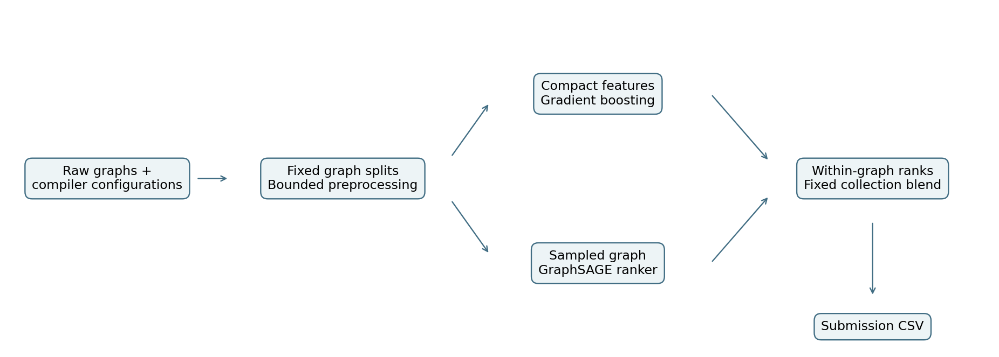

,collection,model,features,target,trees
0,layout:nlp:default,B0_basic_hgb,basic,centered_log,180
1,layout:nlp:random,B0_basic_hgb,basic,centered_log,180
2,layout:xla:default,B0_basic_hgb,basic,centered_log,180
3,layout:xla:random,B0_basic_hgb,basic,centered_log,180
4,tile:xla,B0_basic_hgb,basic,centered_log,180


In [5]:
show("01_method")
baselines = [s for s in CONTRACT["jobs"] if "baseline" in s["roles"] and s["fold"]==0 and s["seed"]==42]
display(pd.DataFrame([{"collection":s["collection"], "model":s["experiment"]["name"],
    "features":", ".join(s["experiment"]["blocks"]), "target":s["experiment"]["target"],
    "trees":s["experiment"].get("iterations",s["cfg"]["hgb_iterations"])} for s in baselines]))


## 3. Exploring model families: do we need graph learning?

We explored three main directions:

| Direction | Motivation | Evidence and decision |
|---|---|---|
| MLP on compact features | A neural predictor without graph message passing | Earlier exploratory results are retained below; their protocol differs from later studies. |
| Gradient boosting | Nonlinear feature interactions with manageable CPU cost | Remains a strong component across collections and the sole final Tile predictor. |
| GraphSAGE | Learn how neighbouring operations interact with configuration choices | Retained in both XLA layout blends; performance varies across collections/folds. |
| Gated GraphSAGE | Learn how much each neighbour contributes | Code exists on an earlier branch, but no verified run result was recovered. It is not presented as a measured success or failure. |

The selected GraphSAGE uses opcode embeddings, numeric/configuration inputs, two width-32
mean-neighbour message-passing layers with residual updates, graph/configurable-node pooling
and a pairwise ranking loss. It is an established architecture, not a new invention.

The chart below uses the **same later development folds** to compare GraphSAGE and a matched-data
HGB control. The basic HGB is a separate baseline with its own budget. We show both folds so
instability is visible. We do not combine the earlier MLP scores into this controlled chart.


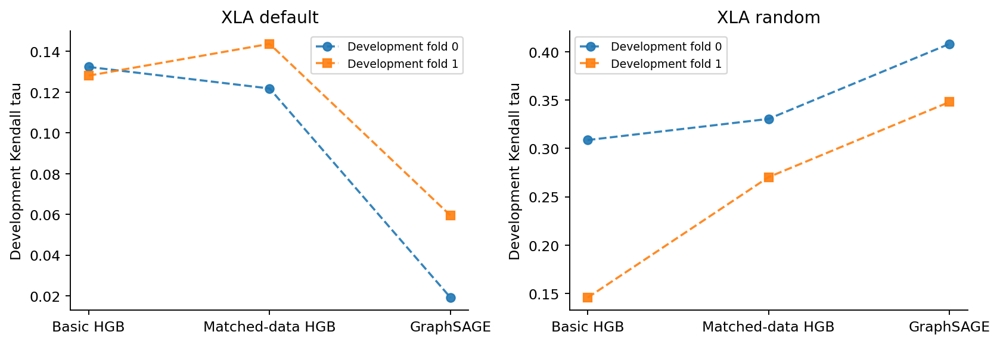

,collection,model,experiment,fold,score
0,layout:xla:default,Basic HGB,B0_basic_hgb,0,0.132386
1,layout:xla:default,Basic HGB,B0_basic_hgb,1,0.128114
2,layout:xla:default,Matched-data HGB,H_matched_gall_c256,0,0.121808
3,layout:xla:default,Matched-data HGB,H_matched_gall_c256,1,0.143715
4,layout:xla:default,GraphSAGE,G_data_gall_c256,0,0.019119
5,layout:xla:default,GraphSAGE,G_data_gall_c256,1,0.059412
6,layout:xla:random,Basic HGB,B0_basic_hgb,0,0.308749
7,layout:xla:random,Basic HGB,B0_basic_hgb,1,0.145481
8,layout:xla:random,Matched-data HGB,H_matched_gall_c128,0,0.330647
9,layout:xla:random,Matched-data HGB,H_matched_gall_c128,1,0.270327


**Earlier exploration only — different protocol; do not compare numerically with the chart above.**

collection,layout:nlp:default,layout:nlp:random,layout:xla:default,layout:xla:random,tile:xla
experiment,,,,,
combined_compact_graph_hgb,0.1621,0.4768,0.2869,0.2178,0.9877
paper_mlp_baseline,0.1002,0.2752,0.1697,0.2469,0.9068
repeated_subgraph_hgb,0.1621,0.4768,0.2814,0.2136,0.9820
simple_summary_ablation,0.1717,0.4900,0.2749,0.2099,0.9801
wl_fingerprint_hgb,0.1621,0.4768,0.2868,0.2178,0.9847


In [6]:
show("02_model_families")
display(table("model_family_comparison"))
with zipfile.ZipFile(io.BytesIO(SPEC_BYTES)) as z:
    early = pd.read_csv(z.open("early_model_exploration.csv"))
display(Markdown("**Earlier exploration only — different protocol; do not compare numerically with the chart above.**"))
display(early.pivot(index="experiment", columns="collection", values="ranking_score").round(4))


**Decision:** keep both compact tabular models and graph learning under investigation.
Neither model family is assumed to win on every collection. The next experiments target
specific possible limitations rather than replacing the whole system blindly.

## 4. Controlled improvements: what worked and what did not?
### 4.1 Representation and message passing

**Question:** do explicit validity masks and context summaries improve the reference GNN?
We compare additions with their named reference and separately examine removal controls.

**Observation:** the displayed confirmed intervals cross zero. These results do not establish
clear standalone gains for masks/context. A selected model can contain them without proving
that each component is independently beneficial. Removal tests ask a different question from
introducing a novel component. The source table names each control so these effects are not
mistakenly added together.

**Decision:** report the uncertainty; retain the development-selected recipe, without inventing
a cumulative improvement story.


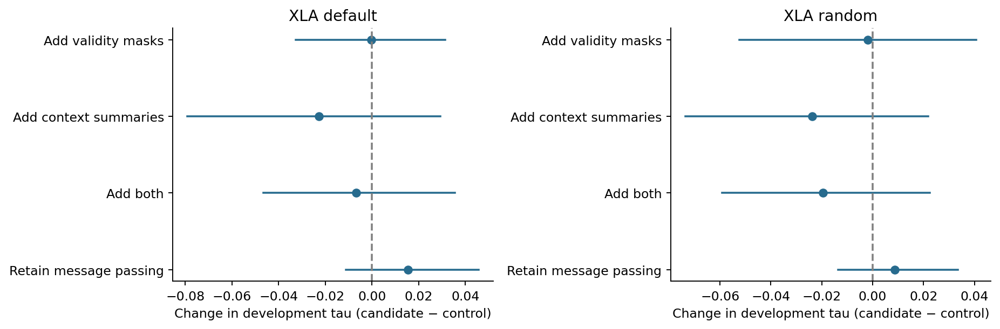

,collection,factor,reference,experiment,baseline_score,candidate_score,absolute_gain,relative_gain_pct,bootstrap_low,bootstrap_high
0,layout:xla:default,mask features,G_reference_n2048,G_masks_n2048,0.050154,0.049804,-0.000350,NaN,-0.032545,0.031336
1,layout:xla:default,context features,G_reference_n2048,G_context_n2048,0.050154,0.027467,-0.022687,NaN,-0.079013,0.029391
2,layout:xla:default,masks and context,G_reference_n2048,G_full_n2048,0.050154,0.043355,-0.006799,NaN,-0.046464,0.035460
3,layout:xla:default,message passing,G_no_messages_n2048,G_full_n2048,0.028053,0.043355,0.015302,NaN,-0.011219,0.045686
4,layout:xla:random,mask features,G_reference_n512,G_masks_n512,0.299705,0.297799,-0.001906,-0.636079,-0.052412,0.040727
5,layout:xla:random,context features,G_reference_n512,G_context_n512,0.299705,0.275848,-0.023857,-7.960243,-0.073662,0.021758
6,layout:xla:random,masks and context,G_reference_n512,G_full_n512,0.299705,0.280126,-0.019579,-6.532849,-0.059079,0.022423
7,layout:xla:random,message passing,G_no_messages_n512,G_full_n512,0.271361,0.280126,0.008765,3.230022,-0.013685,0.033447


In [7]:
show("03_components")
display(table("component_changes")[["collection","factor","reference","experiment",
    "baseline_score","candidate_score","absolute_gain","relative_gain_pct","bootstrap_low","bootstrap_high"]])


### 4.2 Graph coverage and training-data budgets

**Motivation:** severe graph sampling may discard useful structure, and limited training data
may restrict generalization. These are hypotheses, not established explanations of weak scores.

**Experiment:** increase sampled graph budgets; separately vary training graph counts and
configurations per graph. Follow-up work expands tabular training and tests longer GNN training.

**Observation:** larger sampled graphs and more data do not consistently help. Tabular expansion
was accepted for NLP random; existing NLP default/Tile models remained preferable under the
selection rule. Longer GNN training was not accepted. Large resource-excluded Tile settings
were not accuracy failures—they were not successfully evaluated.

**Decision:** use the selected bounded recipes. More retained structure is not automatically
better, and more examples also change optimizer work. These are not compute-matched experiments.


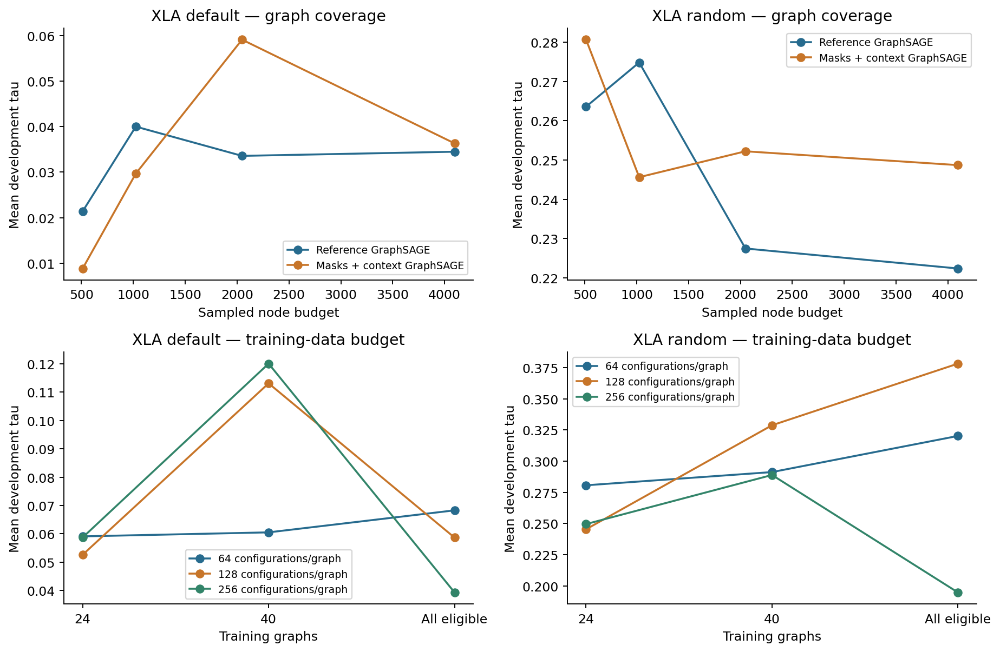

,collection,graphs,configs,score,experiment
0,layout:xla:default,24,64,0.0591,G_full_n2048
1,layout:xla:default,24,128,0.0526,G_data_g24_c128
2,layout:xla:default,24,256,0.0587,G_data_g24_c256
3,layout:xla:default,40,64,0.0605,G_data_g40_c64
4,layout:xla:default,40,128,0.1131,G_data_g40_c128
5,layout:xla:default,40,256,0.1201,G_data_g40_c256
6,layout:xla:default,0,64,0.0683,G_data_gall_c64
7,layout:xla:default,0,128,0.0586,G_data_gall_c128
8,layout:xla:default,0,256,0.0393,G_data_gall_c256
9,layout:xla:random,24,64,0.2807,G_full_n512


In [8]:
show("04_coverage_and_data")
display(table("training_data_screening").round(4))


### 4.3 Target transformation and ranking objectives

**Motivation:** configurations need to be ordered within each graph. Runtime scale varies across
graphs, so we test whether changing the target helps the learner focus on relative performance.

**Controlled tests:** HGB graph-centred log-runtime versus within-graph percentile target;
XGBoost regression versus grouped pairwise ranking with fixed XGBoost capacity. HGB versus XGBoost
also changes learner/capacity and is not an isolated objective ablation. Faster configurations
have higher relevance for XGBoost ranking; its output is negated for our lower-is-faster pipeline.

**Observation:** percentile-target HGB contributes to accepted blends on three collections.
Neither screened XGBoost alternative enters the final system. NLP random illustrates why model
complementarity matters: the percentile model alone is slightly worse on mean development score,
yet blending it with the incumbent improves the combined ranking.

**Decision:** add percentile-target predictions where the blend improves both development folds.
Do not conclude that all pairwise rankers are inferior from one fixed screening setup.


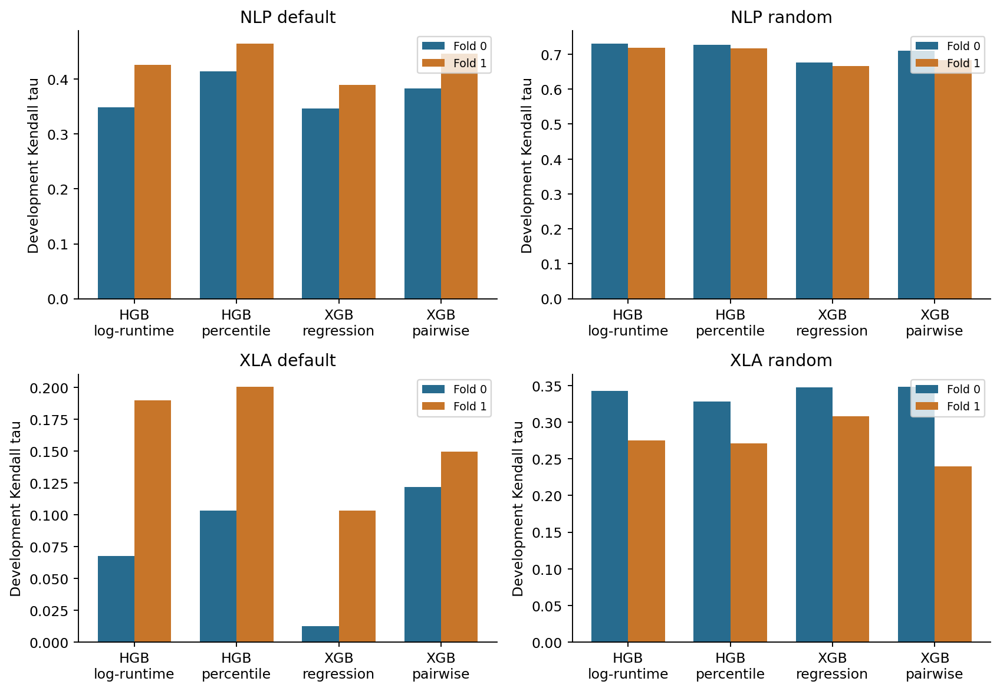

,collection,experiment,fold,seed,dev_score
0,layout:nlp:default,HGB_control,1,42,0.425917
1,layout:nlp:default,HGB_control,0,42,0.348858
2,layout:nlp:default,V5_X_regression,1,42,0.389688
3,layout:nlp:default,V5_H_percentile,1,42,0.464648
4,layout:nlp:default,V5_X_pairwise,1,42,0.446298
5,layout:nlp:default,V5_X_regression,0,42,0.346951
6,layout:nlp:default,V5_H_percentile,0,42,0.414638
7,layout:nlp:default,V5_X_pairwise,0,42,0.382822
8,layout:nlp:random,HGB_control,1,42,0.717840
9,layout:nlp:random,HGB_control,0,42,0.730502


In [9]:
show("05_target_and_objective")
display(table("target_screening")[["collection","experiment","fold","seed","dev_score"]])


## 5. Selecting complementary models and quantifying improvement

A small predefined blend grid was screened on development predictions and promising candidates
confirmed with three seeds. Accepted final updates required mean development gain of at least
0.002 and no regression in either fold. Repeated seeds are not independent graph replications;
some deterministic tree predictions coincide.

Each member's predictions become normalized within-graph ranks before averaging across seeds/folds
and applying the fixed collection weights below. Development scoring uses only the appropriate
fold; the final test ensemble uses both folds. The final recipes are locked: this reproduction
notebook does not retune them on the reused audit or the leaderboard.

**Percentages:** tables show before/after scores and absolute differences. Relative change is
`100 × (after − before) / before`, suppressed for baseline tau below 0.1 where it is misleading.
These are relative score changes, not accuracy percentage points. Ablation gains are not additive.

The target-enhanced NLP-default blend moves reused audit tau from 0.4113 to 0.4536: +0.0423,
about +10.29% relative. This is a blend improvement, not an isolated causal estimate for the target.
The reported public improvement 0.558 → 0.567 is +0.009 (+1.61% relative), with three collections
changing together. It cannot be attributed to one collection from the aggregate score alone.


In [10]:
display(table("selected_recipe"))
display(table("blend_changes")[["collection","dev_gain","baseline_score","candidate_score",
    "absolute_gain","relative_gain_pct","graphs","bootstrap_low","bootstrap_high"]])
display(table("actual_training_sizes").groupby(["collection","experiment","fold"],as_index=False).agg(
    graphs=("graphs","first"),configurations=("configurations","first")))


,collection,model,weight,family,target,nodes,configs,graph_cap
0,NLP default,T_deeper_hgb,0.250,hgb,centered_log,NaN,256,128
1,NLP default,V5_H_percentile,0.750,hgb,percentile,NaN,256,128
2,NLP random,V4_T_gall_c384,0.500,hgb,centered_log,NaN,384,0
3,NLP random,V5_H_percentile,0.500,hgb,percentile,NaN,384,0
4,XLA default,T_full_small,0.375,hgb,centered_log,NaN,256,40
5,XLA default,G_data_gall_c256,0.375,gnn,pairwise,2048.0,256,0
6,XLA default,V5_H_percentile,0.250,hgb,percentile,NaN,256,40
7,XLA random,T_deeper_hgb,0.250,hgb,centered_log,NaN,256,128
8,XLA random,G_data_gall_c128,0.750,gnn,pairwise,512.0,128,0
9,Tile XLA,T_deeper_hgb,1.000,hgb,centered_log,NaN,256,320


,collection,dev_gain,baseline_score,candidate_score,absolute_gain,relative_gain_pct,graphs,bootstrap_low,bootstrap_high
0,layout:nlp:default,0.066477,0.411263,0.453579,0.042316,10.289381,20,0.022174,0.063437
1,layout:nlp:random,0.005016,0.672493,0.684280,0.011787,1.752742,20,0.006799,0.018001
2,layout:xla:default,0.029271,0.035175,0.094348,0.059173,NaN,7,0.031275,0.092724
3,layout:xla:random,0.000000,0.271156,0.271156,0.000000,0.000000,7,0.000000,0.000000


,collection,experiment,fold,graphs,configurations
0,layout:nlp:default,T_deeper_hgb,0,128,32768
1,layout:nlp:default,T_deeper_hgb,1,128,32768
2,layout:nlp:default,V5_H_percentile,0,128,32768
3,layout:nlp:default,V5_H_percentile,1,128,32768
4,layout:nlp:random,V4_T_gall_c384,0,195,74880
5,layout:nlp:random,V4_T_gall_c384,1,195,74880
6,layout:nlp:random,V5_H_percentile,0,195,74880
7,layout:nlp:random,V5_H_percentile,1,195,74880
8,layout:xla:default,G_data_gall_c256,0,49,12544
9,layout:xla:default,G_data_gall_c256,1,49,12544


## 6. Reproduce: load compatible models or train missing models

The executable workflow below validates raw data against fixed split manifests, verifies model
identity and model-file hashes, and trains missing baseline/selected fits. A model-file name alone
is not sufficient for reuse. An optional historical archive is checked against known hashes before
its model objects are loaded. Current-run evaluations always come from model inference.

Feature extraction runs in isolated workers with bounded scratch storage. Only one preparation
group is retained at a time; it is removed after use. Worker RAM and system reserves are monitored.
A resource failure stops the run rather than silently dropping a required final model. A clean
runtime may need several sessions; completed fits are resumable, while an interrupted fit restarts.

`RUN_ABLATIONS=True` additionally runs the recorded successful comparison recipes for the requested
seeds. Seed 42 reruns screening-style comparisons; all three seeds include the recorded confirmations.
It does not recreate resource-excluded jobs or claim to rerun the early MLP/gated branch experiments.
The optional suite never changes the final blend. Its fit-level and per-graph results are saved for
inspection; only matched settings/seeds should be used for causal comparison.

Checkpoints are written every configured interval, at boundaries and on handled interruption.
A browser download request is not confirmed delivery. Keep a completed backup before disconnecting.


In [11]:
if RUN_MODE == "reproduce":
    import reproduce
    selected_jobs = reproduce.plan(CONTRACT, RUN_ABLATIONS, ABLATION_SEEDS)
    print("Selected + baseline fits:", 90)
    print("Total requested fits:", len(selected_jobs), "(existing verified models will be reused)")
    print("Ablations:", RUN_ABLATIONS, "| seeds:", ABLATION_SEEDS)
    display(pd.DataFrame([{"collection":s["collection"], "role":", ".join(s["roles"]),
        "model":s["experiment"]["name"]} for s in selected_jobs]).groupby(["collection","role"]).size().rename("fits").reset_index())
else:
    print("REVIEW: no training plan is executed.")


REVIEW: no training plan is executed.


In [12]:
if RUN_MODE == "reproduce":
    def locate_data():
        bases=([Path(DATA_ROOT)] if DATA_ROOT else [])+[BASE_DIR/"predict-ai-model-runtime",BASE_DIR/"data",BASE_DIR]
        for base in bases:
            for path in [base,base/"npz_all/npz",base/"npz"]:
                if (path/"layout").is_dir() and (path/"tile").is_dir():return path.resolve()
        return None
    NPZ_ROOT=locate_data()
    if NPZ_ROOT is None and DOWNLOAD_IF_MISSING:
        from importlib.metadata import version,PackageNotFoundError
        try:installed=tuple(int(x) for x in version("kagglehub").split(".")[:3])
        except (PackageNotFoundError,ValueError):installed=(0,0,0)
        if installed<(0,4,3):
            subprocess.check_call([sys.executable,"-m","pip","install","--quiet","--no-cache-dir","kagglehub>=0.4.3,<2"])
        try:
            from google.colab import userdata
            for name in ["KAGGLE_USERNAME","KAGGLE_KEY"]:
                if not os.environ.get(name):
                    try:
                        value=userdata.get(name)
                        if value:os.environ[name]=value
                    except Exception:pass
        except ImportError:pass
        if shutil.disk_usage(BASE_DIR).free<25*1024**3:
            raise OSError("Need more free disk before downloading data and saving experiments.")
        import kagglehub
        kagglehub.competition_download("predict-ai-model-runtime",output_dir=str(BASE_DIR/"predict-ai-model-runtime"))
        NPZ_ROOT=locate_data()
    if NPZ_ROOT is None:raise FileNotFoundError("Set DATA_ROOT to the extracted competition data.")
    from study_submission import locate_template
    SAMPLE_SUBMISSION = str(locate_template(NPZ_ROOT, SAMPLE_SUBMISSION))
    if RESTORE_RUN_ZIP:
        from v4_core import restore
        restore(RESTORE_RUN_ZIP, OUTPUT_DIR, 12)
        print("Restored completed work. Clear RESTORE_RUN_ZIP before rerunning this cell in the same runtime.")
    print("Data:", NPZ_ROOT)
    print("Template:", SAMPLE_SUBMISSION)


In [13]:
RUN_STATE = {"status":"review_only"}
def download_checkpoint(path):
    print("Backup:", path, "| bytes:", Path(path).stat().st_size)
    if AUTO_DOWNLOAD_CHECKPOINTS:
        try:
            from google.colab import files
            files.download(str(path))
        except ImportError: print("Outside Colab: copy this backup from its path.")
        except Exception as exc: print("Download request failed:", exc, "— use the Files sidebar.")
    print("Verify the completed ZIP on your computer; local Colab files are temporary.")

if RUN_MODE == "reproduce":
    resources = dict(session_hours=SESSION_HOURS, checkpoint_minutes=CHECKPOINT_MINUTES,
        worker_ram_gib=WORKER_RAM_GIB, system_reserve_gib=SYSTEM_RESERVE_GIB, cpu_threads=CPU_THREADS)
    RUN_STATE = reproduce.run(NPZ_ROOT, OUTPUT_DIR, SCRATCH_DIR, RUNTIME_DIR, CONTRACT,
        resources=resources, model_archive=MODEL_ARCHIVE, run_ablations=RUN_ABLATIONS,
        ablation_seeds=ABLATION_SEEDS, sample_submission=SAMPLE_SUBMISSION,
        on_checkpoint=download_checkpoint)
    print(RUN_STATE)
else:
    print("REVIEW ONLY: historical figures are available; no fresh submission is generated.")


REVIEW ONLY: historical figures are available; no fresh submission is generated.


## 7. Results: historical evidence and this execution

### Historical baseline-to-final comparison

The following figure compares the basic HGB pipeline with the final selected system on the
previously inspected audit graphs. It is a whole-system comparison. Layout and Tile use different
metrics; the panels must not be averaged into an estimated Kaggle score. The final model is not
reselected according to which result looks best on this audit.

Our conclusion is conditional: the chosen combination improves the recorded overall baseline
comparison, but not every proposed change helps. Small audit sets, repeated inspection, sampled
candidate evaluation and multiple tested alternatives limit the strength of generalization claims.


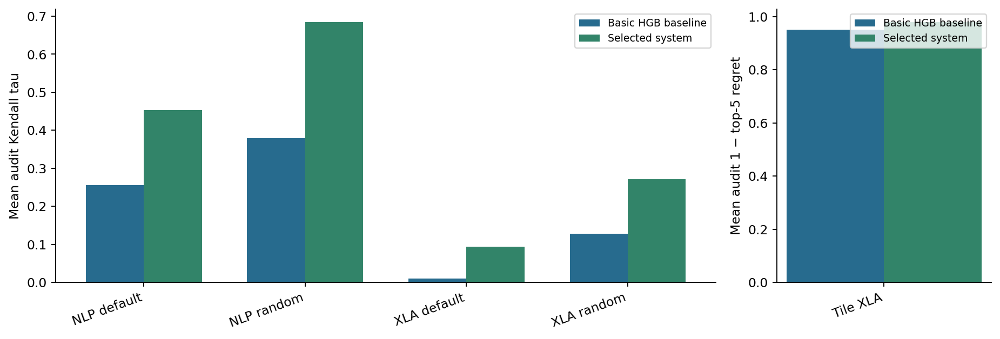

,collection,metric,baseline,selected,graphs,absolute_gain,relative_gain_pct
0,layout:nlp:default,Kendall tau,0.256342,0.453579,20,0.197237,76.943106
1,layout:nlp:random,Kendall tau,0.379548,0.684280,20,0.304732,80.288340
2,layout:xla:default,Kendall tau,0.010947,0.094348,7,0.083401,NaN
3,layout:xla:random,Kendall tau,0.128663,0.271156,7,0.142493,110.749696
4,tile:xla,1 - top5 regret,0.950500,0.979279,24,0.028779,3.027785


,label,score,precision,source
0,Basic baseline,0.400,approximate,user-reported
1,Tabular system,0.530,approximate,user-reported
2,Initial hybrid,0.550,approximate,user-reported
3,Data/training extension,0.558,reported to three decimals,user-reported
4,Final selected system,0.567,reported to three decimals,user-reported


In [14]:
show("06_final_results")
display(table("historical_final_audit"))
display(table("reported_public_scores"))


### Current execution

This section only reports newly evaluated predictions from the models in this run. It does not
substitute the historical score when training is incomplete. Different hardware/library builds
can affect retraining; a new submission's Kaggle score remains unknown until evaluated there.
If every historical model is reused under its recorded environment, the output hash can be
compared with the frozen CSV, but the notebook never forces new predictions to match that CSV.


In [15]:
if RUN_MODE == "reproduce":
    if (OUTPUT_DIR / "evaluation/current_audit.csv").exists():
        display(pd.read_csv(OUTPUT_DIR / "evaluation/current_audit.csv"))
        current_plot = story.current_results(OUTPUT_DIR)
        if current_plot: display(Image(filename=str(current_plot)))
    if RUN_STATE.get("status") == "complete":
        display(json.loads((OUTPUT_DIR / "submission_provenance.json").read_text()))
        print("Fresh Kaggle submission:", OUTPUT_DIR / "submission_final.csv")
        print("Fresh baseline submission:", OUTPUT_DIR / "submission_baseline.csv")
    else:
        print("Run incomplete:", RUN_STATE, "— resume before using a submission.")
else:
    print("No current-run metrics: this execution rendered historical evidence only.")


No current-run metrics: this execution rendered historical evidence only.


## 8. What we learned, limitations and supporting diagnostics

| Finding | Decision |
|---|---|
| Compact boosted trees provide a strong practical reference | Retain them throughout comparisons and in the final system. |
| GraphSAGE contributes complementary predictions on XLA | Use development-selected blends rather than replacing every collection with a GNN. |
| Mask/context standalone gains are inconclusive | Report uncertainty; do not claim each addition independently improves accuracy. |
| Larger graph/data/training budgets are not uniformly better | Keep selected resource-bounded recipes and disclose untested resource exclusions. |
| Percentile-target predictions improve selected blends | Preserve the accepted target-based components; screened XGBoost alternatives are not selected. |

The curves below are **historical selected-GNN diagnostics**, not new training output. Training
loss and early-development tau have different units. There is no recorded validation-loss series,
and these plots cannot prove absence of overfitting. Current GNN histories, when trained here,
are saved beside their model under `models/.../history.csv`.

For the written report, follow these questions and decisions rather than version numbers.
The six main figures are organized in that order; use only those needed within the page limit.
Underlying tables retain original experiment IDs for traceability. Standard HGB, GraphSAGE and
ranking methods are not claimed as inventions. Research notes in the repository acknowledge
prior work; the gated branch is described as implemented but unverified, not invented evidence.


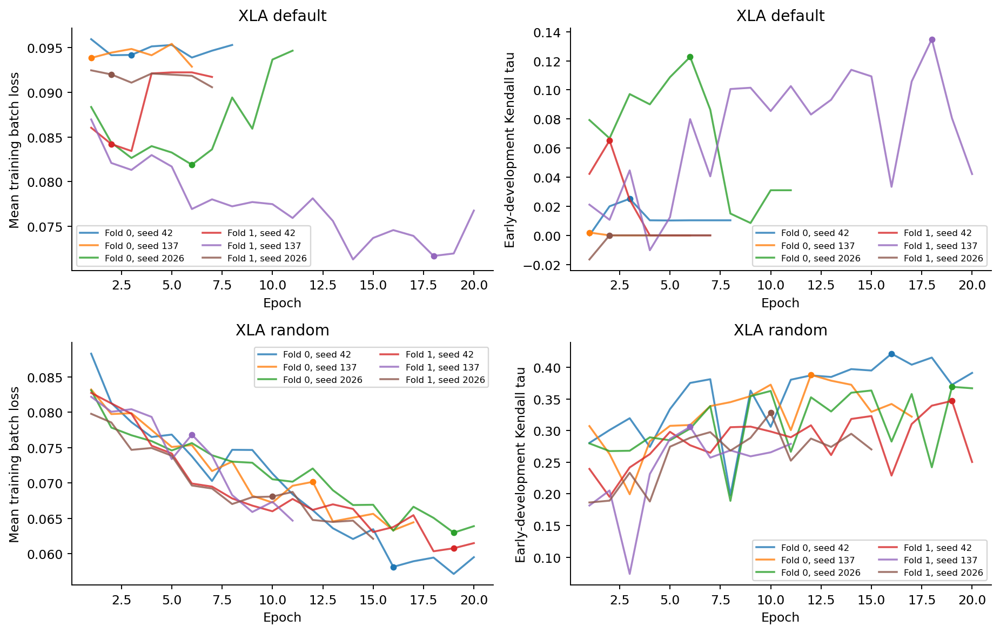

Historical figures/tables/captions: /Users/eugeneng1150/Documents/sc4000/local/outputs/final_reproduction_review/sc4000_final_reproduction_historical_report
Current models, evaluation, provenance and submissions: /Users/eugeneng1150/Documents/sc4000/local/outputs/final_reproduction_review/sc4000_final_reproduction
Keep the completed final-run backup for resuming; the small evidence pack has no model weights.


In [16]:
show("S1_learning_curves")
print("Historical figures/tables/captions:", STORY_DIR)
print("Current models, evaluation, provenance and submissions:", OUTPUT_DIR)
print("Keep the completed final-run backup for resuming; the small evidence pack has no model weights.")
